# Integrated Project 2. Predicting the Gold Recovery Rate

## Project Description

**Goal:** Prepare a machine learning model that predicts the recovery rate of gold from gold-bearing ore. Data with the mining and refining parameters is available. The model is needed to optimize production.

**Tasks:**
1. Prepare the data;
2. Run an exploratory data analysis;
3. Build and train the model.

### Data Description

- Feature names follow the pattern:
    - `[stage].[parameter_type].[parameter_name]`
    **Example:** `rougher.input.feed_ag`
- Possible values of the block [stage]:
    - rougher - flotation
    - primary_cleaner - primary cleaning
    - secondary_cleaner - secondary cleaning
    - final - final characteristics
- Possible values of the block [parameter_type]:
    - input - raw material parameters
    - output - product parameters
    - state - parameters that characterize the current state of the stage
    - calculation - calculated characteristics
- Parameters of the stages:
    - air amount - volume of air
    - fluid levels - liquid level
    - feed size - size of the feed granules
    - feed rate - feed rate

**Plan:**
- 1. Data Preparation
    - 1.1 Data exploration
    - 1.2 Checking the enrichment efficiency calculation
    - 1.3 Analysis of the features that are not available in the test set
    - 1.4 Data preprocessing
- 2. Data Analysis
    - 2.1 Change of the metal concentrations (Au, Ag, Pb)
    - 2.2 Comparison of the feed size distributions
    - 2.3 Study of the total concentrations of substances
- 3. Model
    - 3.1 The final sMAPE function
    - 3.2 Training and evaluating the models
    - 3.3 Testing the model
- 4. Overall Conclusion

# 1. Data Preparation

## 1.1 Data Exploration

In [1]:
import pandas as pd
import numpy as np
import re
from scipy import stats as st
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from numpy.random import RandomState
from scipy import stats

from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression, ElasticNet, Ridge, Lasso
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_squared_error, make_scorer

Load the data from the files, print the first 10 rows of each table for a first look at the data and study the table structure with `info()`: data types, number of rows and columns, missing values.

In [2]:
def data_read_exam(file_path):
    """
    input:        file_path [object] - path to the file
    output:       data [DataFrame] - data table
    description:  the function loads the table with read_csv, prints the first 10 rows,
                  prints the data information with info() and counts the duplicates
    """
    # read the data from the .csv file with read_csv()
    data = pd.read_csv(file_path, index_col = 'date')
    display(data.head(10))
    print(data.info())
    print('Number of duplicates:', sum(data.duplicated()))
    return data

In [3]:
full = data_read_exam('gold_recovery_full.csv')

,final.output.concentrate_ag,final.output.concentrate_pb,final.output.concentrate_sol,final.output.concentrate_au,final.output.recovery,final.output.tail_ag,final.output.tail_pb,final.output.tail_sol,final.output.tail_au,primary_cleaner.input.sulfate,...,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_air,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank5_b_air,secondary_cleaner.state.floatbank5_b_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
date,,,,,,,,,,,,,,,,,,,,,
2016-01-15 00:00:00,6.055403,9.889648,5.507324,42.192020,70.541216,10.411962,0.895447,16.904297,2.143149,127.092003,...,14.016835,-502.488007,12.099931,-504.715942,9.925633,-498.310211,8.079666,-500.470978,14.151341,-605.841980
2016-01-15 01:00:00,6.029369,9.968944,5.257781,42.701629,69.266198,10.462676,0.927452,16.634514,2.224930,125.629232,...,13.992281,-505.503262,11.950531,-501.331529,10.039245,-500.169983,7.984757,-500.582168,13.998353,-599.787184
2016-01-15 02:00:00,6.055926,10.213995,5.383759,42.657501,68.116445,10.507046,0.953716,16.208849,2.257889,123.819808,...,14.015015,-502.520901,11.912783,-501.133383,10.070913,-500.129135,8.013877,-500.517572,14.028663,-601.427363
2016-01-15 03:00:00,6.047977,9.977019,4.858634,42.689819,68.347543,10.422762,0.883763,16.532835,2.146849,122.270188,...,14.036510,-500.857308,11.999550,-501.193686,9.970366,-499.201640,7.977324,-500.255908,14.005551,-599.996129
2016-01-15 04:00:00,6.148599,10.142511,4.939416,42.774141,66.927016,10.360302,0.792826,16.525686,2.055292,117.988169,...,14.027298,-499.838632,11.953070,-501.053894,9.925709,-501.686727,7.894242,-500.356035,13.996647,-601.496691
2016-01-15 05:00:00,6.482968,10.049416,5.480257,41.633678,69.465816,10.182708,0.664118,16.999638,1.918586,115.581252,...,13.938497,-500.970168,11.883350,-500.395298,10.054147,-496.374715,7.965083,-499.364752,14.017067,-599.707915
2016-01-15 06:00:00,6.533849,10.058141,4.569100,41.995316,69.300835,10.304598,0.807342,16.723575,2.058913,117.322323,...,14.046819,-500.971133,12.091543,-500.501426,10.003247,-497.083180,8.010890,-500.002423,14.029649,-600.905470
2016-01-15 07:00:00,6.130823,9.935481,4.389813,42.452727,70.230976,10.443288,0.949346,16.689959,2.143437,124.592960,...,13.974691,-501.819696,12.101324,-500.583446,9.873169,-499.171928,7.993381,-499.794518,13.984498,-600.411070
2016-01-15 08:00:00,5.834140,10.071156,4.876389,43.404078,69.688595,10.420140,1.065453,17.201948,2.209881,131.781026,...,13.964030,-504.252450,12.060738,-501.174549,10.033838,-501.178133,7.881604,-499.729434,13.967135,-599.061188


<class 'pandas.core.frame.DataFrame'>
Index: 19439 entries, 2016-01-15 00:00:00 to 2018-08-18 10:59:59
Data columns (total 86 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   final.output.concentrate_ag                         19438 non-null  float64
 1   final.output.concentrate_pb                         19438 non-null  float64
 2   final.output.concentrate_sol                        19228 non-null  float64
 3   final.output.concentrate_au                         19439 non-null  float64
 4   final.output.recovery                               19439 non-null  float64
 5   final.output.tail_ag                                19438 non-null  float64
 6   final.output.tail_pb                                19338 non-null  float64
 7   final.output.tail_sol                               19433 non-null  float64
 8   final.output.tail_au                             

In [4]:
train = data_read_exam('gold_recovery_train.csv')

,final.output.concentrate_ag,final.output.concentrate_pb,final.output.concentrate_sol,final.output.concentrate_au,final.output.recovery,final.output.tail_ag,final.output.tail_pb,final.output.tail_sol,final.output.tail_au,primary_cleaner.input.sulfate,...,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_air,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank5_b_air,secondary_cleaner.state.floatbank5_b_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
date,,,,,,,,,,,,,,,,,,,,,
2016-01-15 00:00:00,6.055403,9.889648,5.507324,42.192020,70.541216,10.411962,0.895447,16.904297,2.143149,127.092003,...,14.016835,-502.488007,12.099931,-504.715942,9.925633,-498.310211,8.079666,-500.470978,14.151341,-605.841980
2016-01-15 01:00:00,6.029369,9.968944,5.257781,42.701629,69.266198,10.462676,0.927452,16.634514,2.224930,125.629232,...,13.992281,-505.503262,11.950531,-501.331529,10.039245,-500.169983,7.984757,-500.582168,13.998353,-599.787184
2016-01-15 02:00:00,6.055926,10.213995,5.383759,42.657501,68.116445,10.507046,0.953716,16.208849,2.257889,123.819808,...,14.015015,-502.520901,11.912783,-501.133383,10.070913,-500.129135,8.013877,-500.517572,14.028663,-601.427363
2016-01-15 03:00:00,6.047977,9.977019,4.858634,42.689819,68.347543,10.422762,0.883763,16.532835,2.146849,122.270188,...,14.036510,-500.857308,11.999550,-501.193686,9.970366,-499.201640,7.977324,-500.255908,14.005551,-599.996129
2016-01-15 04:00:00,6.148599,10.142511,4.939416,42.774141,66.927016,10.360302,0.792826,16.525686,2.055292,117.988169,...,14.027298,-499.838632,11.953070,-501.053894,9.925709,-501.686727,7.894242,-500.356035,13.996647,-601.496691
2016-01-15 05:00:00,6.482968,10.049416,5.480257,41.633678,69.465816,10.182708,0.664118,16.999638,1.918586,115.581252,...,13.938497,-500.970168,11.883350,-500.395298,10.054147,-496.374715,7.965083,-499.364752,14.017067,-599.707915
2016-01-15 06:00:00,6.533849,10.058141,4.569100,41.995316,69.300835,10.304598,0.807342,16.723575,2.058913,117.322323,...,14.046819,-500.971133,12.091543,-500.501426,10.003247,-497.083180,8.010890,-500.002423,14.029649,-600.905470
2016-01-15 07:00:00,6.130823,9.935481,4.389813,42.452727,70.230976,10.443288,0.949346,16.689959,2.143437,124.592960,...,13.974691,-501.819696,12.101324,-500.583446,9.873169,-499.171928,7.993381,-499.794518,13.984498,-600.411070
2016-01-15 08:00:00,5.834140,10.071156,4.876389,43.404078,69.688595,10.420140,1.065453,17.201948,2.209881,131.781026,...,13.964030,-504.252450,12.060738,-501.174549,10.033838,-501.178133,7.881604,-499.729434,13.967135,-599.061188


<class 'pandas.core.frame.DataFrame'>
Index: 14149 entries, 2016-01-15 00:00:00 to 2018-08-18 10:59:59
Data columns (total 86 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   final.output.concentrate_ag                         14148 non-null  float64
 1   final.output.concentrate_pb                         14148 non-null  float64
 2   final.output.concentrate_sol                        13938 non-null  float64
 3   final.output.concentrate_au                         14149 non-null  float64
 4   final.output.recovery                               14149 non-null  float64
 5   final.output.tail_ag                                14149 non-null  float64
 6   final.output.tail_pb                                14049 non-null  float64
 7   final.output.tail_sol                               14144 non-null  float64
 8   final.output.tail_au                             

In [5]:
test = data_read_exam('gold_recovery_test.csv')

,primary_cleaner.input.sulfate,primary_cleaner.input.depressant,primary_cleaner.input.feed_size,primary_cleaner.input.xanthate,primary_cleaner.state.floatbank8_a_air,primary_cleaner.state.floatbank8_a_level,primary_cleaner.state.floatbank8_b_air,primary_cleaner.state.floatbank8_b_level,primary_cleaner.state.floatbank8_c_air,primary_cleaner.state.floatbank8_c_level,...,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_air,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank5_b_air,secondary_cleaner.state.floatbank5_b_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
date,,,,,,,,,,,,,,,,,,,,,
2016-09-01 00:59:59,210.800909,14.993118,8.080000,1.005021,1398.981301,-500.225577,1399.144926,-499.919735,1400.102998,-500.704369,...,12.023554,-497.795834,8.016656,-501.289139,7.946562,-432.317850,4.872511,-500.037437,26.705889,-499.709414
2016-09-01 01:59:59,215.392455,14.987471,8.080000,0.990469,1398.777912,-500.057435,1398.055362,-499.778182,1396.151033,-499.240168,...,12.058140,-498.695773,8.130979,-499.634209,7.958270,-525.839648,4.878850,-500.162375,25.019940,-499.819438
2016-09-01 02:59:59,215.259946,12.884934,7.786667,0.996043,1398.493666,-500.868360,1398.860436,-499.764529,1398.075709,-502.151509,...,11.962366,-498.767484,8.096893,-500.827423,8.071056,-500.801673,4.905125,-499.828510,24.994862,-500.622559
2016-09-01 03:59:59,215.336236,12.006805,7.640000,0.863514,1399.618111,-498.863574,1397.440120,-499.211024,1400.129303,-498.355873,...,12.033091,-498.350935,8.074946,-499.474407,7.897085,-500.868509,4.931400,-499.963623,24.948919,-498.709987
2016-09-01 04:59:59,199.099327,10.682530,7.530000,0.805575,1401.268123,-500.808305,1398.128818,-499.504543,1402.172226,-500.810606,...,12.025367,-500.786497,8.054678,-500.397500,8.107890,-509.526725,4.957674,-500.360026,25.003331,-500.856333
2016-09-01 05:59:59,168.485085,8.817007,7.420000,0.791191,1402.826803,-499.299521,1401.511119,-499.205357,1404.088107,-497.903666,...,12.029797,-499.814895,8.036586,-500.371492,8.041446,-510.037054,4.983949,-499.990990,24.978973,-500.475640
2016-09-01 06:59:59,144.133440,7.924610,7.420000,0.788838,1398.252401,-499.748672,1393.255503,-499.195380,1396.738566,-497.923683,...,12.026296,-499.473127,8.027984,-500.983079,7.907340,-507.964971,5.010224,-500.043697,25.040709,-499.501984
2016-09-01 07:59:59,133.513396,8.055252,6.988000,0.801871,1401.669677,-501.777839,1400.754446,-502.514024,1400.465244,-503.451306,...,12.040911,-501.293852,8.020490,-499.185229,8.116897,-511.927561,5.036498,-500.149615,25.032580,-503.970657
2016-09-01 08:59:59,133.735356,7.999618,6.935000,0.789329,1402.358981,-499.981597,1400.985954,-496.802968,1401.168584,-499.890350,...,11.998184,-499.481608,8.012610,-500.896783,7.974422,-521.199104,5.061599,-499.791519,25.005063,-497.613716


<class 'pandas.core.frame.DataFrame'>
Index: 5290 entries, 2016-09-01 00:59:59 to 2017-12-31 23:59:59
Data columns (total 52 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   primary_cleaner.input.sulfate               5286 non-null   float64
 1   primary_cleaner.input.depressant            5285 non-null   float64
 2   primary_cleaner.input.feed_size             5290 non-null   float64
 3   primary_cleaner.input.xanthate              5286 non-null   float64
 4   primary_cleaner.state.floatbank8_a_air      5290 non-null   float64
 5   primary_cleaner.state.floatbank8_a_level    5290 non-null   float64
 6   primary_cleaner.state.floatbank8_b_air      5290 non-null   float64
 7   primary_cleaner.state.floatbank8_b_level    5290 non-null   float64
 8   primary_cleaner.state.floatbank8_c_air      5290 non-null   float64
 9   primary_cleaner.state.floatbank8_c_level    5290 non-null

- The data matches the description. There are no duplicates. The full table has **19439 objects** and **86 features** (14149 objects in the training set and 5290 in the test set).
- The missing values need further study.
- The data types match the description.
- Look at the distributions of the data in the original table.

- First, remove the objects where more than half of the features are missing. Such records do not help to build the model.

In [6]:
train = train.drop(train.loc[(~train
                              .isnull())
                             .sum(axis=1) < 44]
                   .index,
                   axis = 0)
test = test.drop(test.loc[(~test
                           .isnull())
                          .sum(axis=1) < 28]
                 .index,
                 axis = 0)

In [7]:
def show_hists(data, data_label, num_bins, rug=False, log_scale=False):
    """
    input: data - data to plot the histogram for
           data_label - description of the data
           num_bins - number of bins
    output: None
    description: The function plots a histogram and a violin plot for the selected parameter:
                - Density (seaborn's distplot())
                - Violin plot (seaborn's violinplot())
    """
    sns.set()
    f, axes = plt.subplots(1, 2, figsize=(16, 4))
    axes[0].set_title(data_label + ". Density", fontsize=18)
    axes[0].set_ylabel('density', fontsize=15)
    sns.distplot(data, bins=num_bins, rug=rug, ax=axes[0])
    sns.violinplot(data=data, ax=axes[1])
    plt.show()

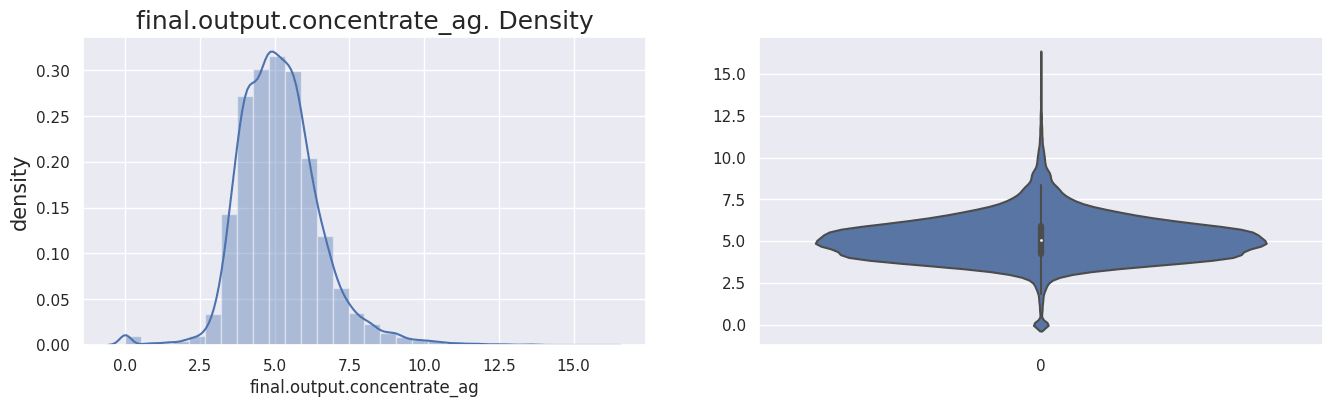

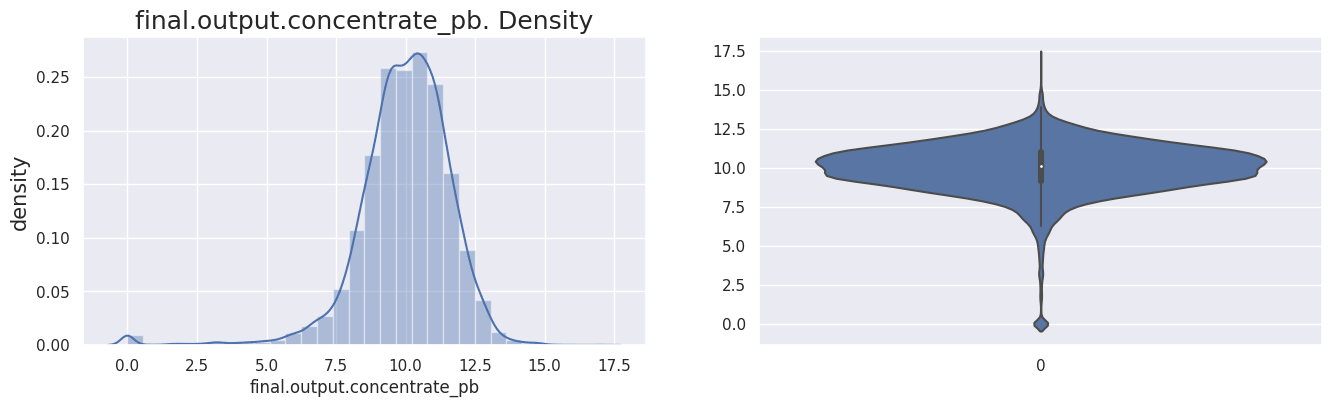

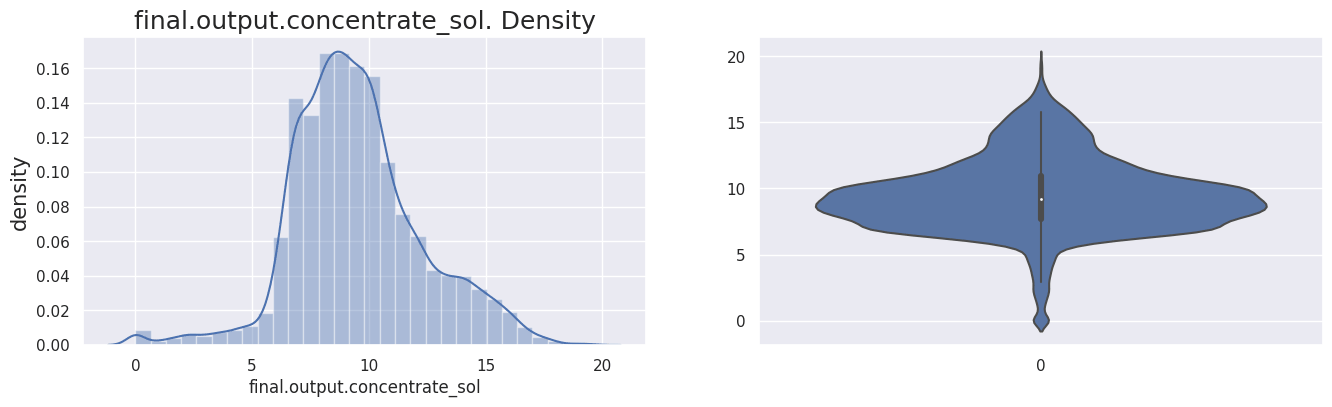

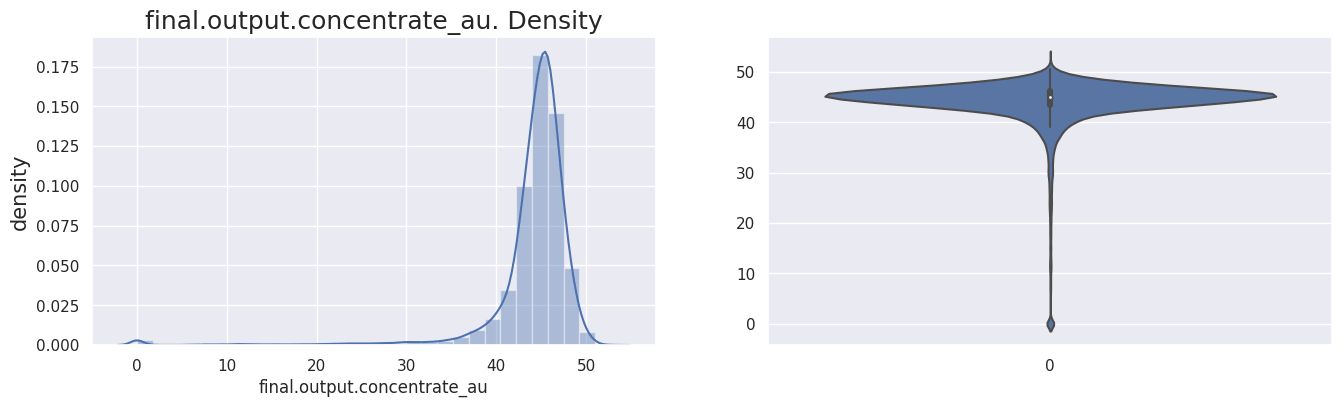

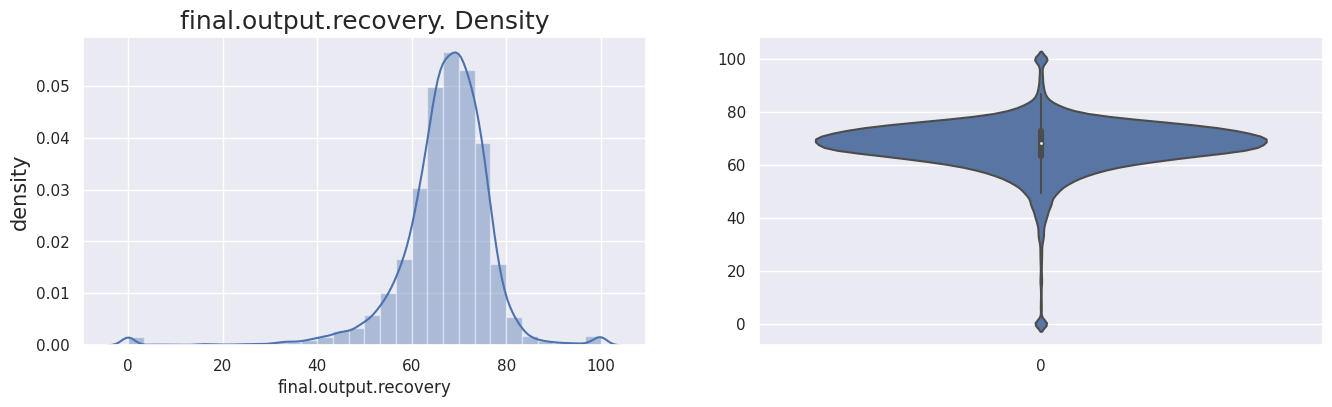

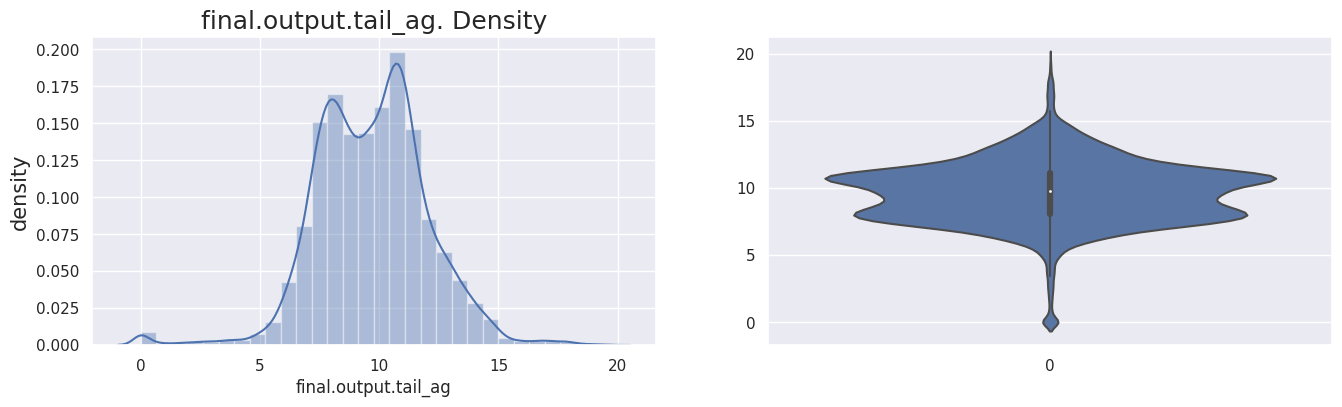

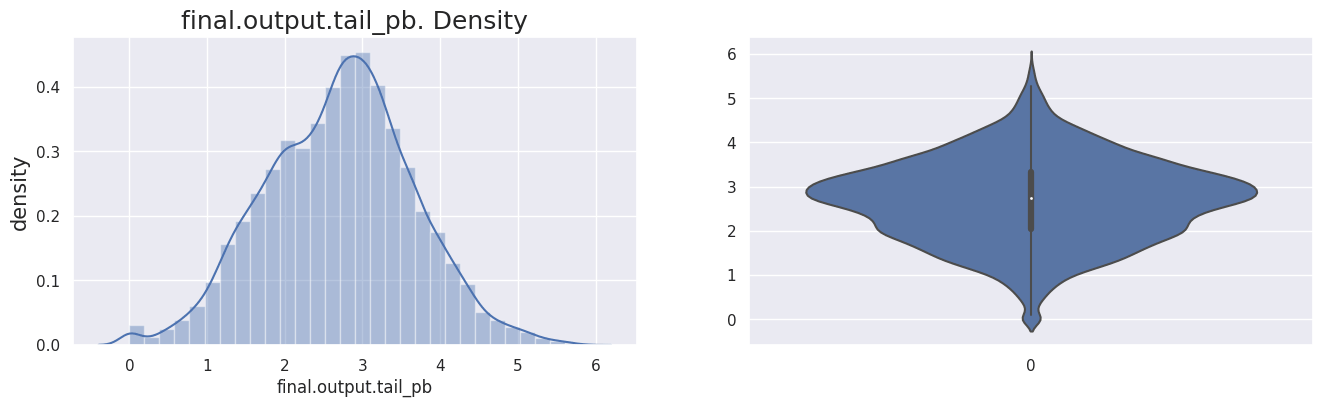

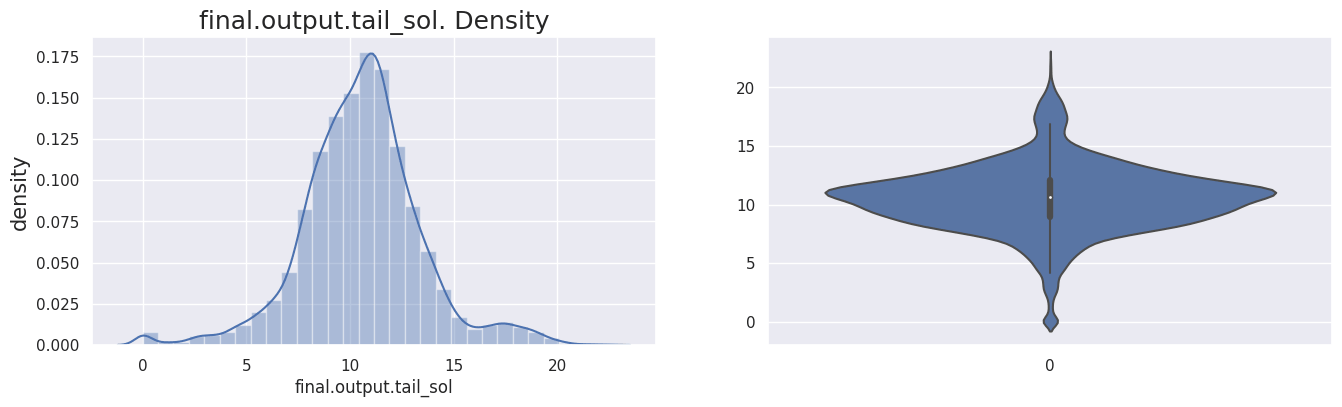

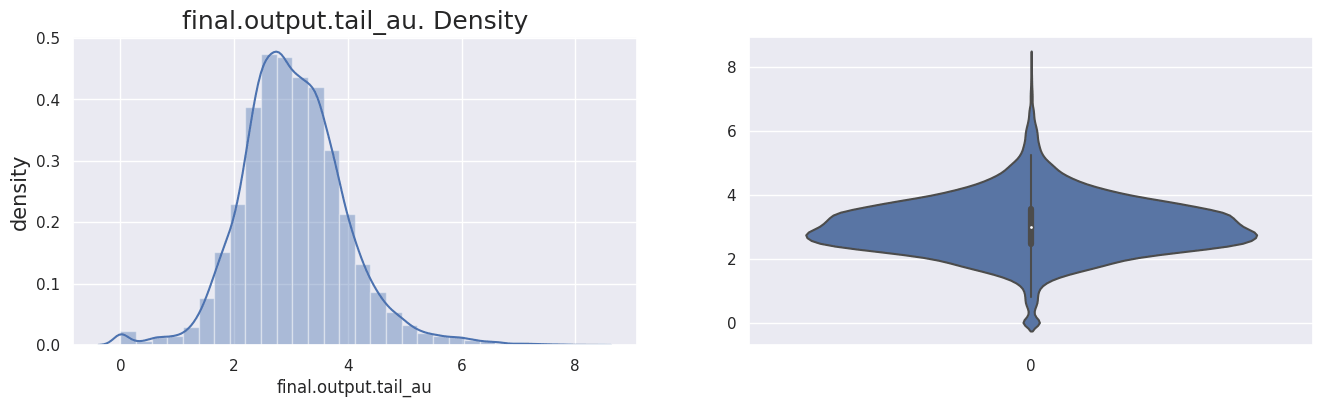

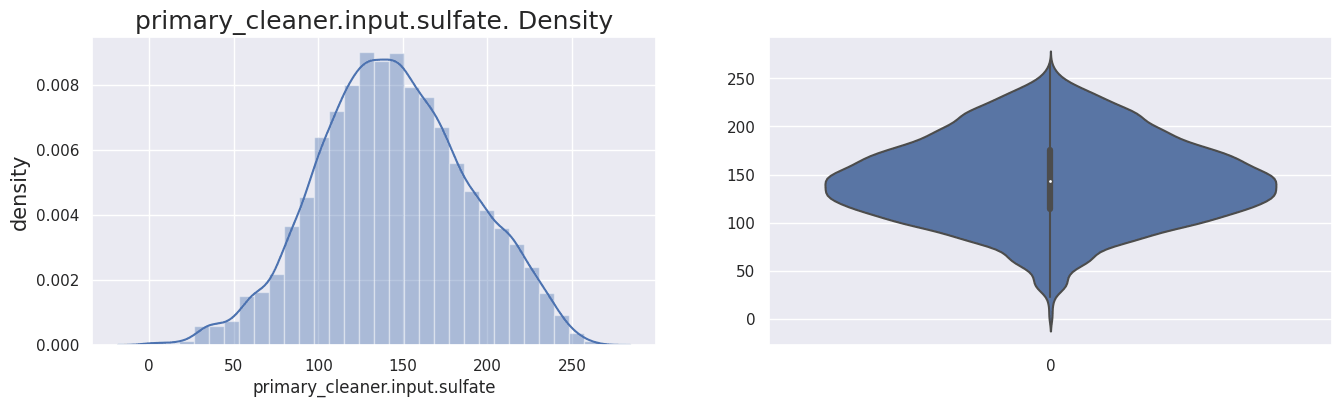

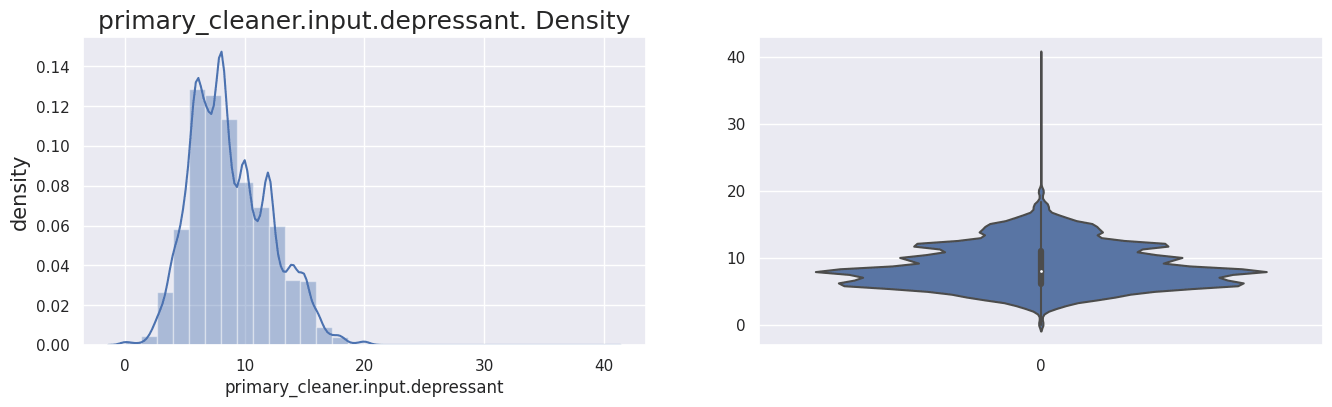

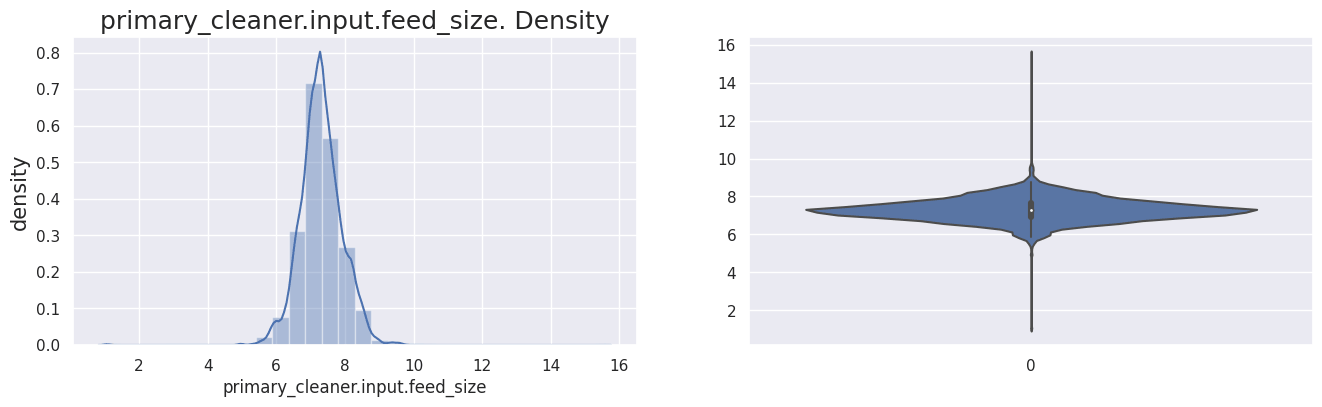

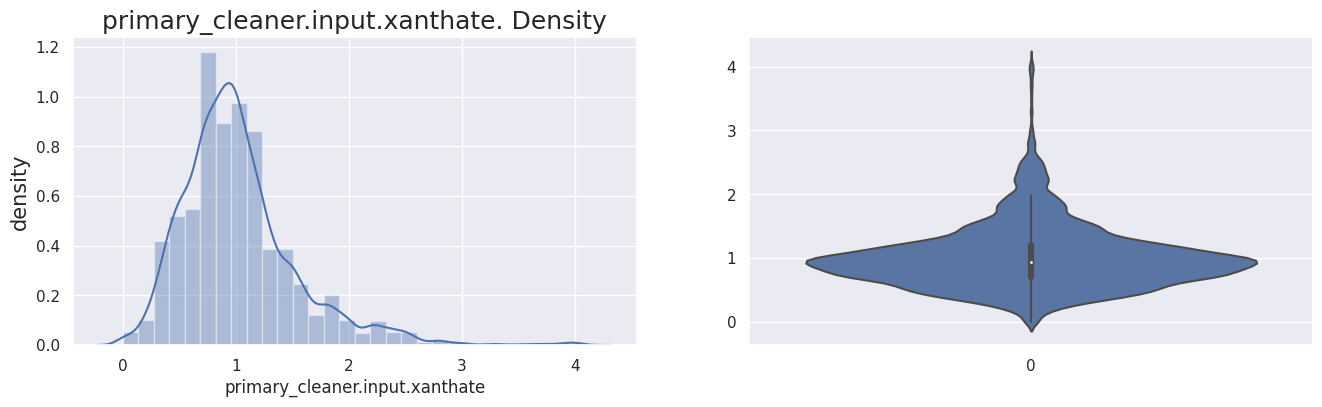

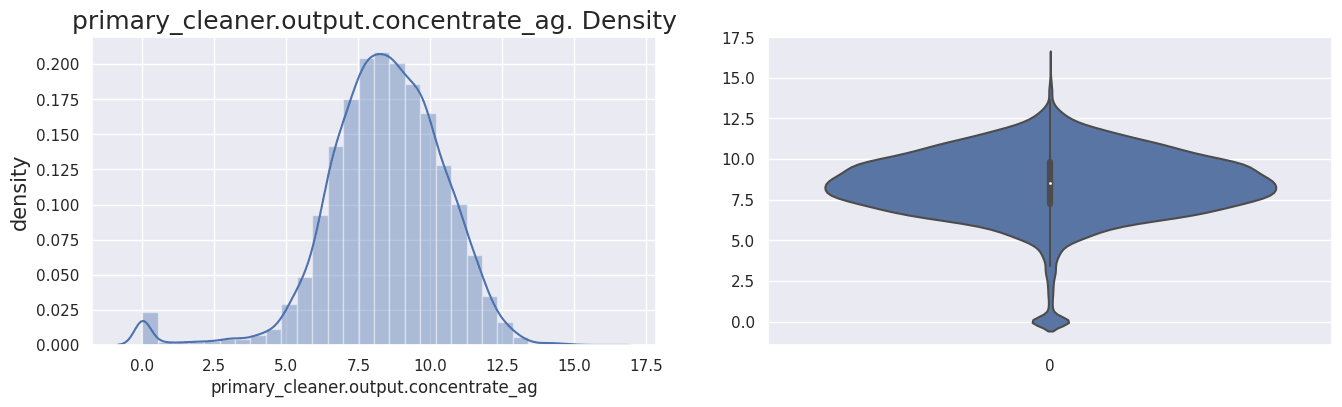

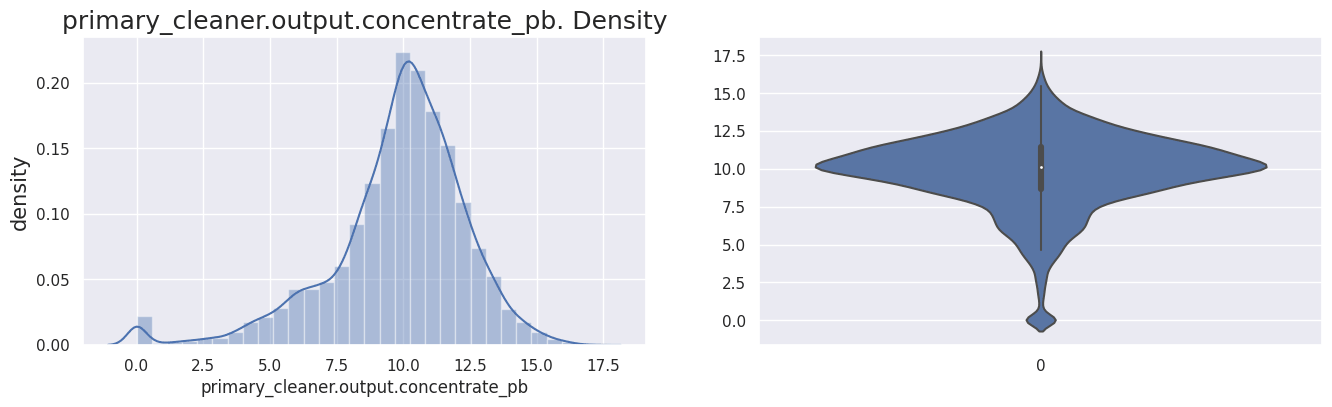

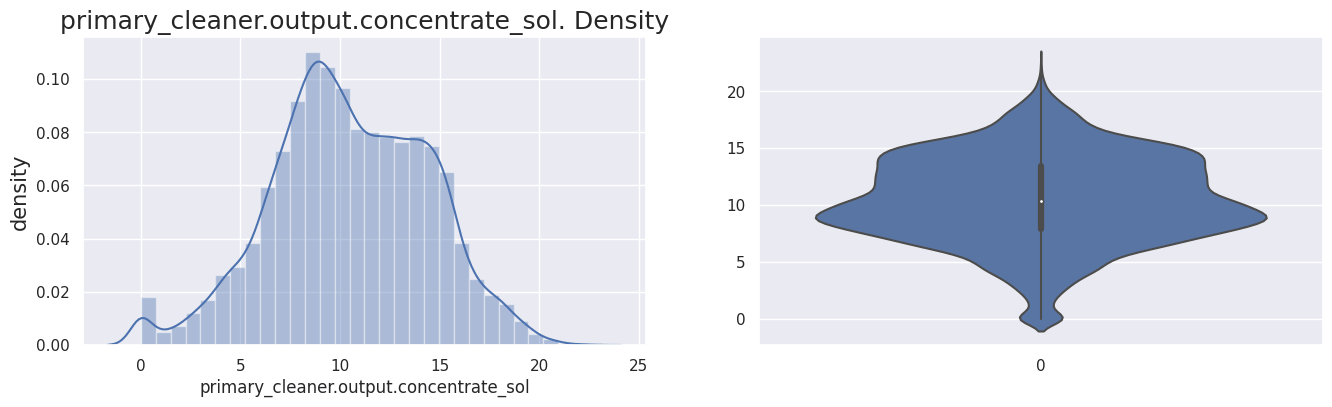

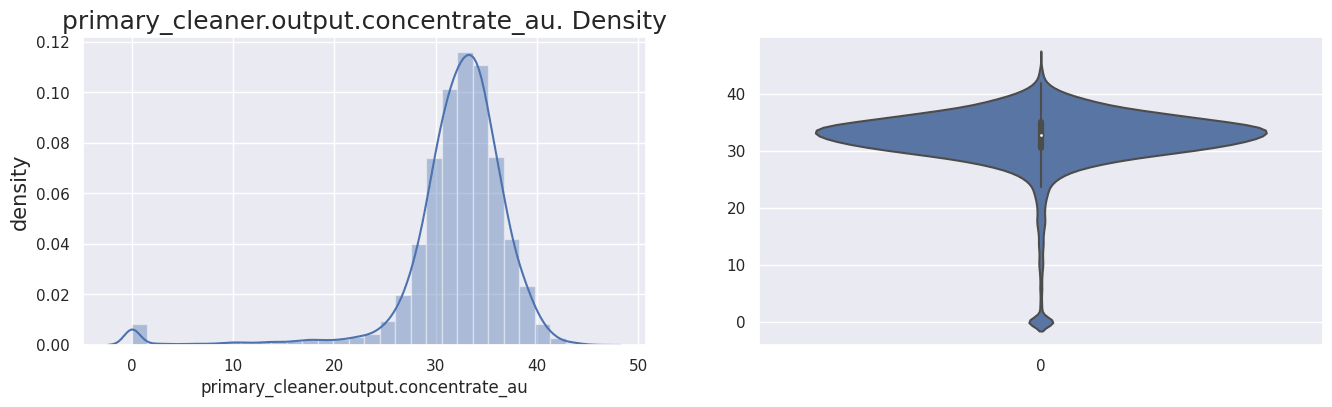

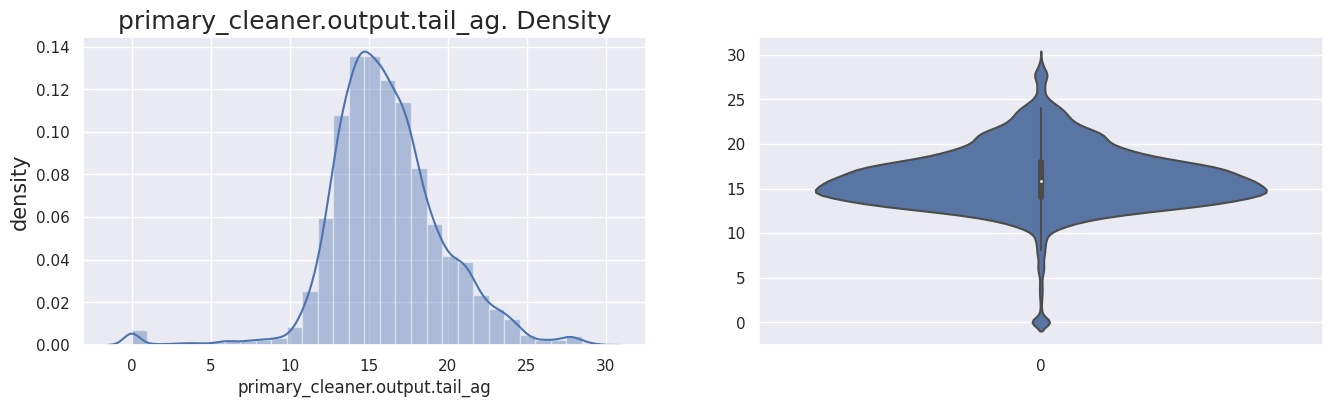

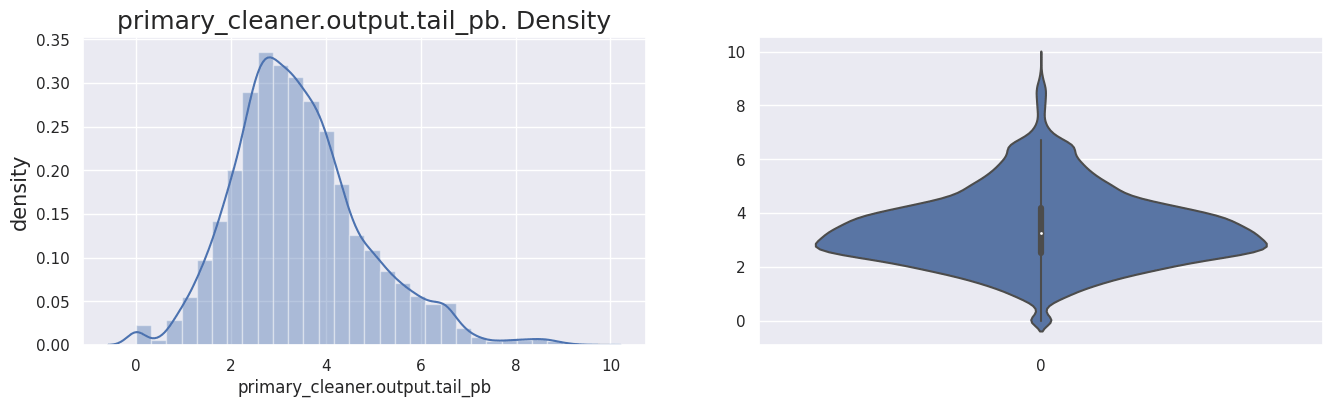

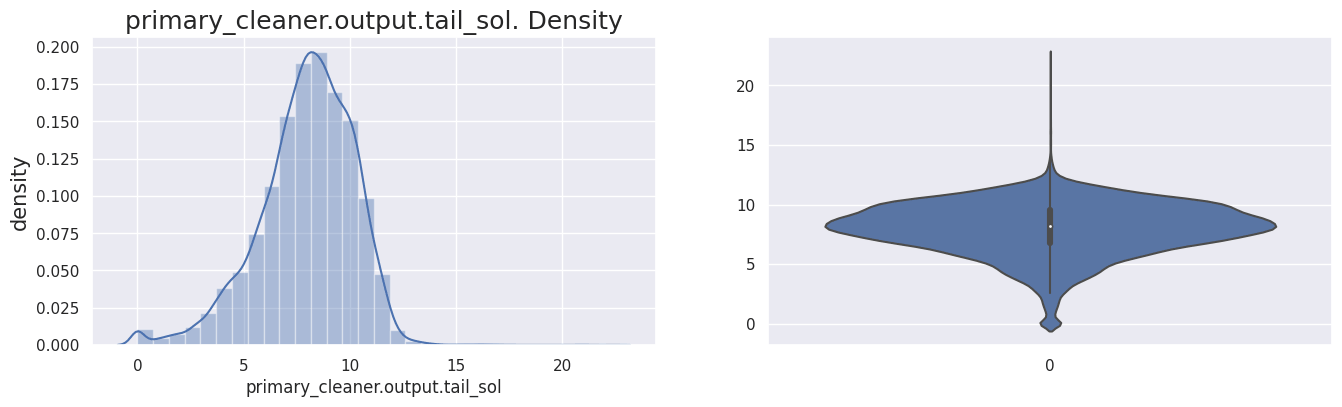

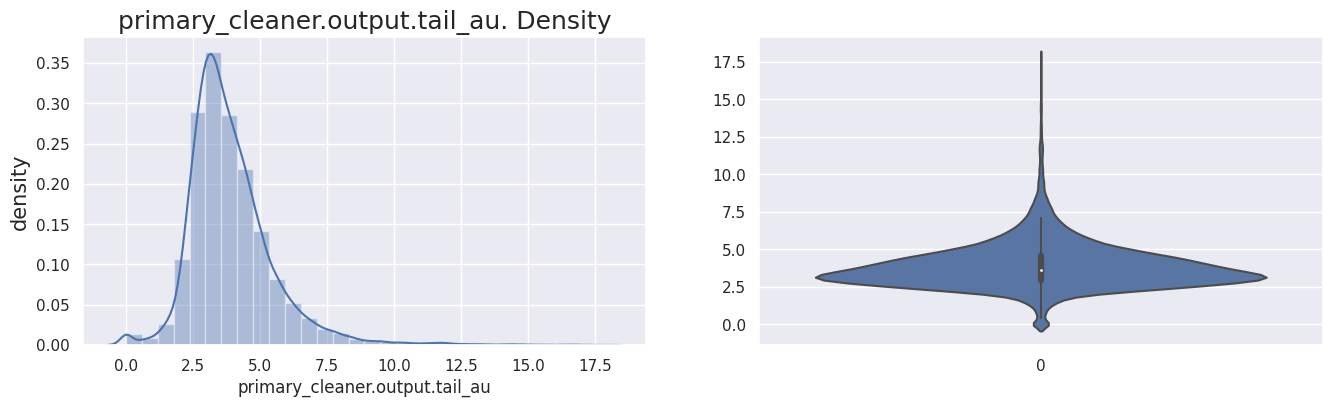

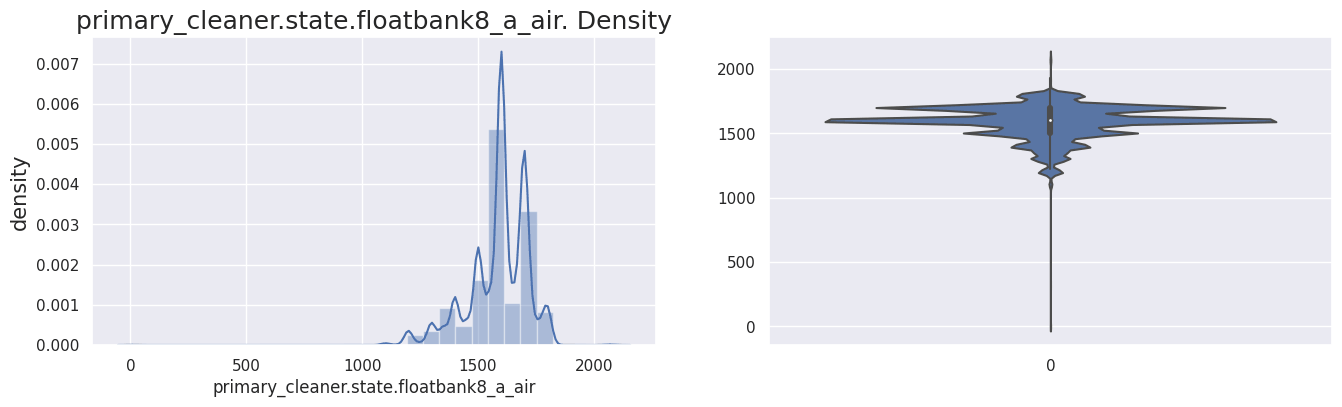

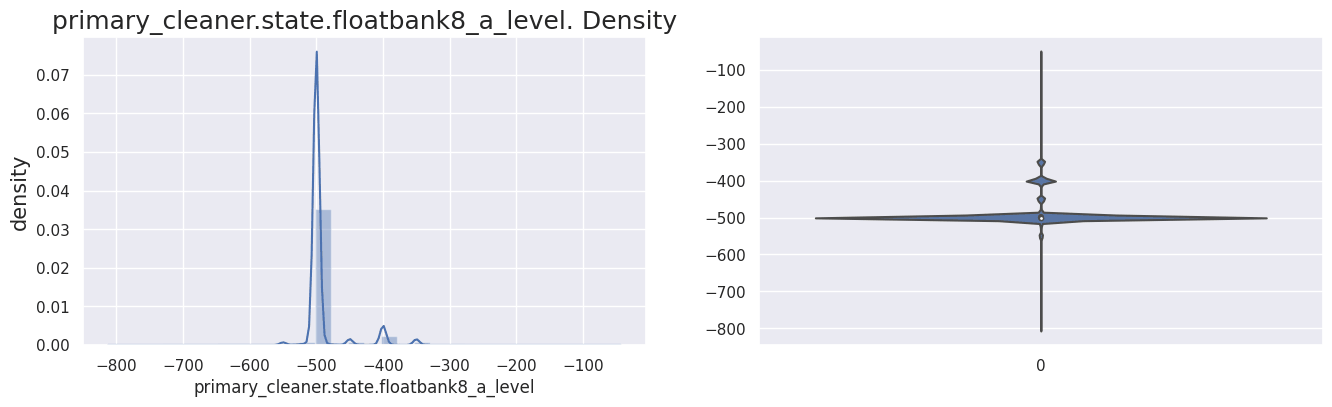

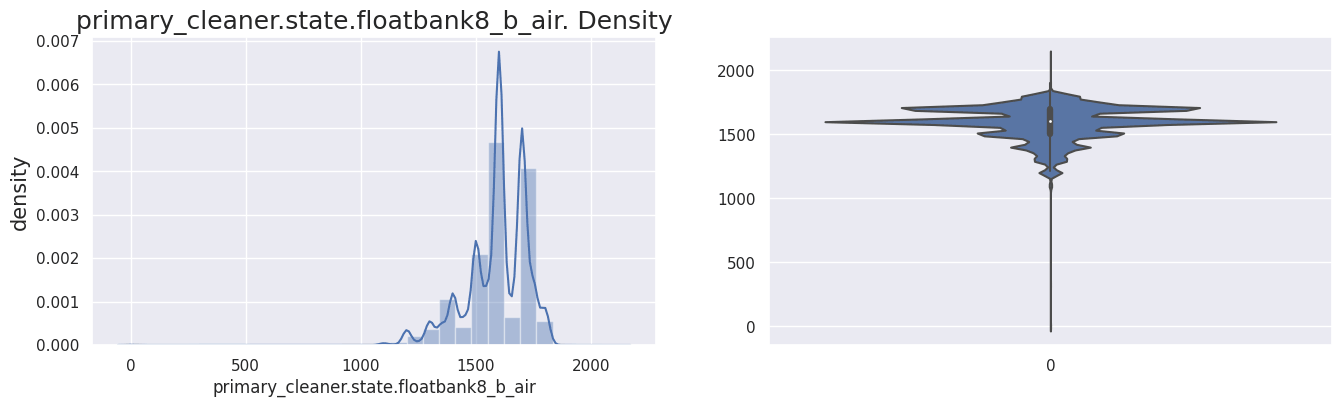

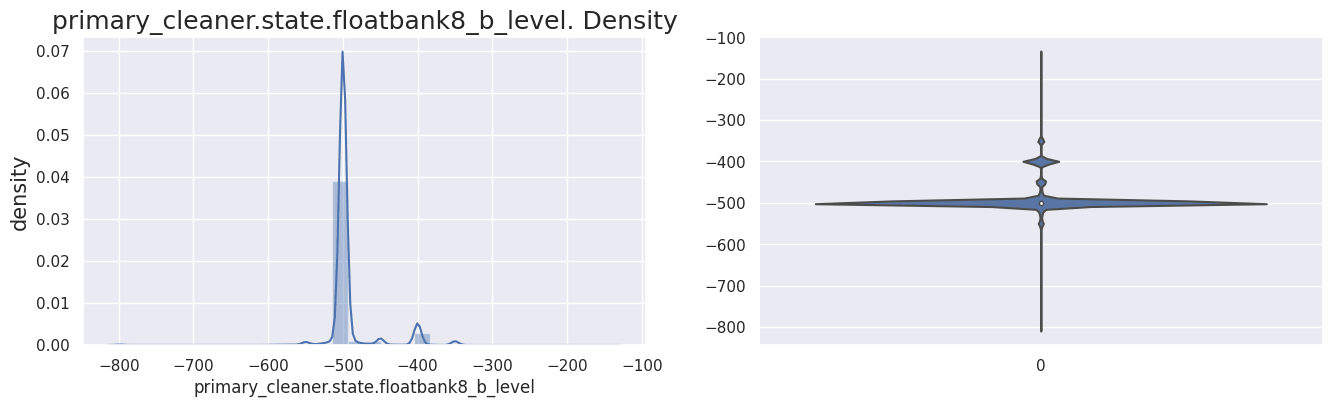

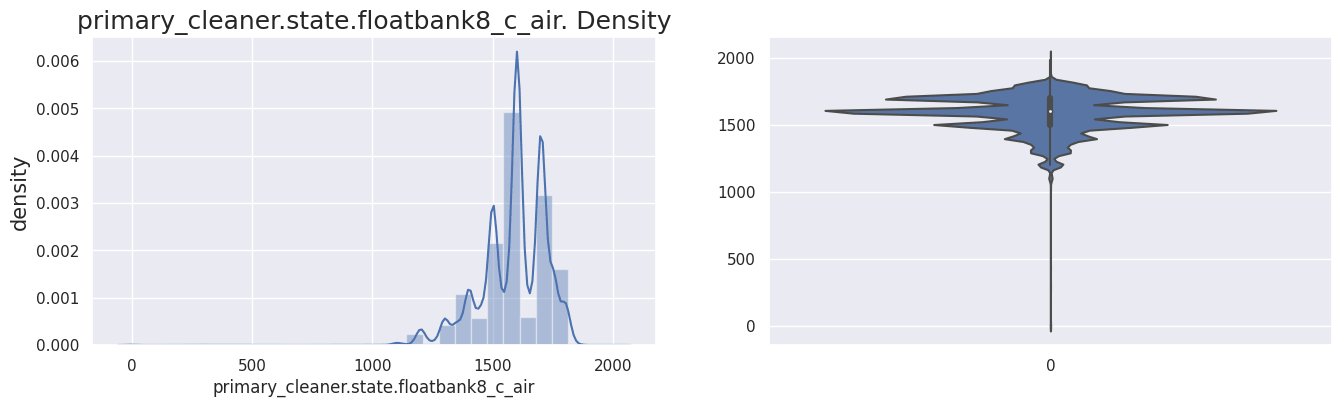

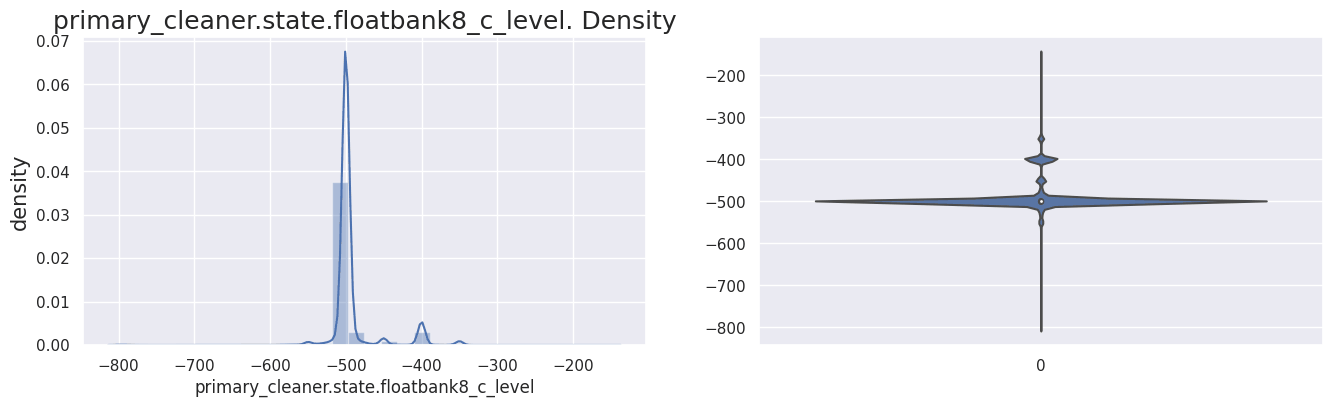

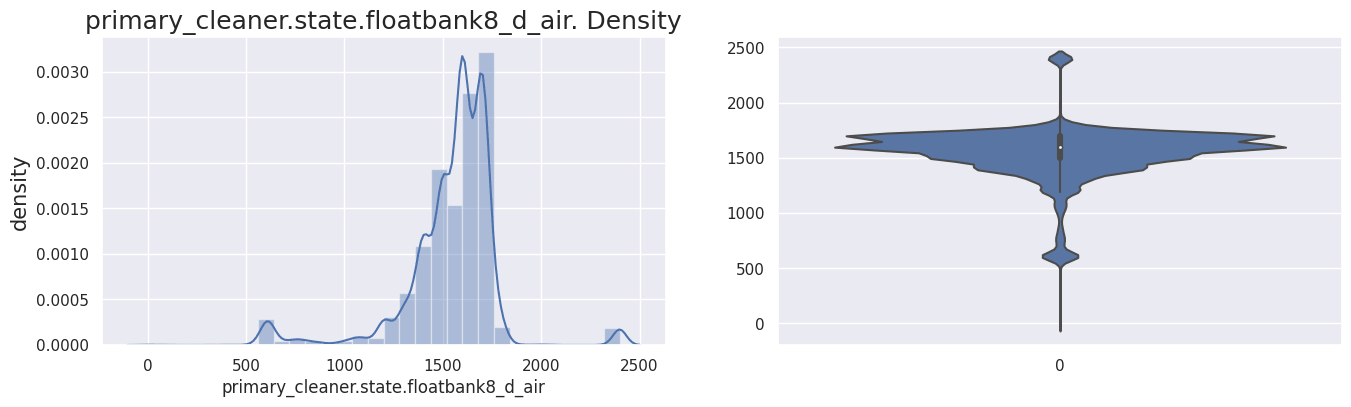

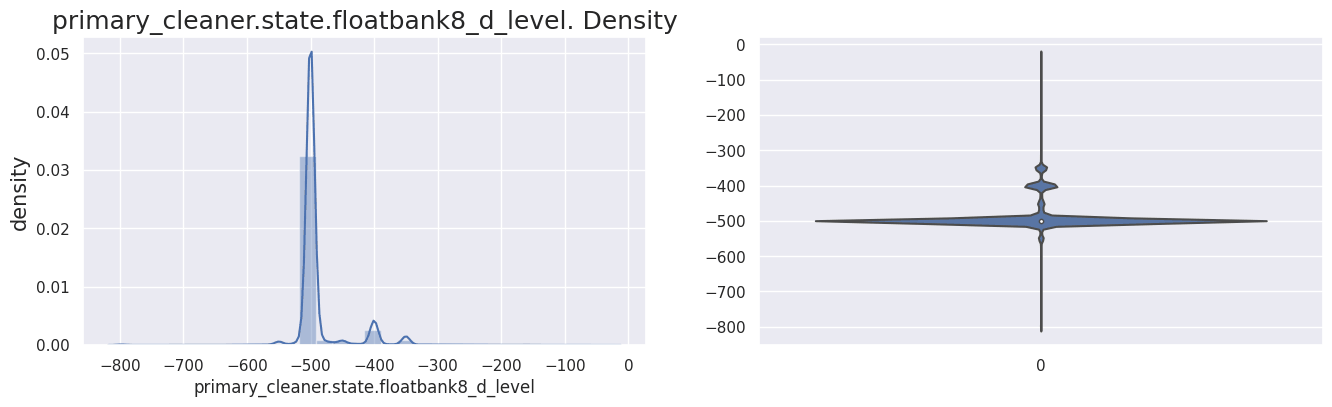

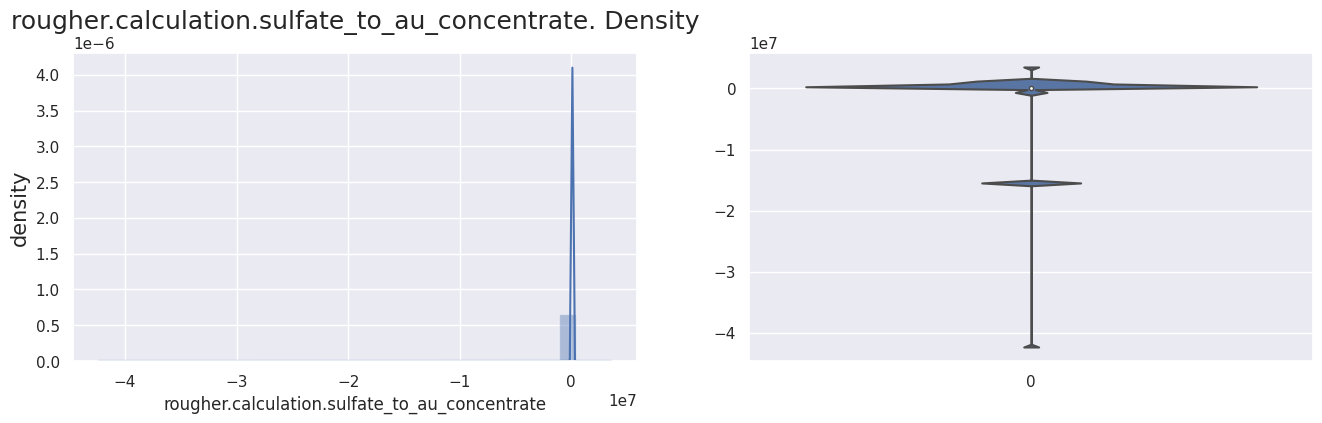

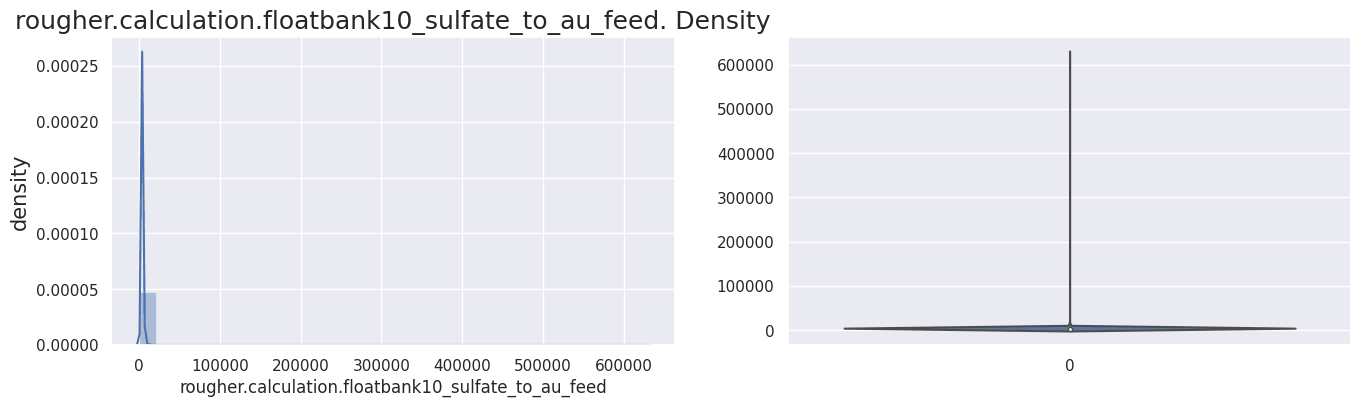

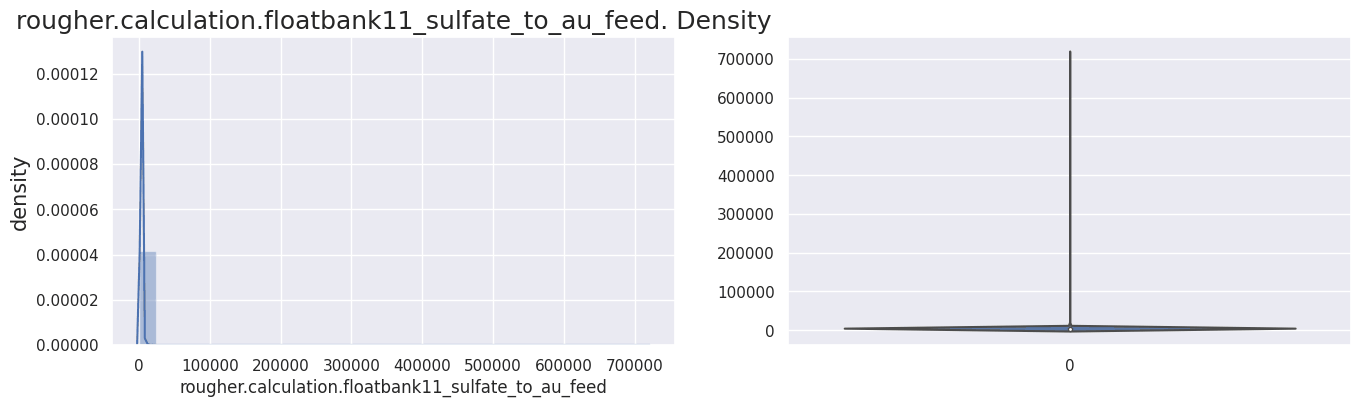

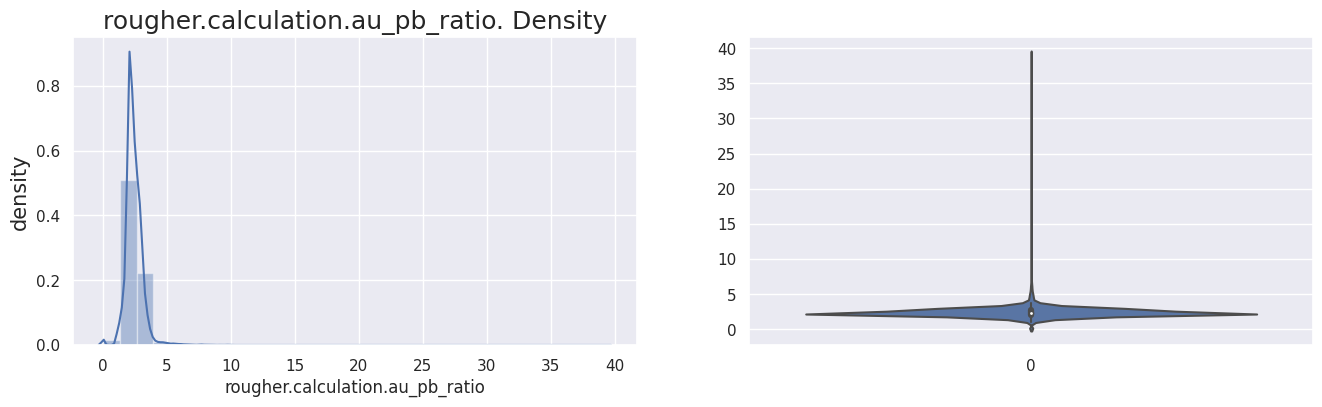

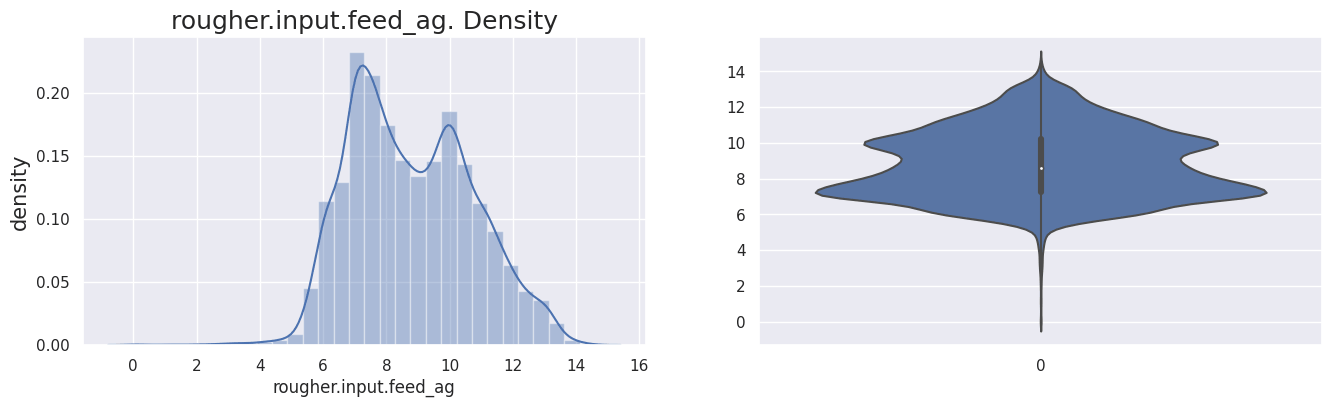

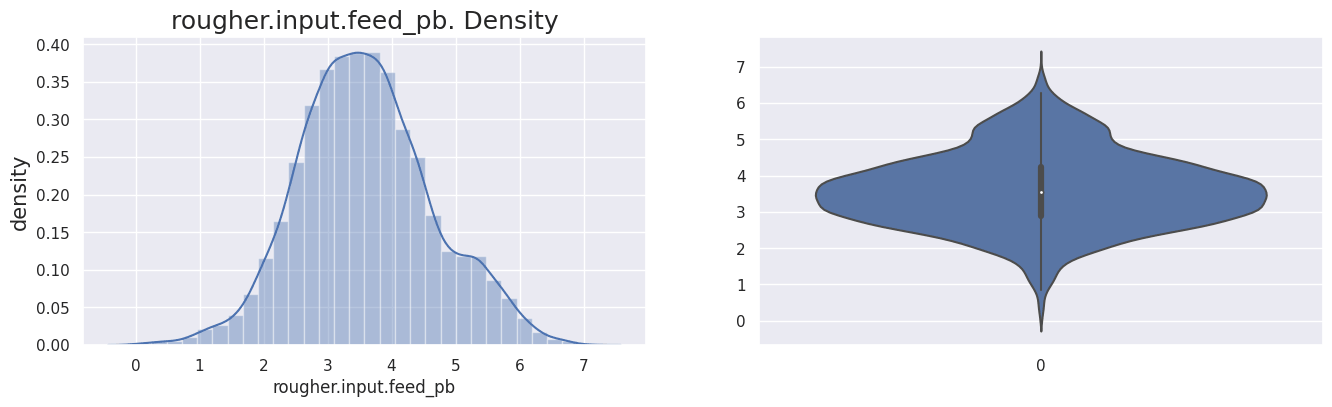

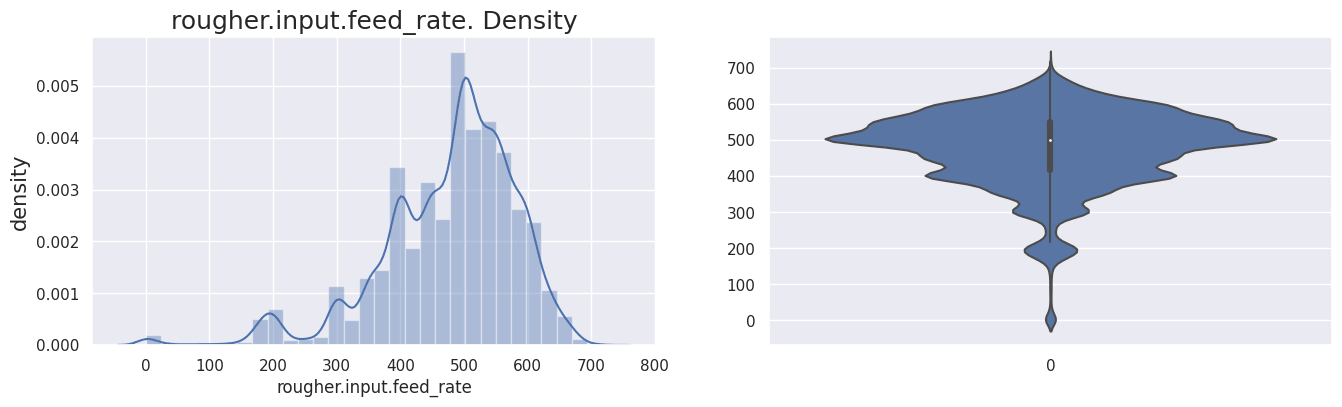

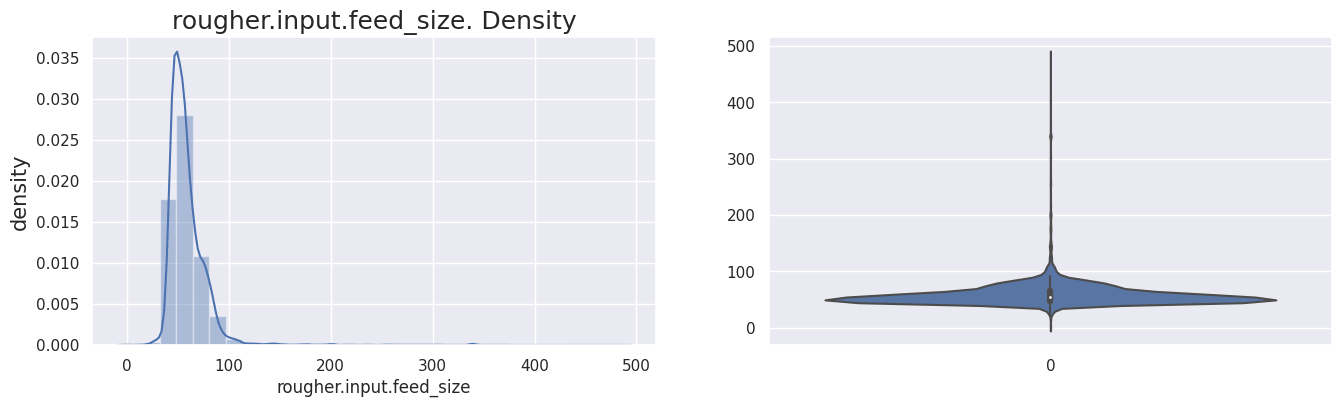

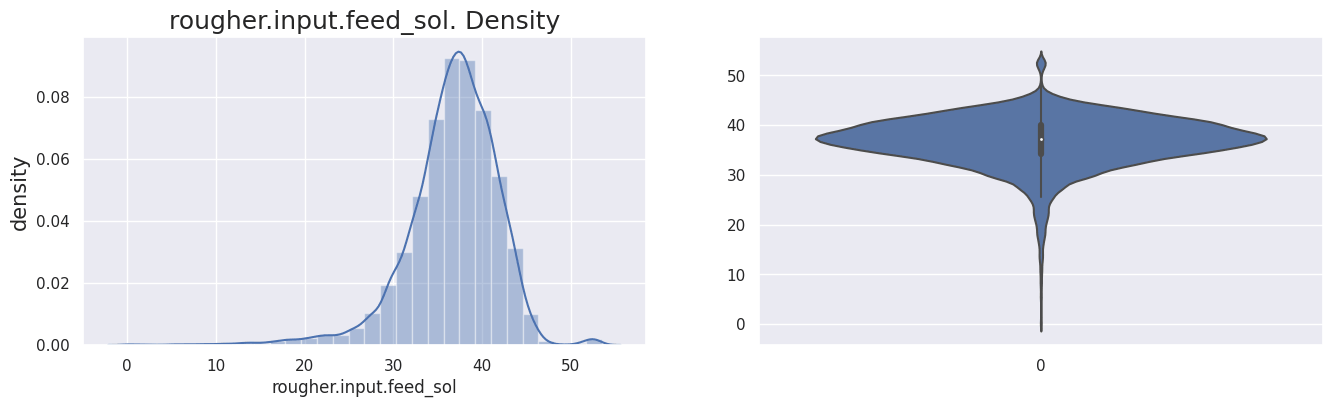

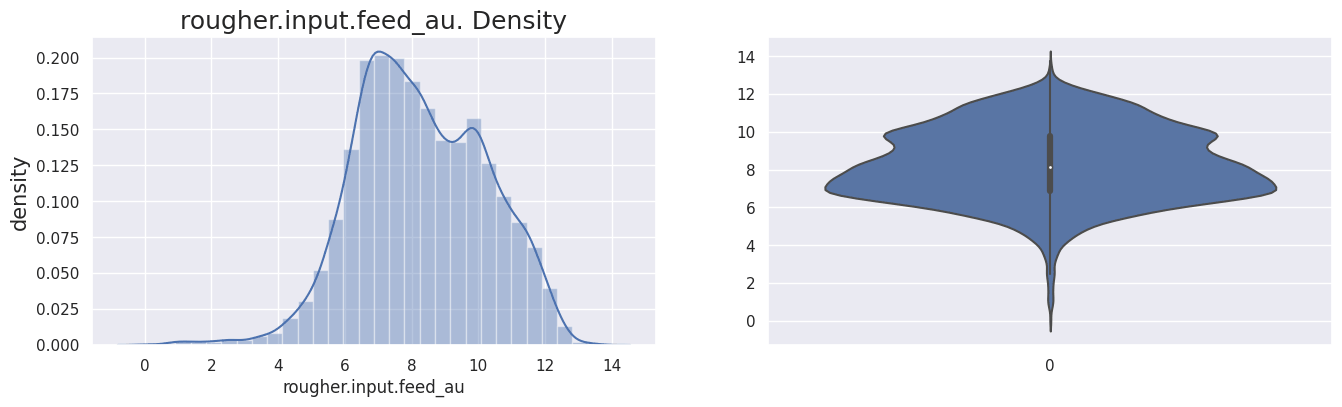

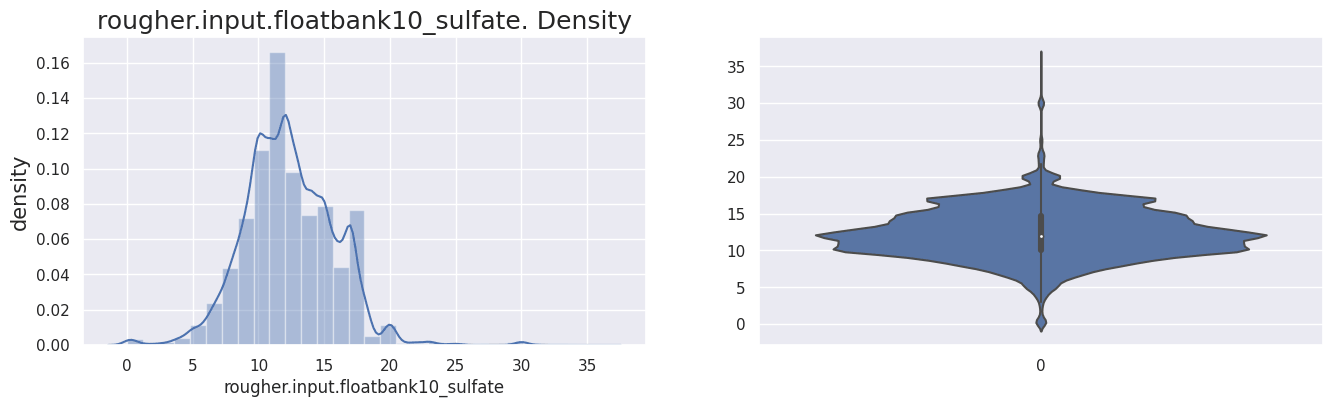

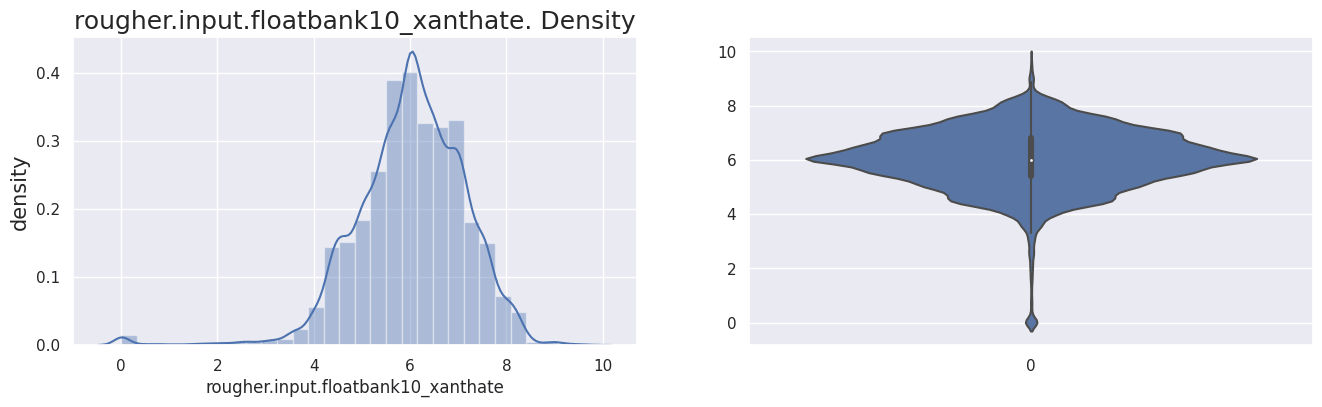

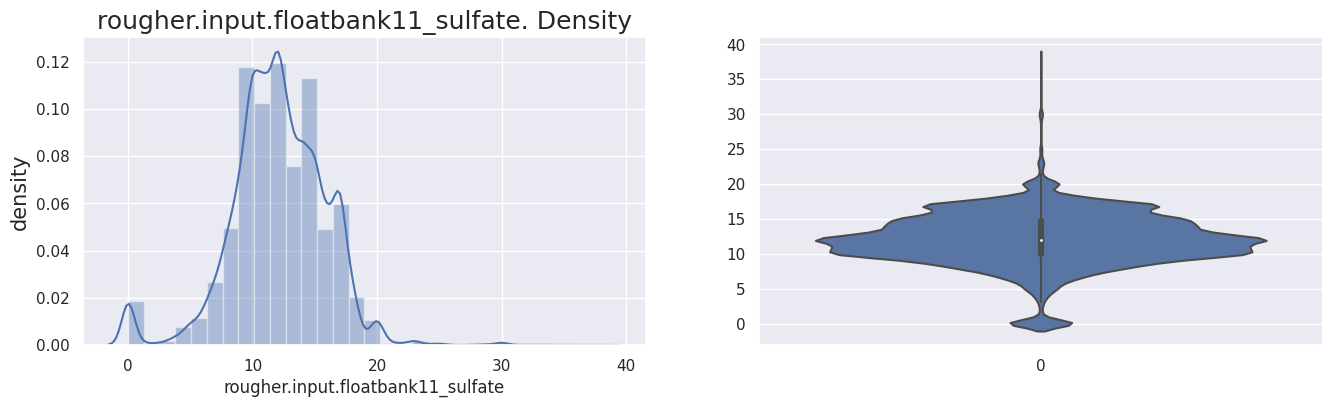

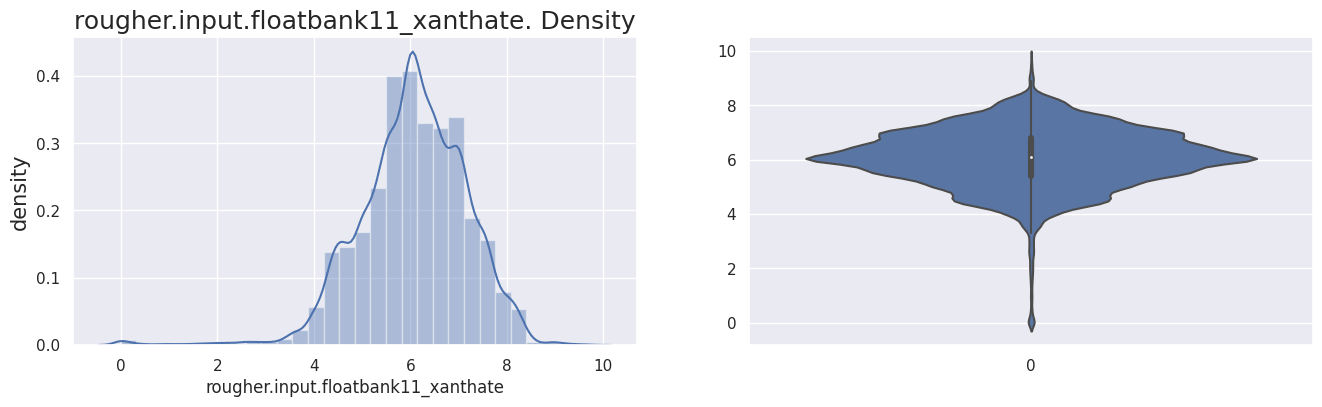

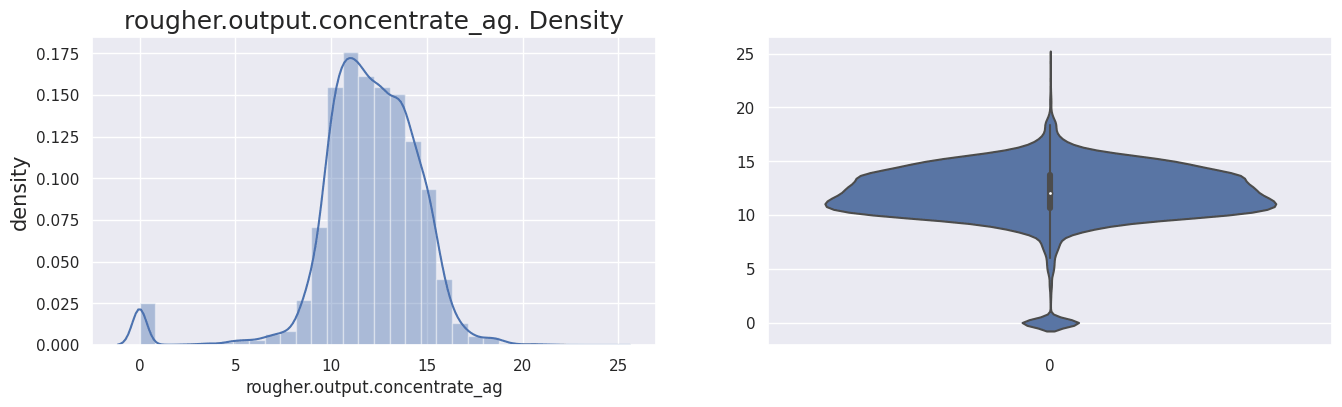

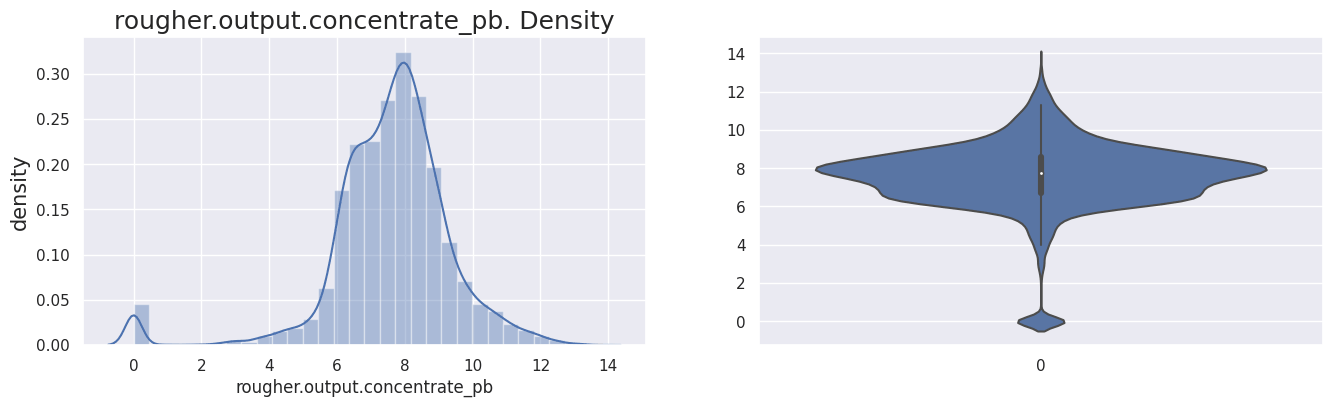

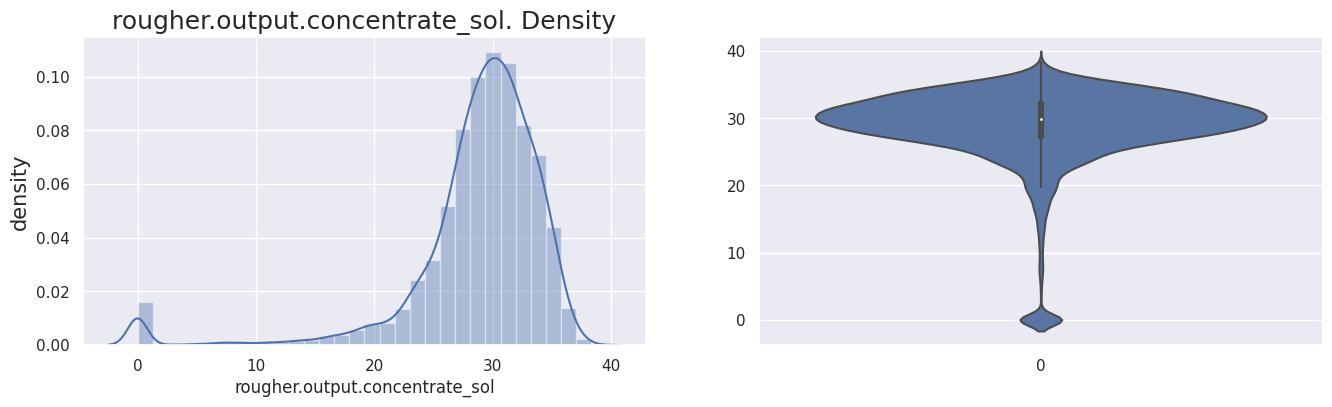

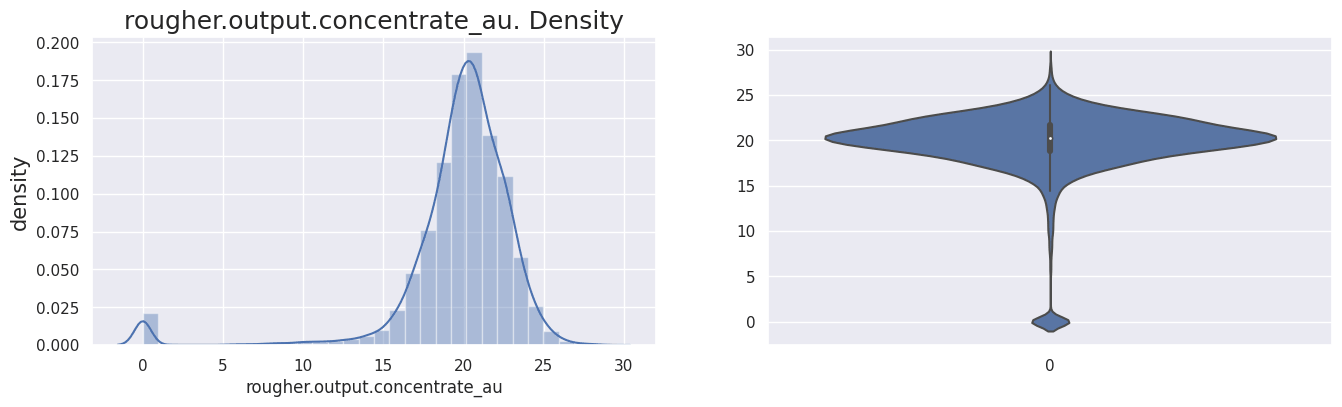

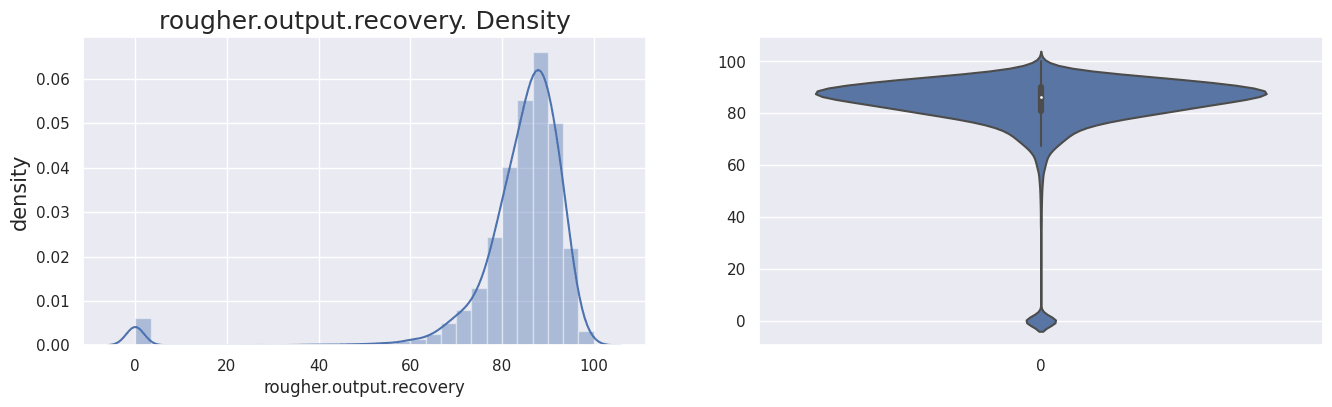

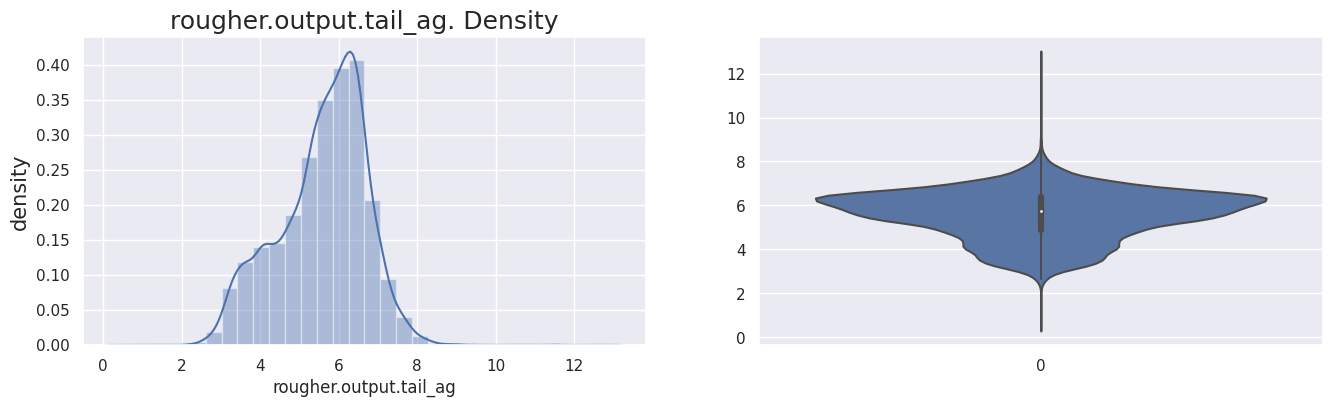

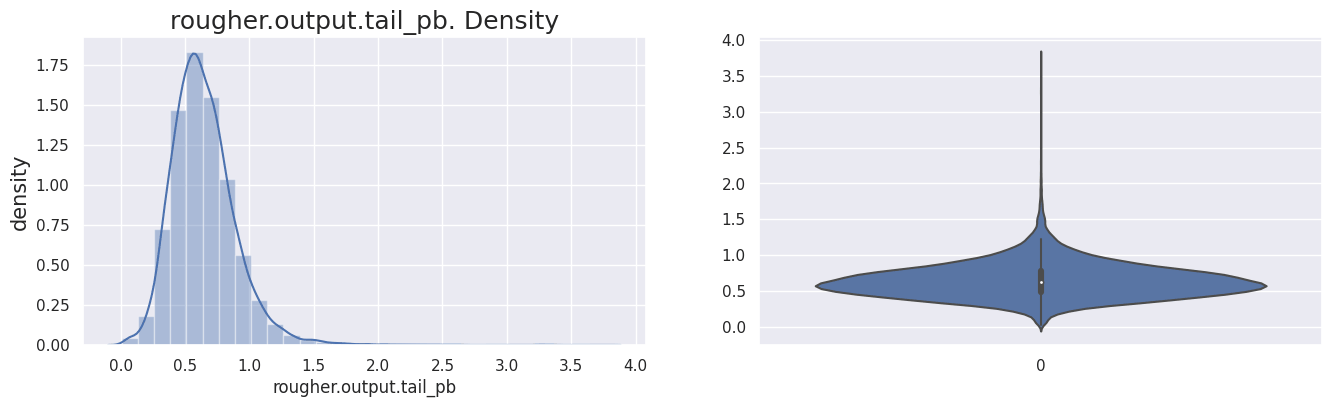

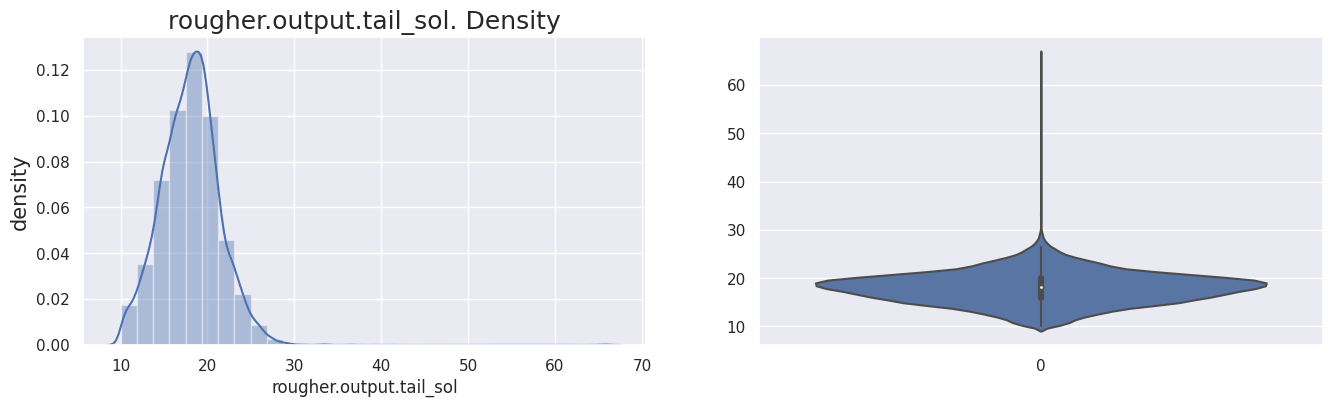

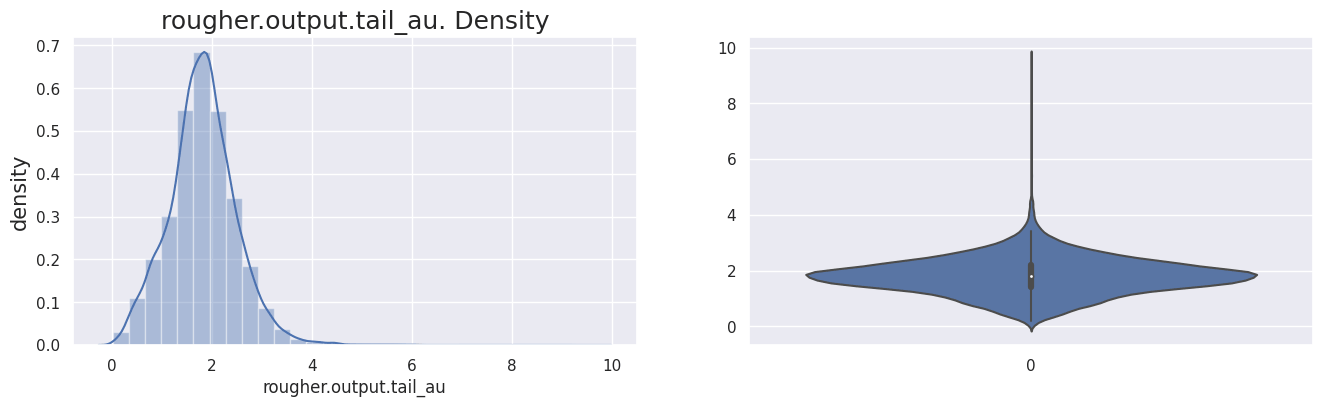

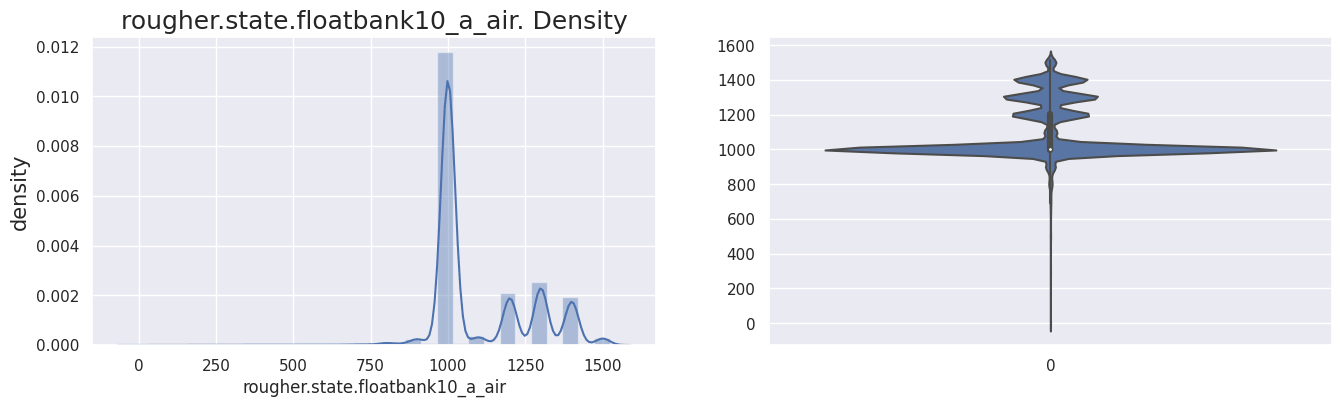

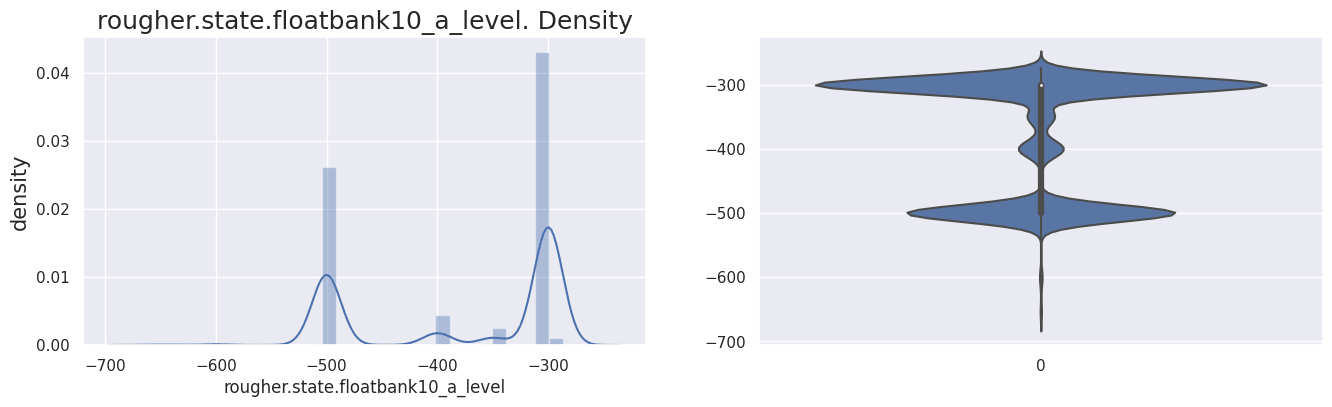

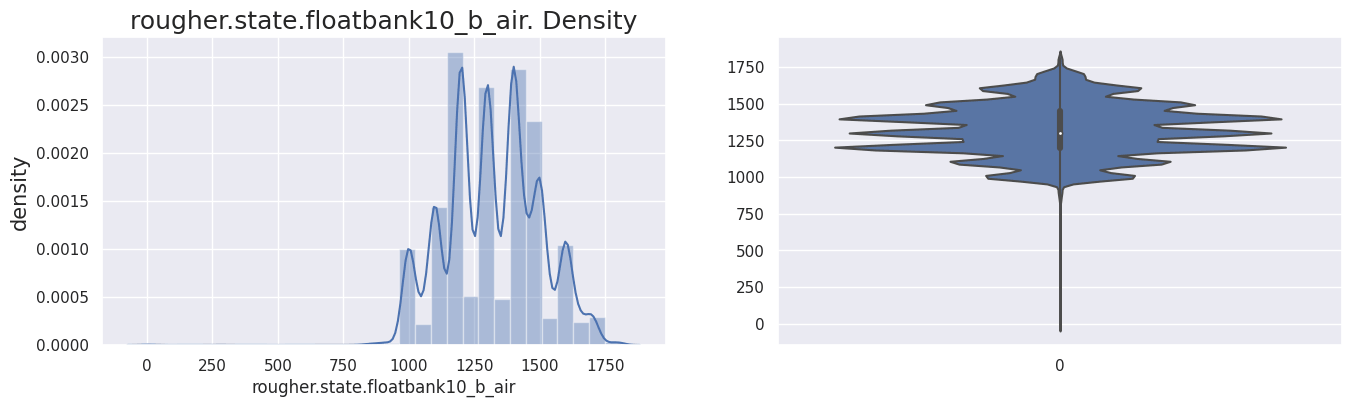

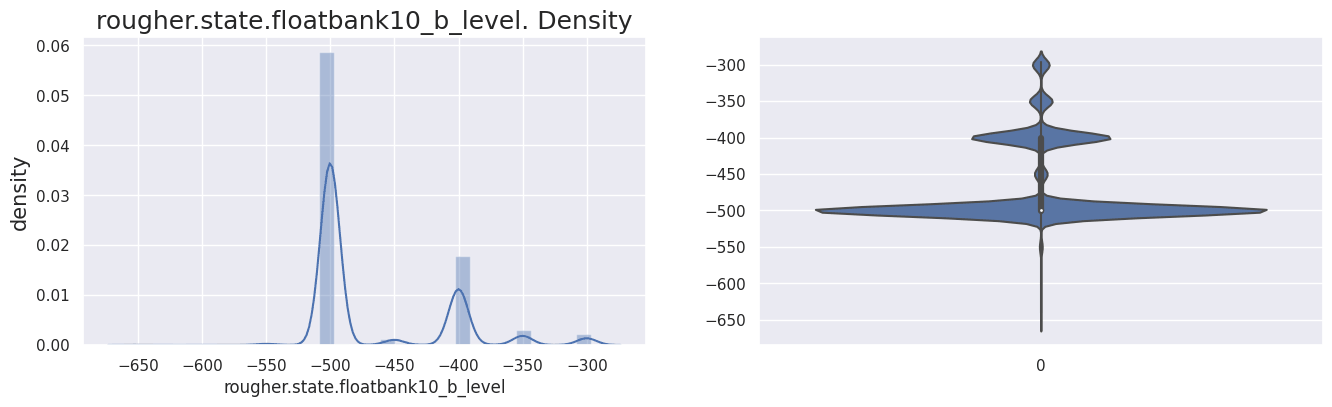

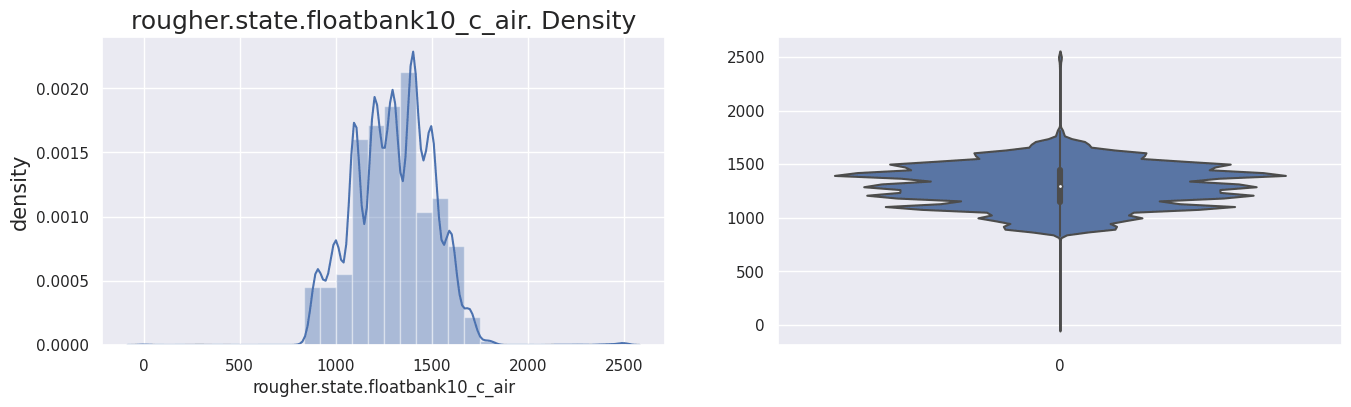

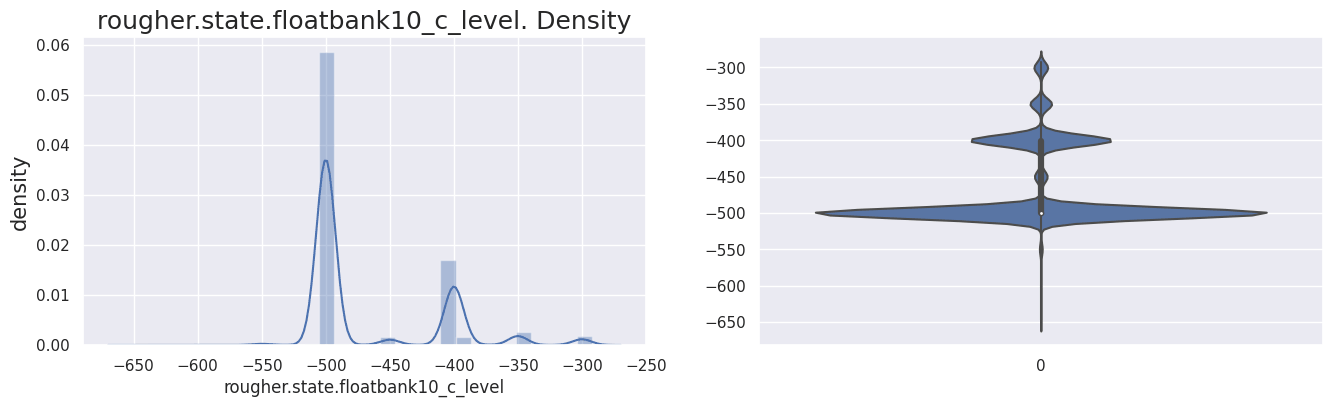

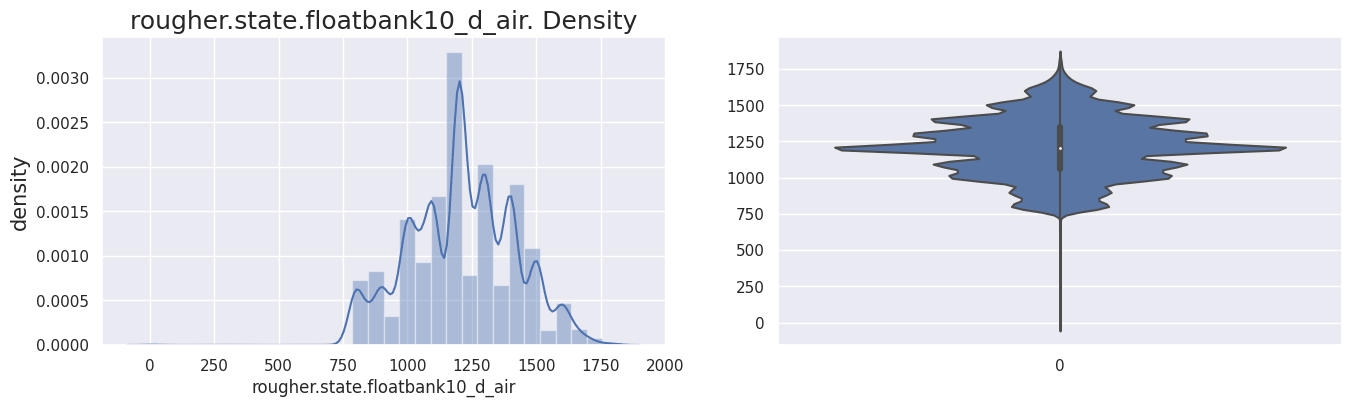

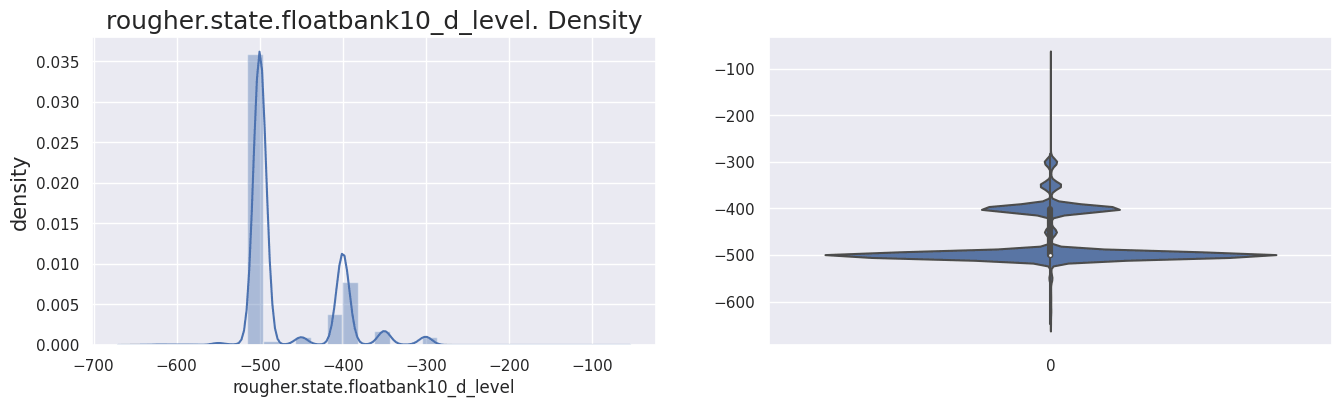

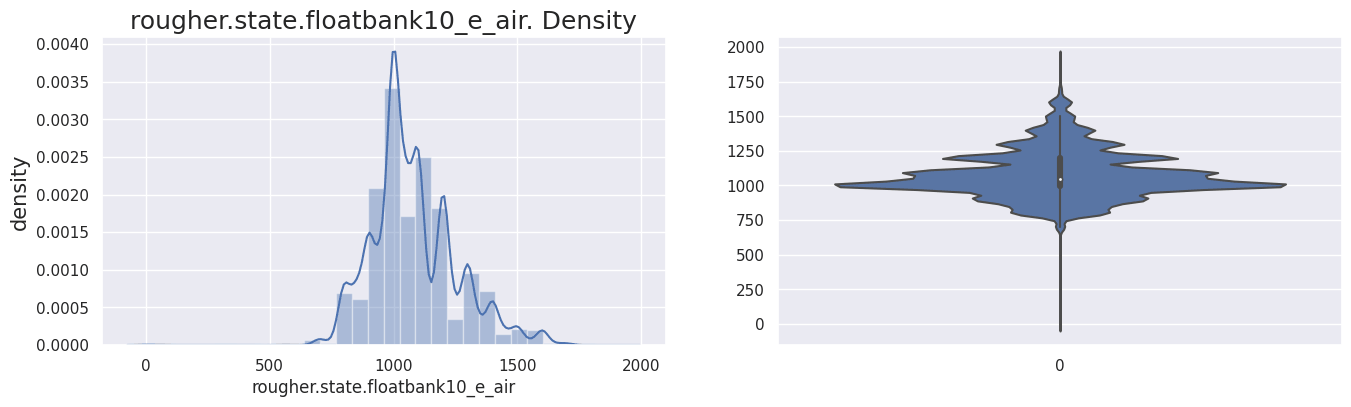

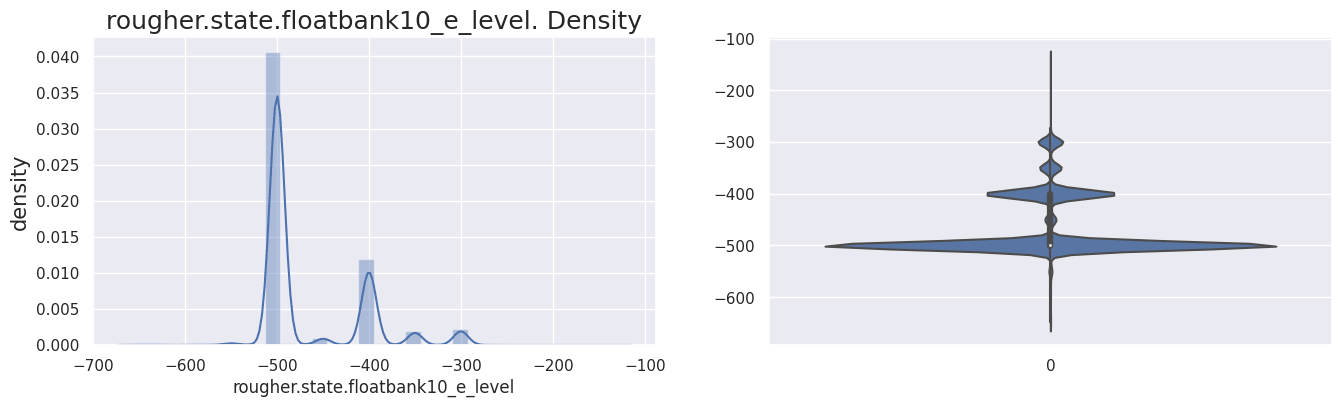

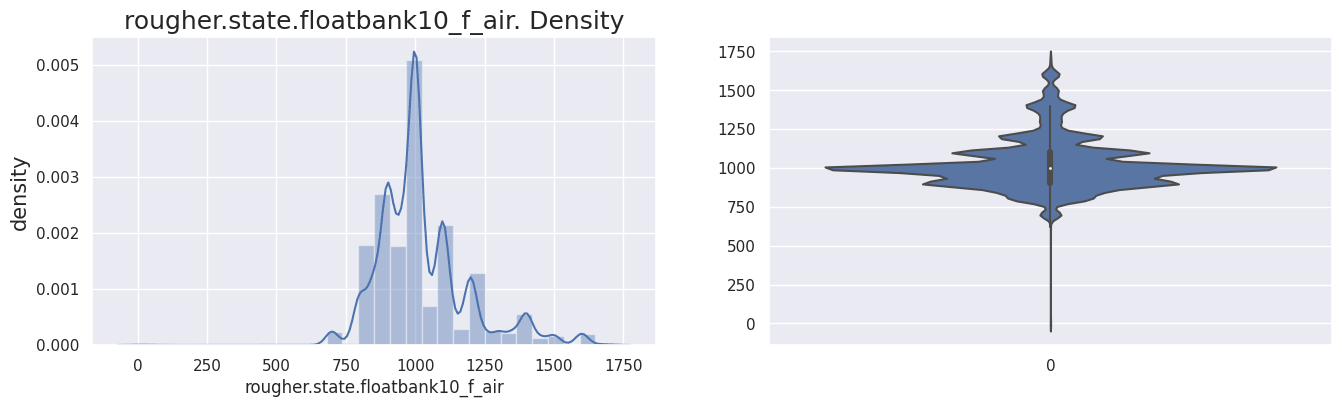

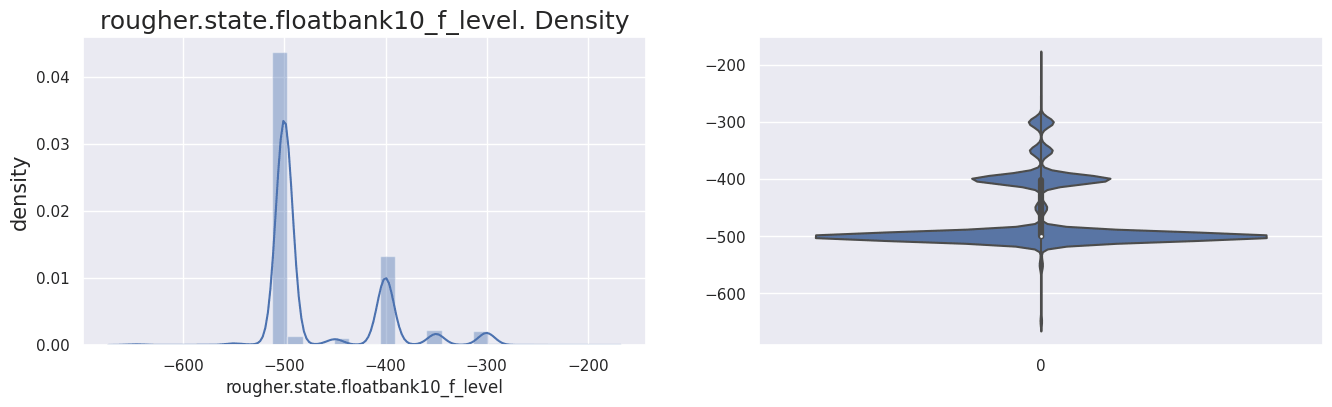

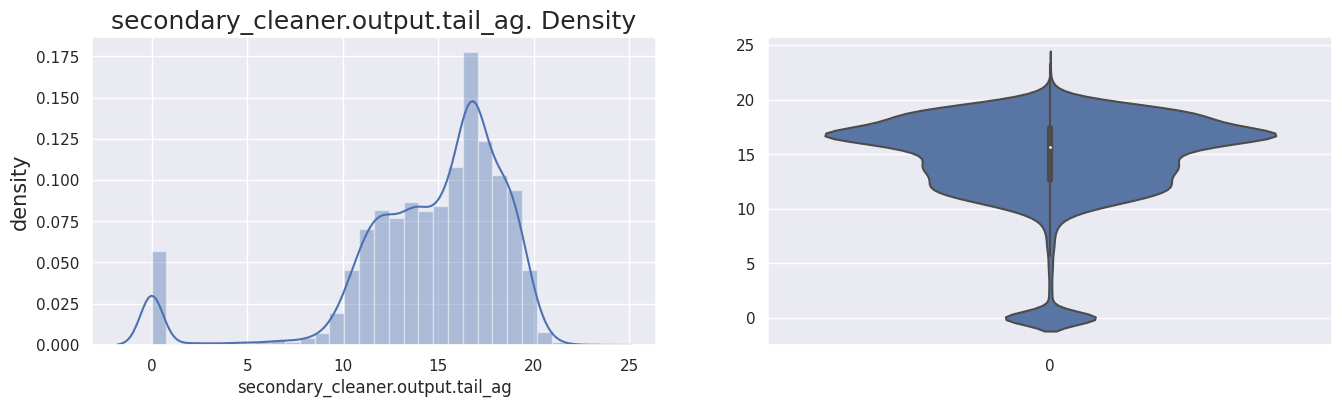

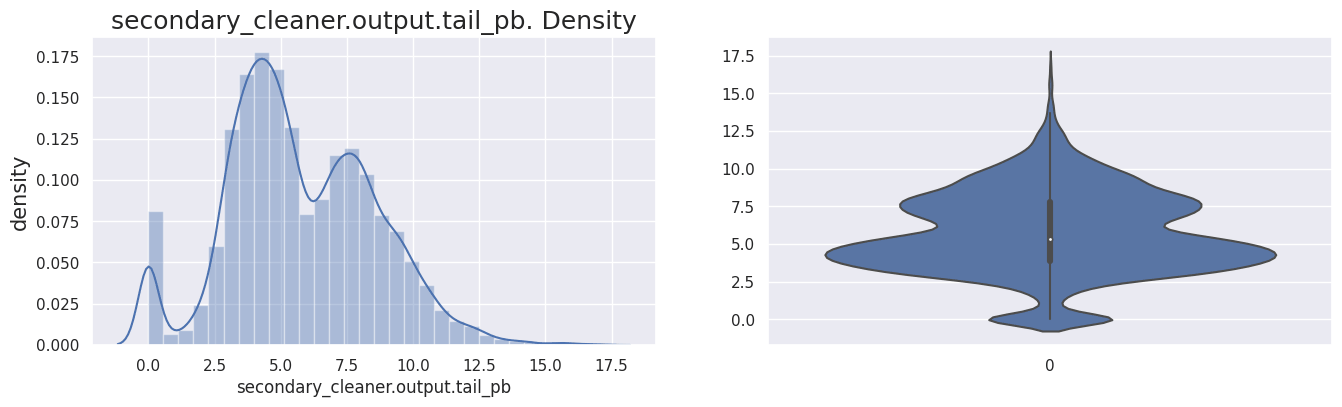

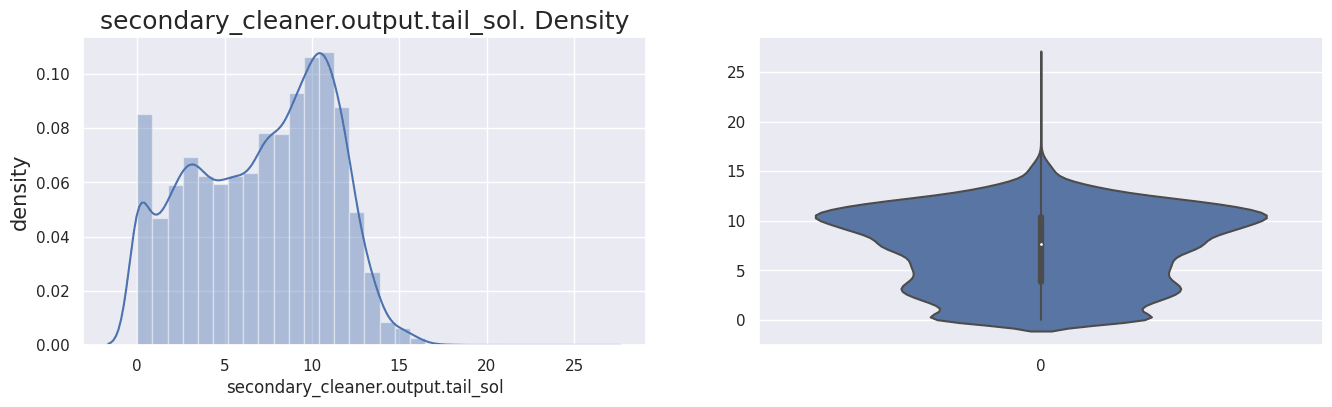

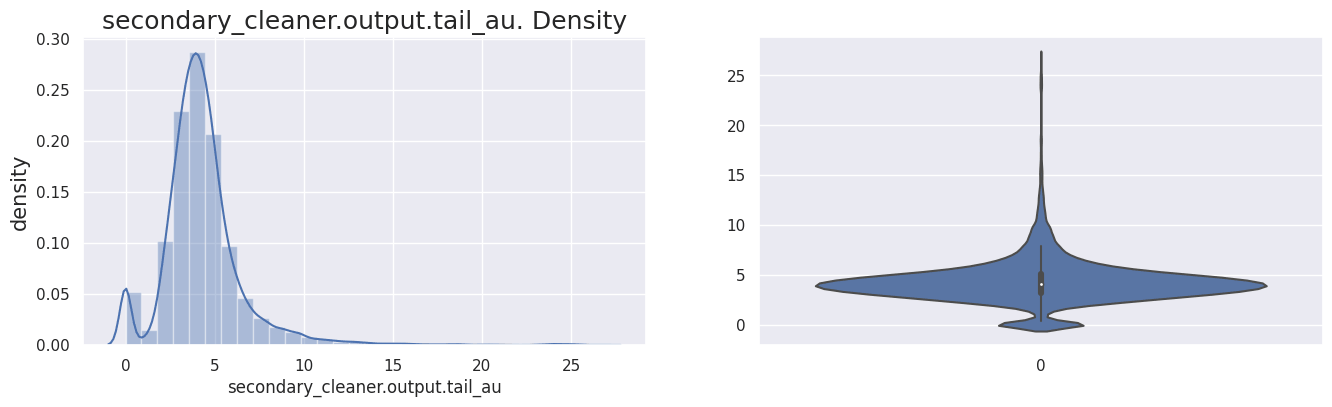

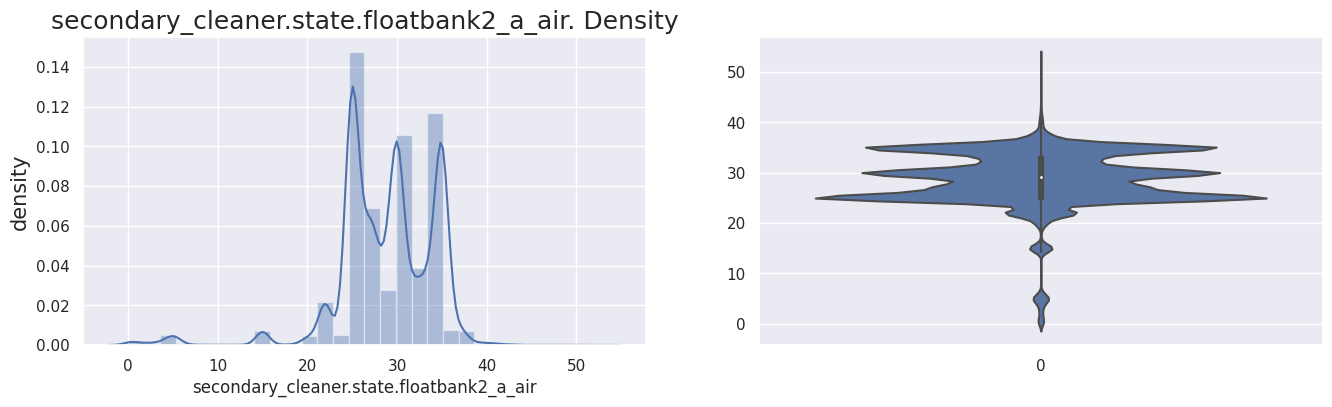

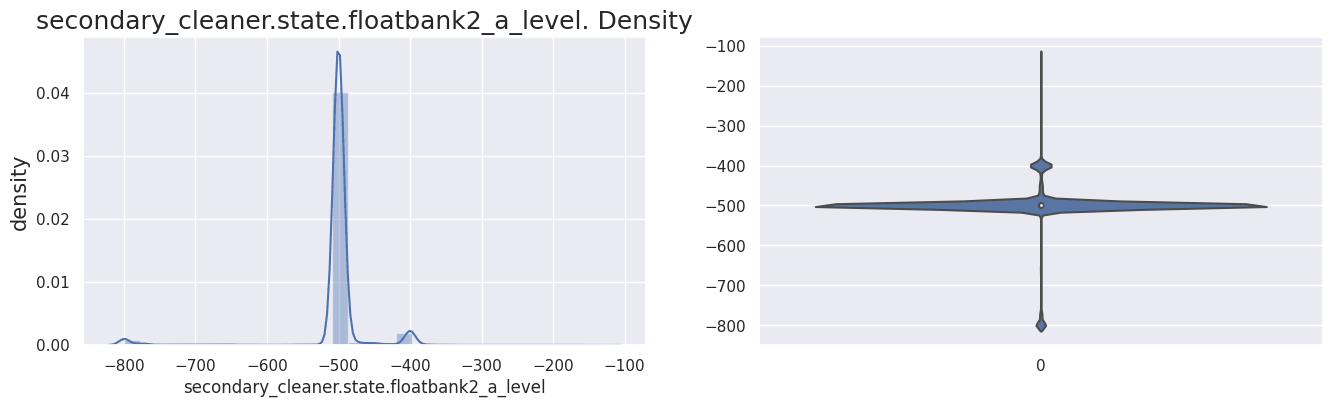

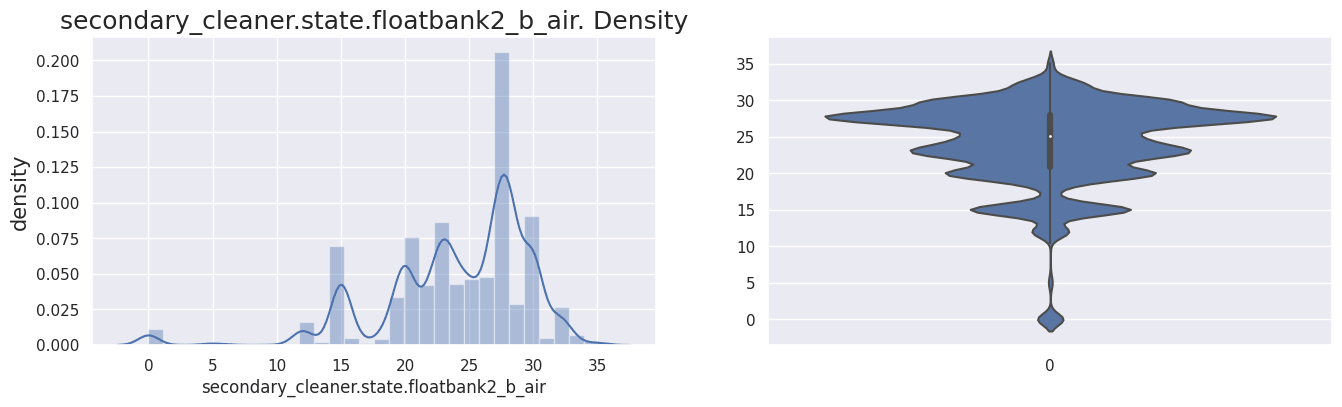

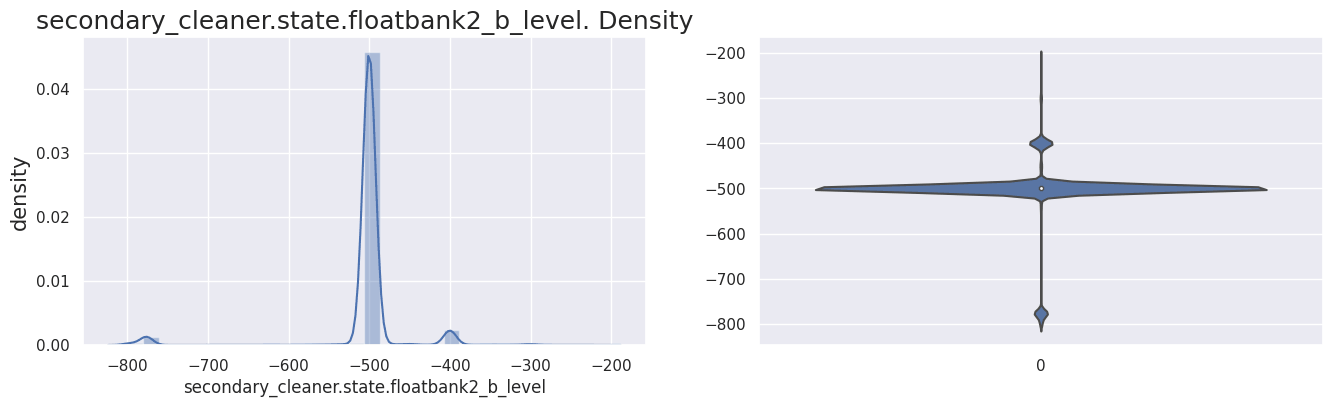

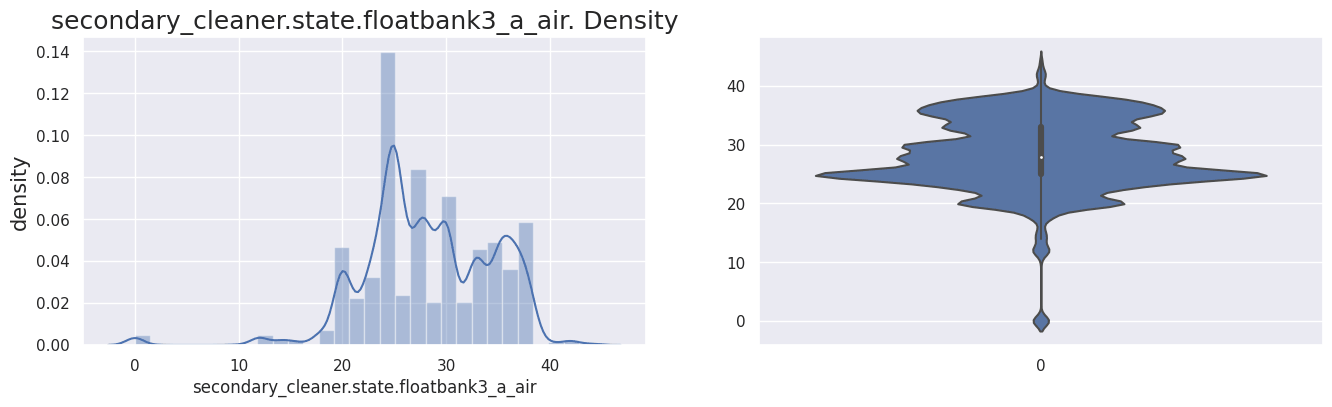

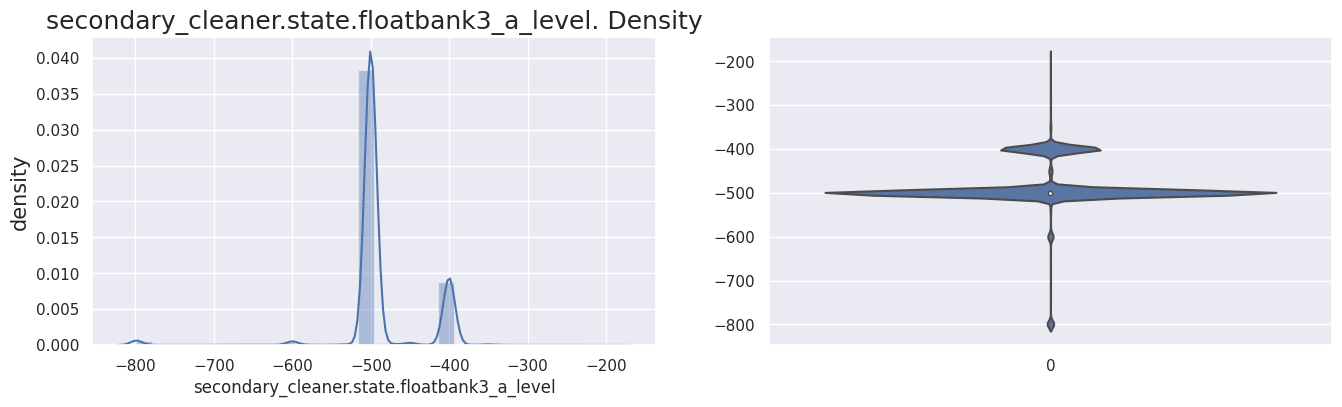

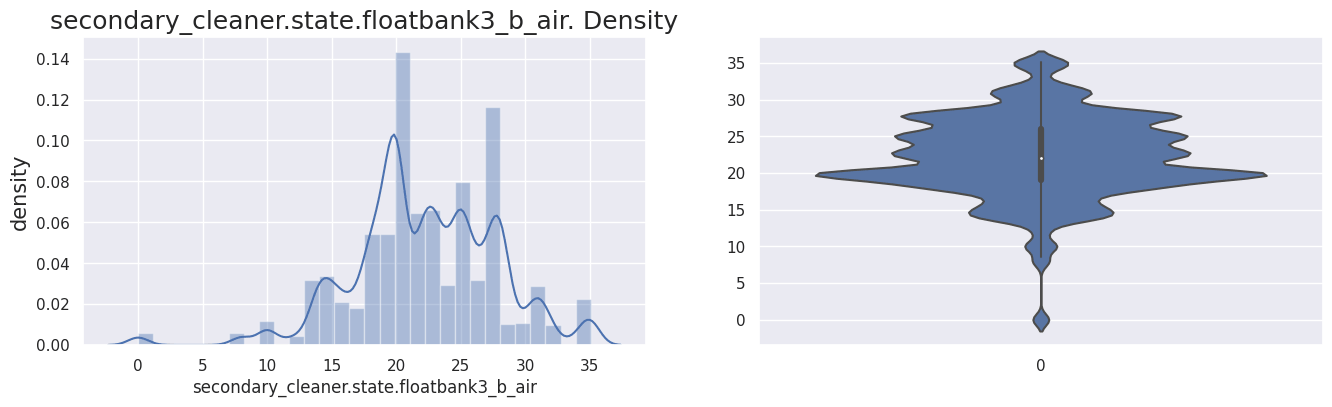

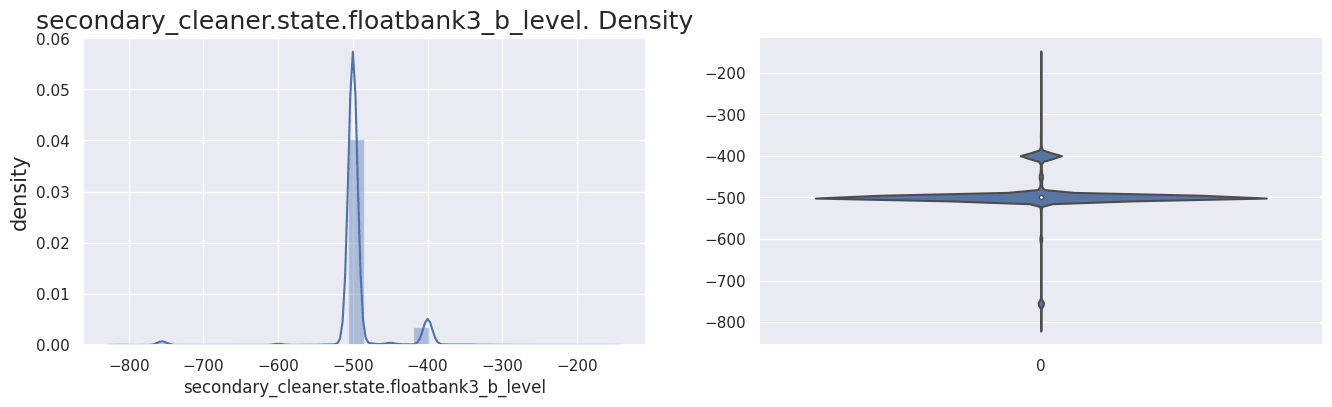

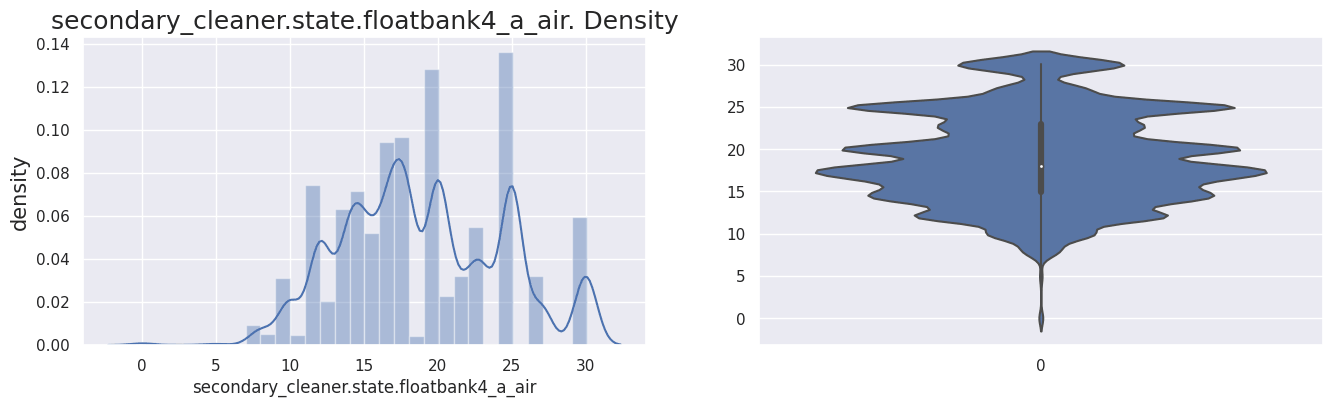

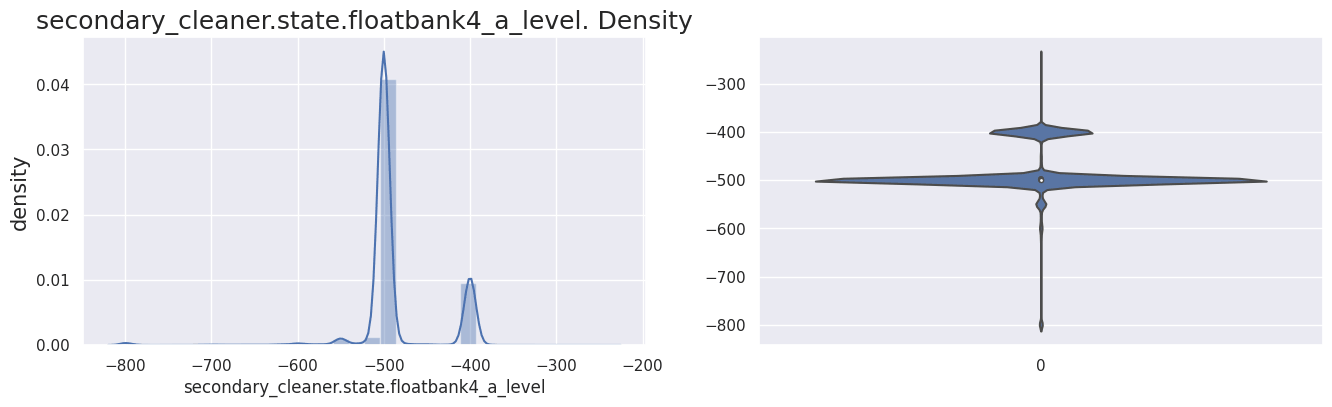

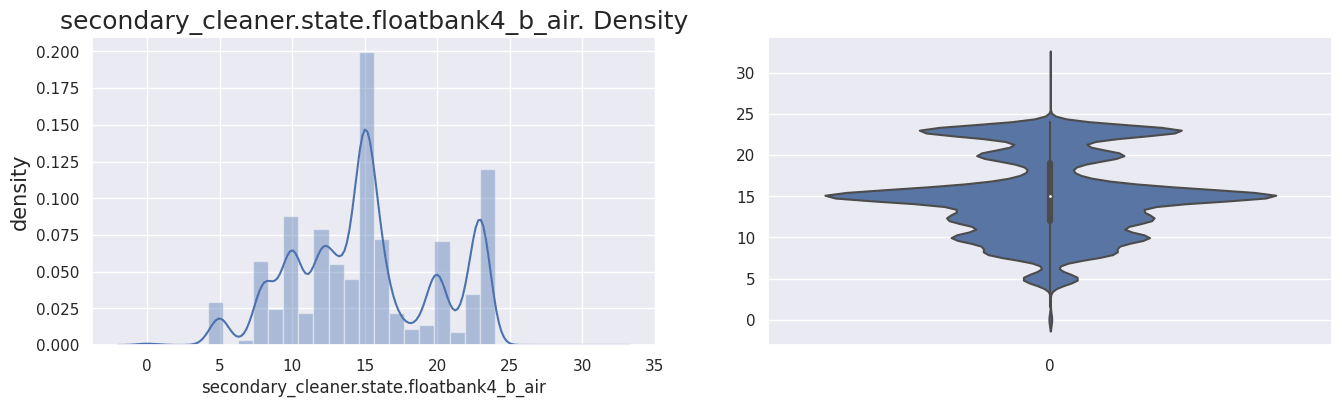

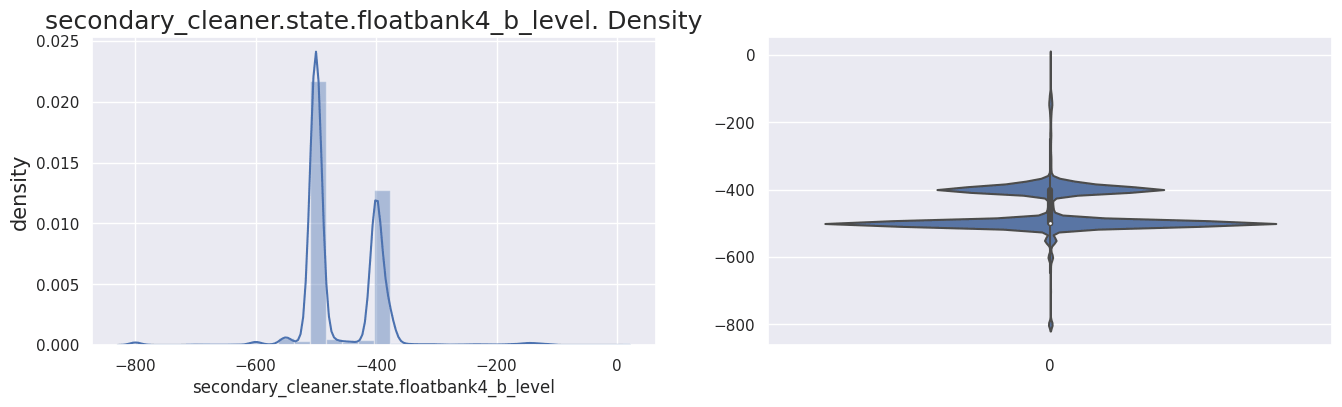

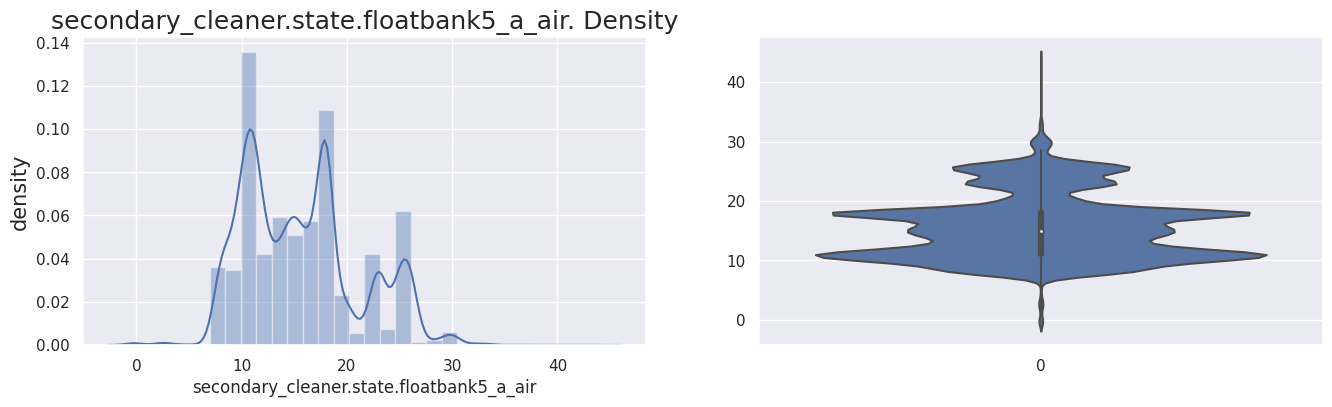

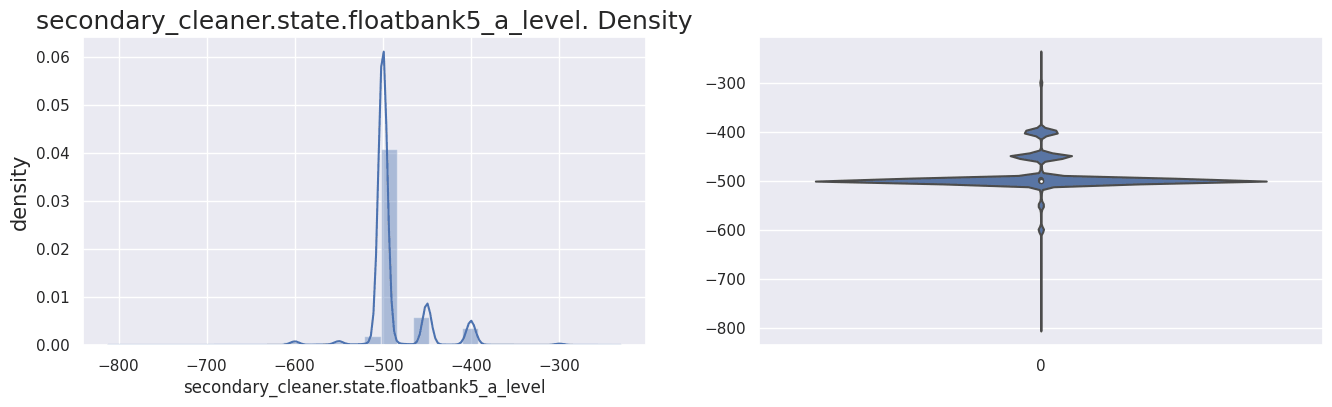

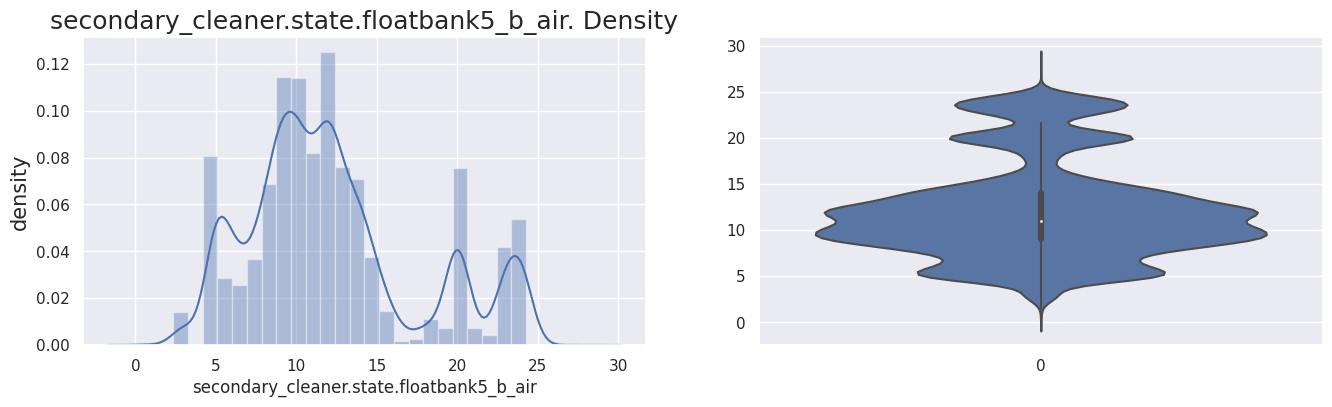

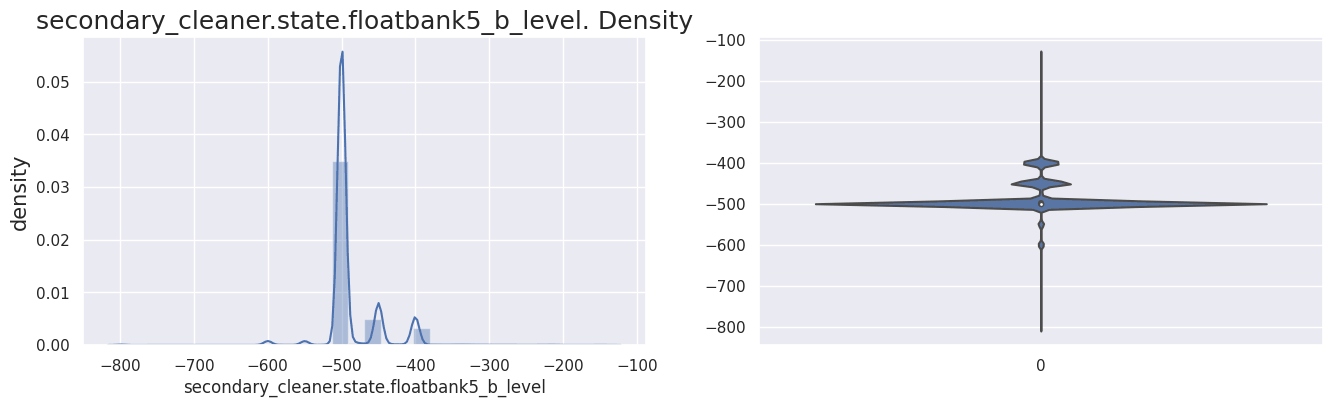

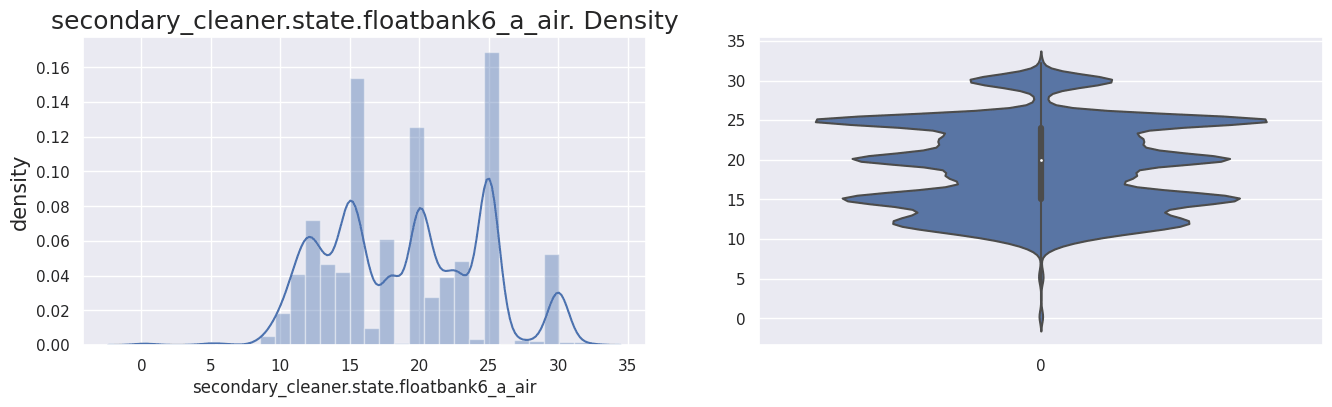

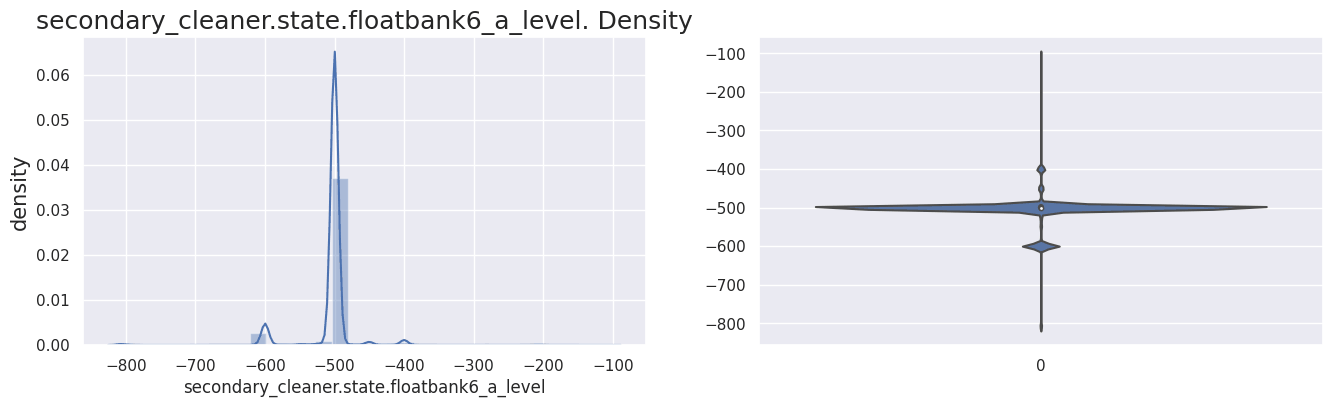

In [8]:
for column in full.columns:
    show_hists(full[column], column, num_bins=30)

- The distributions of some features differ from the normal one.
- There are also large outliers. After the feature selection their influence on the final model must be reduced (remove the outliers or take the logarithm of the feature).
- The scales of the distributions of individual features differ strongly (by more than an order of magnitude). The selected features need scaling.

## 1.2 Checking the Enrichment Efficiency Calculation

- Check that the enrichment efficiency is calculated correctly.
    - Calculate the recovery on the training set `train` for the feature `rougher.output.recovery` (flotation stage).
    - Find the sMAPE between the calculation and the value of the feature.

In [9]:
# calculate the gold recovery at the flotation stage
C = train.loc[~train['rougher.output.recovery'].isna(), 'rougher.output.concentrate_au']
F = train.loc[~train['rougher.output.recovery'].isna(), 'rougher.input.feed_au']
T = train.loc[~train['rougher.output.recovery'].isna(), 'rougher.output.tail_au']
rough_recov_calc = C * (F - T) / (F * (C - T)) * 100
rough_recov_train = train.loc[~train['rougher.output.recovery'].isna(), 'rougher.output.recovery']

In [10]:
# calculate sMAPE
numer = abs(rough_recov_train - rough_recov_calc)
denom = 0.5 * (abs(rough_recov_train) + abs(rough_recov_calc))
N = len(rough_recov_train)
smae_rough_rec = 1 / N * (numer / denom).sum() * 100
print("sMAPE for the 'gold recovery at the flotation stage'")
print("between the calculated value and the training set: {0:.2E}".format(smae_rough_rec))

sMAPE for the 'gold recovery at the flotation stage'
between the calculated value and the training set: 1.16E-14


- The sMAPE is negligibly small, so the metric is calculated correctly. Assume that the other `recovery` values are calculated correctly too.
- Try to fill the missing values of `rougher.output.recovery` in the training set using the available data.

## 1.3 Analysis of the Features That Are Not Available in the Test Set

In [11]:
[col for col in list(train.columns) if (col not in list(test.columns))]

['final.output.concentrate_ag',
 'final.output.concentrate_pb',
 'final.output.concentrate_sol',
 'final.output.concentrate_au',
 'final.output.recovery',
 'final.output.tail_ag',
 'final.output.tail_pb',
 'final.output.tail_sol',
 'final.output.tail_au',
 'primary_cleaner.output.concentrate_ag',
 'primary_cleaner.output.concentrate_pb',
 'primary_cleaner.output.concentrate_sol',
 'primary_cleaner.output.concentrate_au',
 'primary_cleaner.output.tail_ag',
 'primary_cleaner.output.tail_pb',
 'primary_cleaner.output.tail_sol',
 'primary_cleaner.output.tail_au',
 'rougher.calculation.sulfate_to_au_concentrate',
 'rougher.calculation.floatbank10_sulfate_to_au_feed',
 'rougher.calculation.floatbank11_sulfate_to_au_feed',
 'rougher.calculation.au_pb_ratio',
 'rougher.output.concentrate_ag',
 'rougher.output.concentrate_pb',
 'rougher.output.concentrate_sol',
 'rougher.output.concentrate_au',
 'rougher.output.recovery',
 'rougher.output.tail_ag',
 'rougher.output.tail_pb',
 'rougher.output.ta

- The test set does not contain the product parameters `output` of each stage of the process. These are the concentrates and the "tailings" of the metals (Au, Ag, Pb) and salts, and the calculated `recovery` of the different stages. This data is not suitable for training the model anyway, because it appears during or after the measurement of the target features.
- The test set also does not contain the calculated features of the flotation stage `rougher.calculation` (concentration of sulfates relative to gold, ratio of gold to lead, etc.).
- These features are not used to build the model.

## 1.4 Data Preprocessing

- Not all features are suitable for training the model.
    - Select the features that correlate most with the target features `final.output.recovery` and `rougher.output.recovery`.
    - Also remove the features that correlate strongly with the already selected ones. Adding such features does not improve the model quality, but increases its complexity and possibly the variance of the predictions.
- Look at the missing values and anomalies among the selected features.

In [12]:
input_columns = list(test.columns)
model_columns = ['final.output.recovery', 'rougher.output.recovery'] + input_columns

In [13]:
(train[model_columns].corr()
 .sort_values(by = 'final.output.recovery', ascending = False)
 .style.background_gradient(cmap = 'coolwarm')
)

,final.output.recovery,rougher.output.recovery,primary_cleaner.input.sulfate,primary_cleaner.input.depressant,primary_cleaner.input.feed_size,primary_cleaner.input.xanthate,primary_cleaner.state.floatbank8_a_air,primary_cleaner.state.floatbank8_a_level,primary_cleaner.state.floatbank8_b_air,primary_cleaner.state.floatbank8_b_level,primary_cleaner.state.floatbank8_c_air,primary_cleaner.state.floatbank8_c_level,primary_cleaner.state.floatbank8_d_air,primary_cleaner.state.floatbank8_d_level,rougher.input.feed_ag,rougher.input.feed_pb,rougher.input.feed_rate,rougher.input.feed_size,rougher.input.feed_sol,rougher.input.feed_au,rougher.input.floatbank10_sulfate,rougher.input.floatbank10_xanthate,rougher.input.floatbank11_sulfate,rougher.input.floatbank11_xanthate,rougher.state.floatbank10_a_air,rougher.state.floatbank10_a_level,rougher.state.floatbank10_b_air,rougher.state.floatbank10_b_level,rougher.state.floatbank10_c_air,rougher.state.floatbank10_c_level,rougher.state.floatbank10_d_air,rougher.state.floatbank10_d_level,rougher.state.floatbank10_e_air,rougher.state.floatbank10_e_level,rougher.state.floatbank10_f_air,rougher.state.floatbank10_f_level,secondary_cleaner.state.floatbank2_a_air,secondary_cleaner.state.floatbank2_a_level,secondary_cleaner.state.floatbank2_b_air,secondary_cleaner.state.floatbank2_b_level,secondary_cleaner.state.floatbank3_a_air,secondary_cleaner.state.floatbank3_a_level,secondary_cleaner.state.floatbank3_b_air,secondary_cleaner.state.floatbank3_b_level,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_air,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank5_b_air,secondary_cleaner.state.floatbank5_b_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
final.output.recovery,1.000000,0.328301,0.398307,0.162380,0.067164,0.215482,0.133505,0.028648,0.148896,0.042773,0.143728,0.028910,0.058597,-0.017210,0.310520,0.191238,0.168630,0.057269,0.260769,0.308522,-0.013893,0.333467,0.020547,0.328302,0.228803,0.094012,-0.148507,-0.084289,-0.183622,-0.093690,-0.179417,-0.094206,-0.110595,-0.094634,-0.092119,-0.092465,0.150131,0.003781,0.134570,0.000450,0.187685,0.031729,0.038287,0.011045,0.207745,0.057454,0.170838,-0.088934,0.098267,0.024196,0.068331,0.043838,-0.027593,-0.035658
primary_cleaner.input.sulfate,0.398307,0.274956,1.000000,0.482240,0.166392,0.253273,0.023648,-0.031444,0.044791,-0.028136,0.044617,-0.021206,0.105070,-0.020891,0.544422,0.547225,0.311264,-0.071669,0.368276,0.609566,0.367269,0.389347,0.489468,0.361379,0.204051,0.075651,-0.229286,-0.222607,-0.255377,-0.224740,-0.293069,-0.223854,-0.258727,-0.228854,-0.241080,-0.229767,0.139314,0.103744,0.132529,0.123208,0.080139,-0.012916,0.001261,-0.040624,0.084026,0.031190,0.109306,-0.062263,-0.007605,-0.031146,-0.000789,-0.022692,-0.106076,-0.141741
rougher.input.floatbank10_xanthate,0.333467,0.238837,0.389347,0.369921,0.020886,0.383201,-0.014774,0.228944,0.016663,0.226219,0.019414,0.238345,-0.143760,0.159972,0.146664,0.006697,0.597251,0.096028,0.324372,0.083848,-0.095321,1.000000,0.006102,0.940049,0.118409,-0.067622,-0.101830,-0.356618,-0.166701,-0.363100,-0.120897,-0.359165,0.040504,-0.358338,0.010555,-0.357920,0.132616,0.118347,0.148000,0.108722,-0.032639,-0.137672,-0.082305,0.051964,0.079465,-0.216015,0.000141,-0.364619,-0.130231,-0.150960,-0.149503,-0.160042,-0.296149,0.010782
rougher.input.floatbank11_xanthate,0.328302,0.234952,0.361379,0.368112,0.003577,0.379290,-0.035232,0.209651,0.005835,0.211494,-0.000634,0.212173,-0.112243,0.132520,0.142798,-0.001170,0.591576,0.101165,0.305947,0.090465,-0.126746,0.940049,-0.051596,1.000000,0.110069,-0.082826,-0.102477,-0.377847,-0.163005,-0.385352,-0.113021,-0.377125,0.044313,-0.382014,0.009632,-0.383439,0.099535,0.078177,0.138714,0.056395,-0.026542,-0.130398,-0.053099,0.044551,0.056766,-0.211714,-0.000

In [14]:
columns_to_drop = ['primary_cleaner.state.floatbank8_c_air', 'primary_cleaner.state.floatbank8_b_air', 
                   'primary_cleaner.state.floatbank8_a_level', 'primary_cleaner.state.floatbank8_c_level',
                   'primary_cleaner.state.floatbank8_d_level', 'rougher.input.floatbank10_sulfate',
                   'rougher.input.floatbank10_xanthate', 'rougher.state.floatbank10_b_air',
                   'rougher.state.floatbank10_c_level', 'rougher.state.floatbank10_d_air', 
                   'rougher.state.floatbank10_d_level', 'rougher.state.floatbank10_e_air',
                   'rougher.state.floatbank10_f_level', 'secondary_cleaner.state.floatbank2_a_air',
                   'secondary_cleaner.state.floatbank2_a_level', 'secondary_cleaner.state.floatbank4_b_air',
                   'secondary_cleaner.state.floatbank5_b_air', 'secondary_cleaner.state.floatbank5_b_level',
                   'rougher.state.floatbank10_b_level']

In [15]:
model_columns = [column for column in model_columns if column not in columns_to_drop]
input_columns = [column for column in input_columns if column not in columns_to_drop]

- The features selected for removal describe the current state of the stages of the technological process. They are most likely directly related to the remaining features (liquid levels and air volumes in different `floatbank` units depend directly on each other). The process may be configured this way, and the redundant features can be removed. This may not always hold, though. If the dependencies between the features change in the future (liquid levels and gas volumes in different `floatbank` units become independent), the regression model may become outdated. These parameters must be monitored and the model updated if necessary.
- Remove the selected features.

In [16]:
train = train.drop(columns_to_drop, axis = 1)
test = test.drop(columns_to_drop, axis = 1)

In [17]:
set(train) == set (test)

False

- The only feature with many missing values is `rougher.input.floatbank11_xanthate`. It correlates strongly with the feature `rougher.input.floatbank10_xanthate`. Both features describe the amount of activator at the flotation input. Look at their joint distribution on a scatter plot.

<Axes: xlabel='rougher.input.floatbank10_xanthate', ylabel='rougher.input.floatbank11_xanthate'>

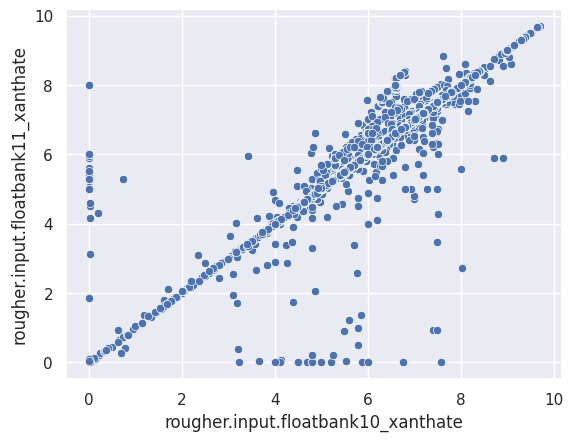

In [18]:
sns.scatterplot(x = 'rougher.input.floatbank10_xanthate', y = 'rougher.input.floatbank11_xanthate', data = full)

Both features are distributed almost identically and in most cases repeat each other. Fill the missing values of `floatbank11` with the known values of `floatbank10`.

In [19]:
train['rougher.input.floatbank11_xanthate'] = (train['rougher.input.floatbank11_xanthate']
                                               .fillna(full['rougher.input.floatbank10_xanthate']))
test['rougher.input.floatbank11_xanthate'] = (test['rougher.input.floatbank11_xanthate']
                                               .fillna(full['rougher.input.floatbank10_xanthate']))

- Try to fill the missing values of the target features using the available data.

In [20]:
# calculate the gold recovery at the flotation stage
C = train.loc[train['rougher.output.recovery'].isna(), 'rougher.output.concentrate_au']
F = train.loc[train['rougher.output.recovery'].isna(), 'rougher.input.feed_au']
T = train.loc[train['rougher.output.recovery'].isna(), 'rougher.output.tail_au']
train.loc[train['rougher.output.recovery'].isna(), 'rougher.output.recovery'] = C * (F - T) / (F * (C - T)) * 100

In [21]:
print('Number of missing recovery values at the flotation stage:', sum(train['rougher.output.recovery'].isna()))

Number of missing recovery values at the flotation stage: 0


- Almost all of the remaining features have missing values, but there are few of them (about 1-2%). Fill them with the values of the neighboring objects (the data is ordered by time, and the values of neighboring objects differ little from each other).

In [22]:
train[input_columns] = train[input_columns].fillna(method='ffill')
test = test.fillna(method='ffill')

- The outliers are studied together with the total concentration of all substances in section 2.

### Conclusions

- The data is loaded and analyzed successfully. It matches the description and has no duplicates.
- The enrichment efficiency is calculated correctly.
- The test set does not contain the product parameters and the calculated features of the flotation stage. These parameters are not used to build the model.
- Features that are redundant for the model (some parameters that characterize the current state of the stages of the process) are selected and excluded from the model. If the process changes, the behavior of these features may change and the model will have to be updated.
- The missing values of the relevant features are filled using the available historical data.

# 2. Data Analysis

## 2.1 Change of the Metal Concentrations (Au, Ag, Pb)

- To analyze the metal concentrations, look at the plots of the concentration over time (for each stage) and at the plots of the average values by cleaning stage.

In [23]:
train = train.set_index(pd.DatetimeIndex(train.index))
test = test.set_index(pd.DatetimeIndex(test.index))
full = full.set_index(pd.DatetimeIndex(full.index))

In [24]:
met_concs = np.array([['rougher.output.concentrate_au', 'primary_cleaner.output.concentrate_au', 'final.output.concentrate_au'],
                      ['rougher.output.concentrate_ag', 'primary_cleaner.output.concentrate_ag', 'final.output.concentrate_ag'],
                      ['rougher.output.concentrate_pb', 'primary_cleaner.output.concentrate_pb', 'final.output.concentrate_pb']]
                    )

In [25]:
def plot_met_time(cols, label):
    sns.set()
    f, axes = plt.subplots(1, 1, figsize=(16, 6))
    axes.set_title(label, fontsize=18)
    axes.set_ylabel('concentration', fontsize=15)
    sns.lineplot(data=train[cols].groupby(train.index.floor('D')).mean())

- Look at the concentration of each metal separately for the different stages of the process.

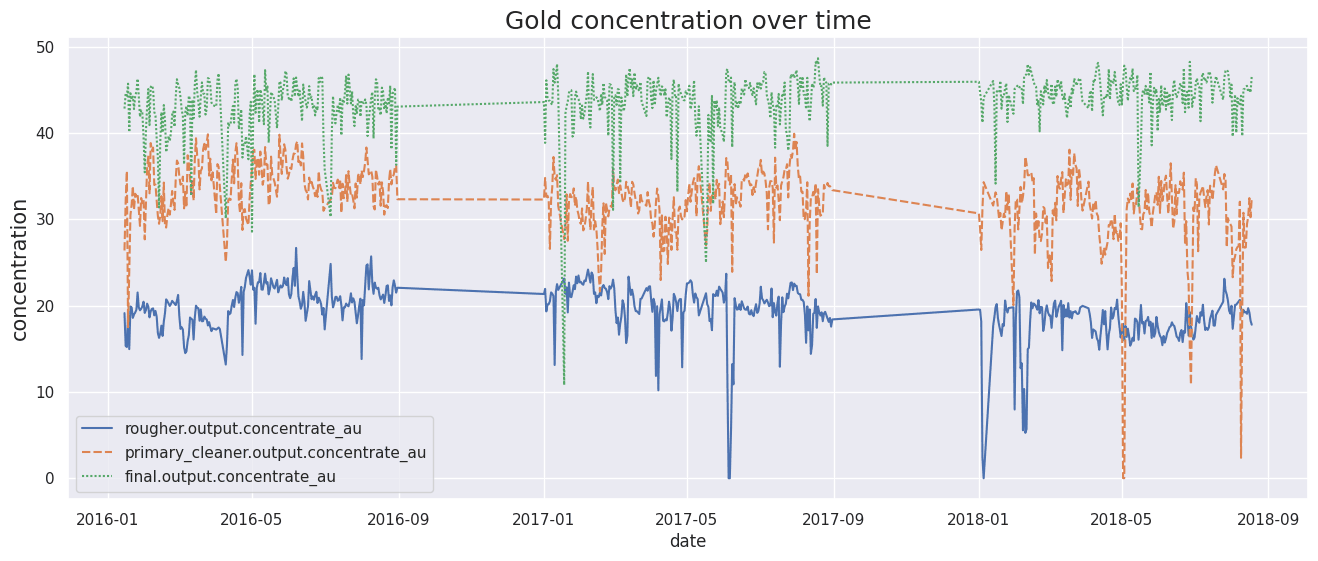

In [26]:
plot_met_time(met_concs[0], 'Gold concentration over time')

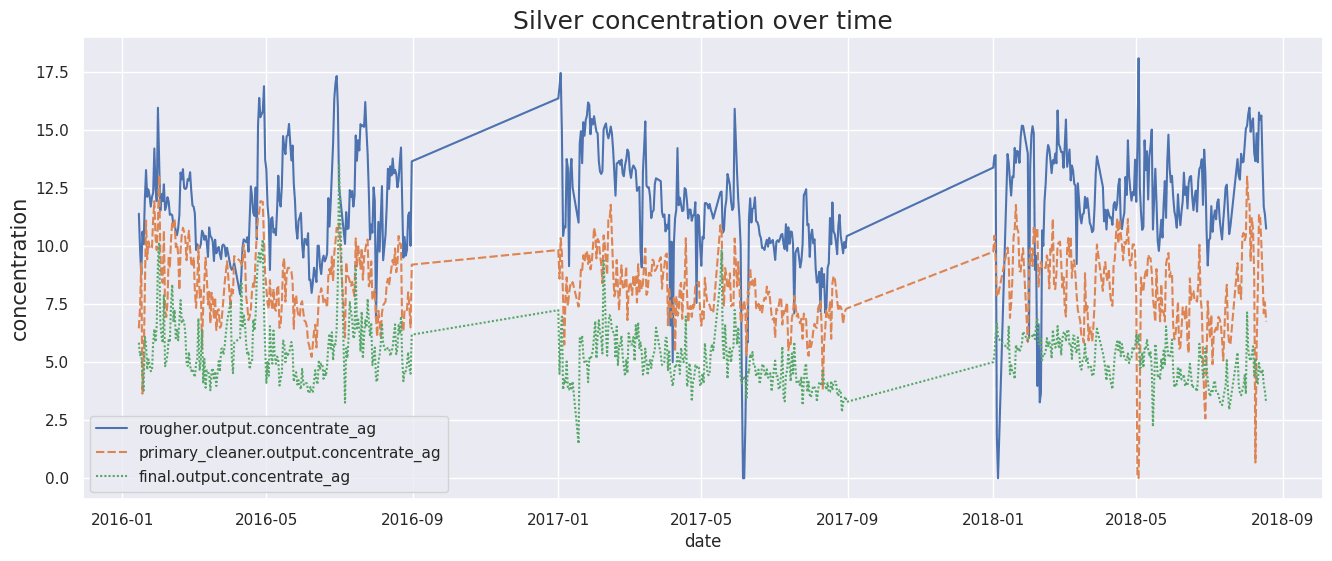

In [27]:
plot_met_time(met_concs[1], 'Silver concentration over time')

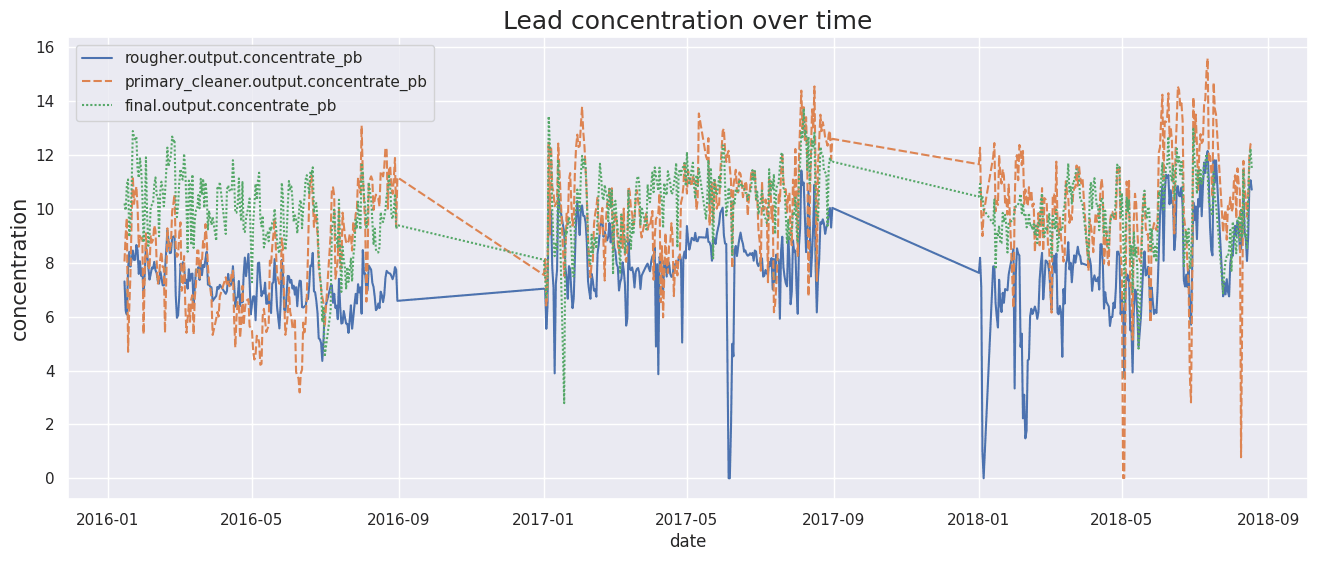

In [28]:
plot_met_time(met_concs[2], 'Lead concentration over time')

- The gold concentration grows with each cleaning stage, the silver concentration decreases, and the lead concentration grows slightly after flotation.
- The plots periodically drop to zero. These values are wrong: at those moments the concentration was not monitored or the data was lost. They should be removed.
- The straight lines on the plot correspond to the time intervals of the test set.
- Now look at each stage of the process separately.

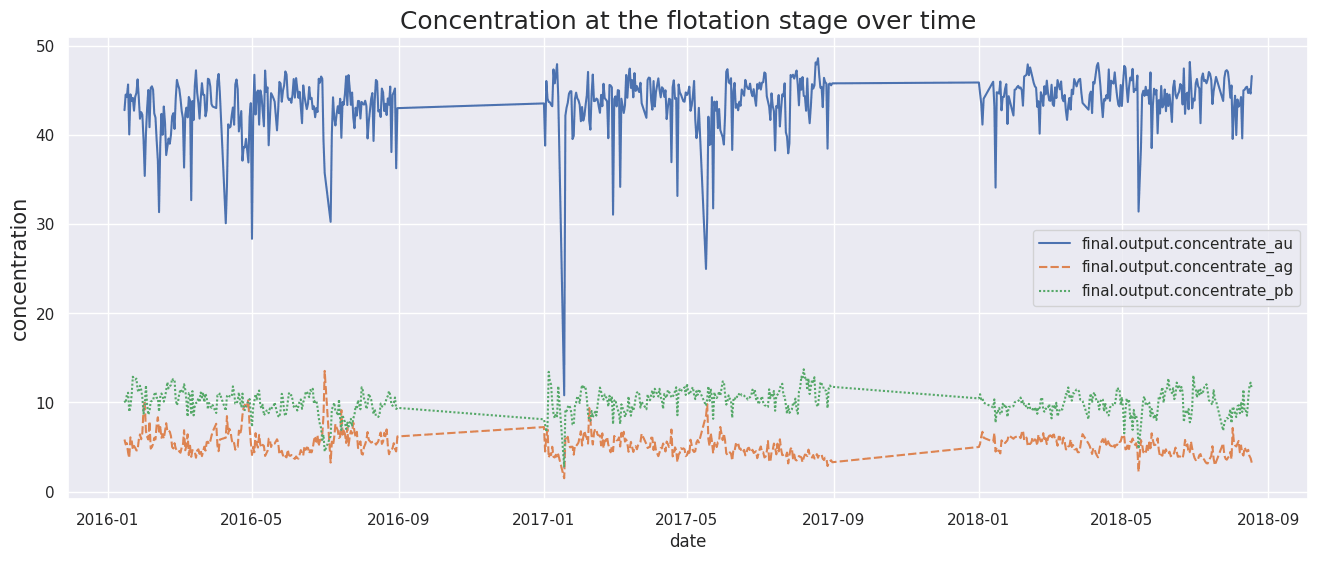

In [29]:
plot_met_time(met_concs[:,2], 'Concentration at the flotation stage over time')

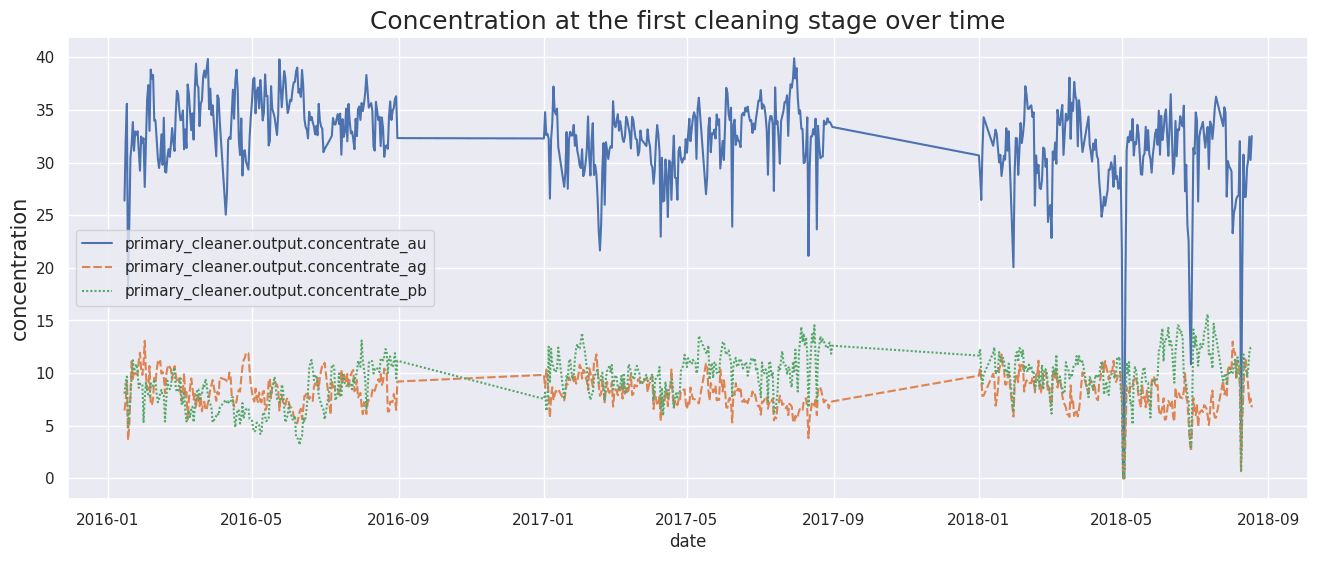

In [30]:
plot_met_time(met_concs[:,1], 'Concentration at the first cleaning stage over time')

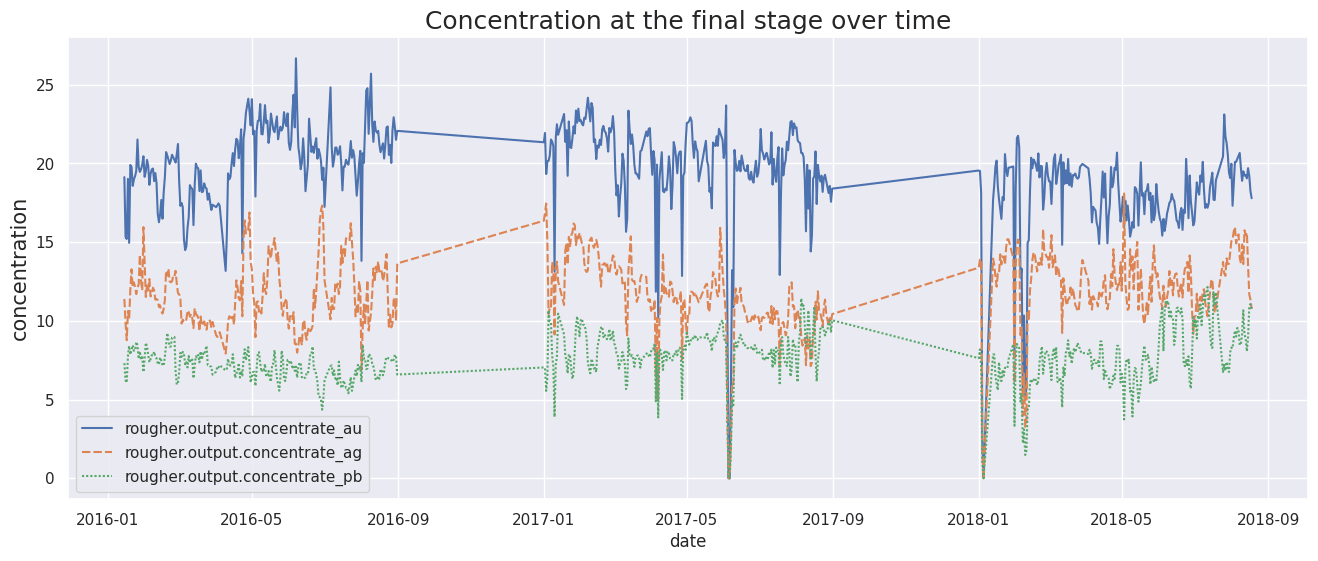

In [31]:
plot_met_time(met_concs[:,0], 'Concentration at the final stage over time')

- The plots show that the gold concentration in the mixture grows with each new cleaning stage.
- The gold concentration also grows relative to the other metals.
- On all plots the metal concentrations on average depend little on time. This indicates the stability of the process and of the raw material.
- Now look at the overall plot of the average values of all metals at all stages of the process.

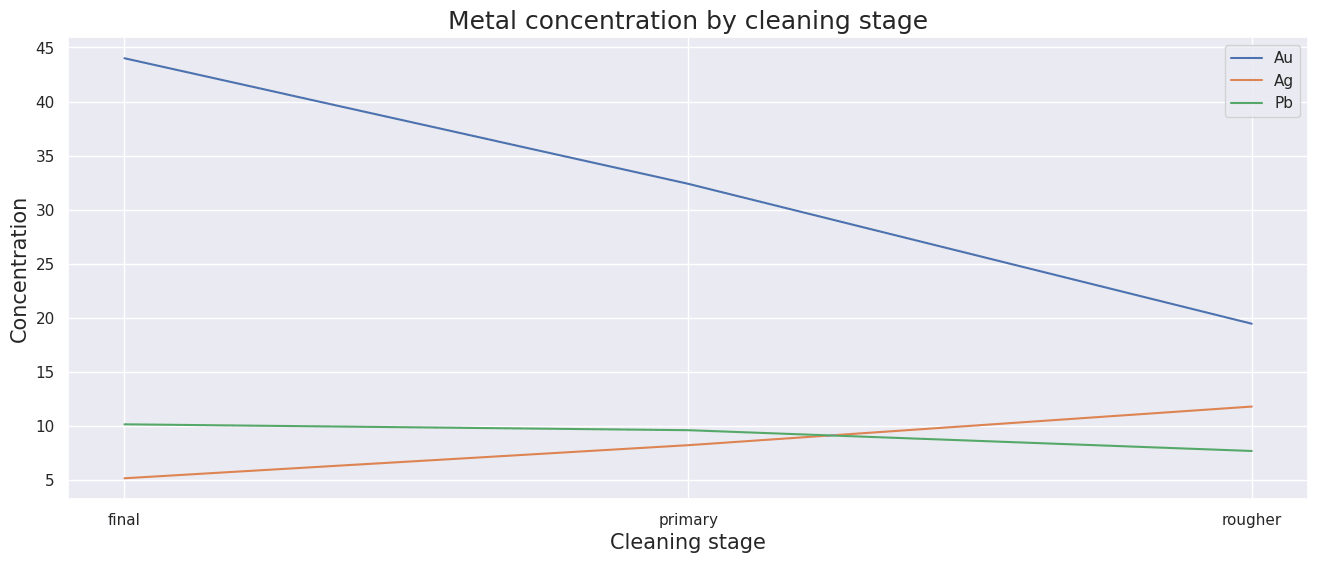

In [32]:
step_names = ['rougher', 'primary', 'final']
mets = ['Au', 'Ag', 'Pb']

sns.set()
f, axes = plt.subplots(1, 1, figsize=(16, 6))
axes.set_title('Metal concentration by cleaning stage', fontsize=18)
axes.set_ylabel('Concentration', fontsize=15)
axes.set_xlabel('Cleaning stage', fontsize=15)
for cols, met in zip(met_concs, mets):
    sns.lineplot(data = pd.Series(train[cols].mean().values, index=step_names),
                legend = 'full',
                label = met)
plt.gca().invert_xaxis()

- This plot confirms the conclusions made above. With each cleaning stage the gold concentration in the mixture grows, the silver concentration drops slightly, and the lead concentration grows slightly.

## 2.2 Comparison of the Feed Size Distributions

- Use histograms to compare the feed granule size distributions in the training and test sets.
- For a more accurate comparison take the daily average values of the granule size.

In [33]:
train_feed_size = train['rougher.input.feed_size'].groupby(train.index.floor('D')).agg('mean')
test_feed_size = test['rougher.input.feed_size'].groupby(test['rougher.input.feed_size'].index.floor('D')).agg('mean')

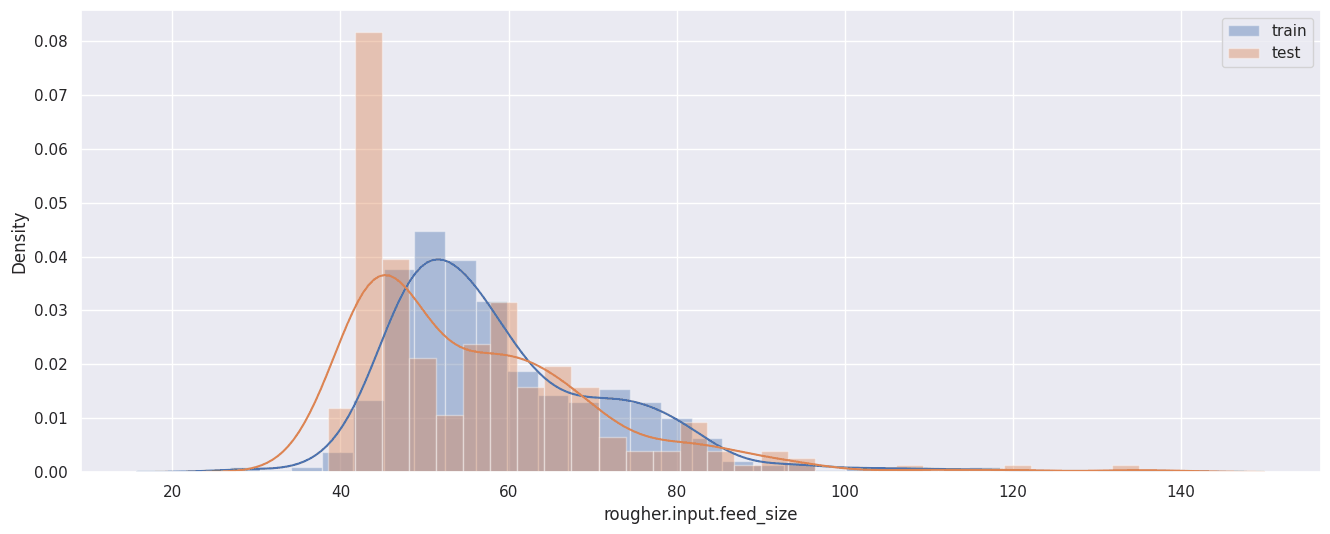

In [34]:
f, axes = plt.subplots(1, 1, figsize=(16, 6))
sns.distplot(train_feed_size.loc[train_feed_size < 150], bins=30, label='train')
sns.distplot(test_feed_size.loc[test_feed_size < 150], bins=30, label='test')
plt.legend()

- According to the plot, the values in both sets do not differ much.
- Test the hypothesis with a two-sided t-test. The variances of both distributions are assumed to be equal.
- Null hypothesis H0:
    - "The daily average granule size in the training set and in the test set are the same"
- Alternative hypothesis H1:
    - "The daily average granule size in the training set and in the test set are not equal"
- Significance level: `alpha = 0.05`
- Use the function `st.ttest_ind` to calculate the test statistic and the `p-value`.

In [35]:
results = st.ttest_ind(train_feed_size,
                       test_feed_size,
                       equal_var=True)
print('p-value: {:.3f}'.format(results.pvalue))

p-value: 0.002


- The p-value (0.002) is lower than the significance level 0.05. The null hypothesis must be rejected and the distributions considered different.
- Try to remove the outliers in the distributions and run the t-test again.

In [36]:
train_q_75 = train['rougher.input.feed_size'].quantile(0.75)
train_q_25 = train['rougher.input.feed_size'].quantile(0.25)
test_q_75 = test['rougher.input.feed_size'].quantile(0.75)
test_q_25 = test['rougher.input.feed_size'].quantile(0.25)
train_min = train_q_25 - 3 * (train_q_75 - train_q_25)
train_max = train_q_75 + 3 * (train_q_75 - train_q_25)
test_min = test_q_25 - 3 * (test_q_75 - test_q_25)
test_max = test_q_75 + 3 * (test_q_75 - test_q_25)
print('Training set:')
print('    Lower outlier bound: {:.2f}'.format(train_min))
print('    Upper outlier bound: {:.2f}'.format(train_max))
print('Test set:')
print('    Lower outlier bound: {:.2f}'.format(test_min))
print('    Upper outlier bound: {:.2f}'.format(test_max))

Training set:
    Lower outlier bound: -2.16
    Upper outlier bound: 117.14
Test set:
    Lower outlier bound: -11.73
    Upper outlier bound: 118.09


In [37]:
results = st.ttest_ind(train_feed_size.loc[(train_feed_size > train_min) &
                                           (train_feed_size < train_max)],
                       test_feed_size.loc[(test_feed_size > test_min) &
                                          (test_feed_size > test_min)],
                       equal_var=True)
print('p-value: {:.3f}'.format(results.pvalue))

p-value: 0.005


- Without the outliers the p-value is 0.005 < 0.05, so the null hypothesis is rejected again: the daily mean feed size differs statistically significantly between the training and the test set. The histogram shows that the test values are somewhat smaller, while the two distributions still overlap substantially.
- The feature "feed granule size" is kept for training the model. This shift between the training and the test data is a risk to keep in mind when interpreting the test results.

## 2.3 Study of the Total Concentrations of Substances

- Calculate the total concentrations of substances at the different stages (in the raw feed, after flotation and in the final concentrate after the two cleaning stages).

In [38]:
train['feed_conc'] = train['rougher.input.feed_ag'] + train['rougher.input.feed_pb'] +\
            train['rougher.input.feed_sol'] + train['rougher.input.feed_au']
train['rougher_conc'] = train['rougher.output.concentrate_ag'] + train['rougher.output.concentrate_pb'] +\
            train['rougher.output.concentrate_sol'] + train['rougher.output.concentrate_au']
train['final_conc'] = train['final.output.concentrate_ag'] + train['final.output.concentrate_pb'] +\
            train['final.output.concentrate_sol'] + train['final.output.concentrate_au']

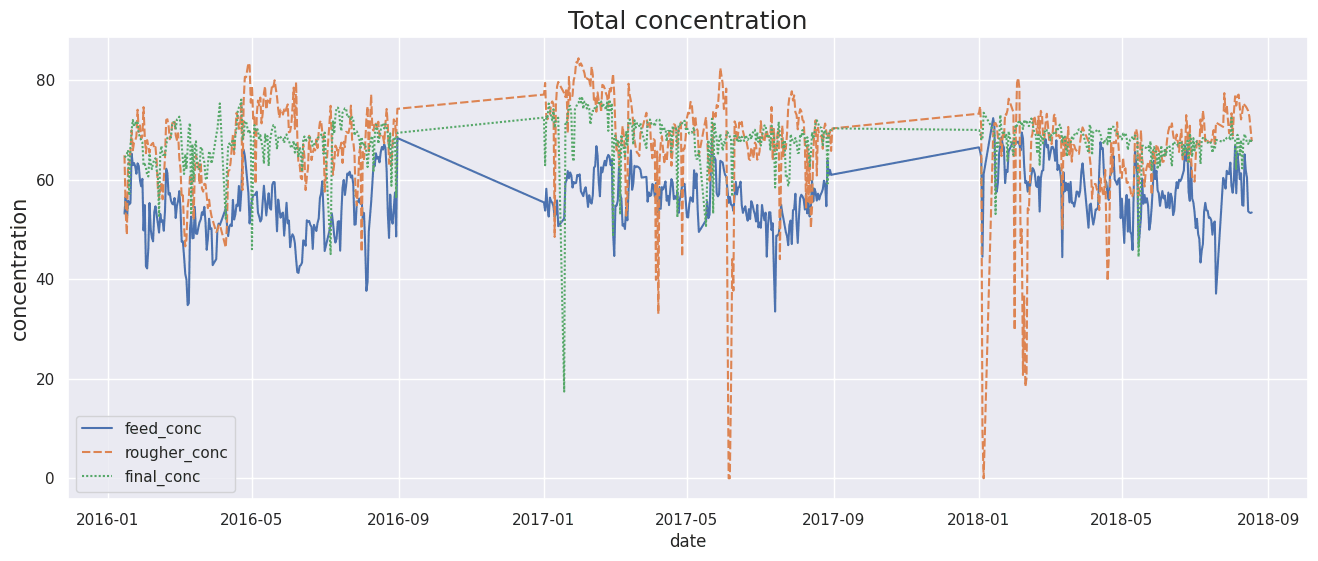

In [39]:
sum_conc_cols = ['feed_conc', 'rougher_conc', 'final_conc']
plot_met_time(sum_conc_cols, 'Total concentration')

- As in section 2.1, there are anomalies (a sharp drop of the total concentrations to 0). At those moments the target features were not recorded. The data is useless and must be removed.
- Remove all objects where at least one of the total concentrations (at the input, after flotation or at the output) is below 31.

In [40]:
before_len = len(train)
train = train.loc[(train['feed_conc'] > 31) &
                  (train['rougher_conc'] > 31) &
                  (train['final_conc'] > 31)]

In [41]:
print("Removed {} objects".format(before_len - len(train)))

Removed 733 objects


- Look at the total concentrations after removing the anomalous data.

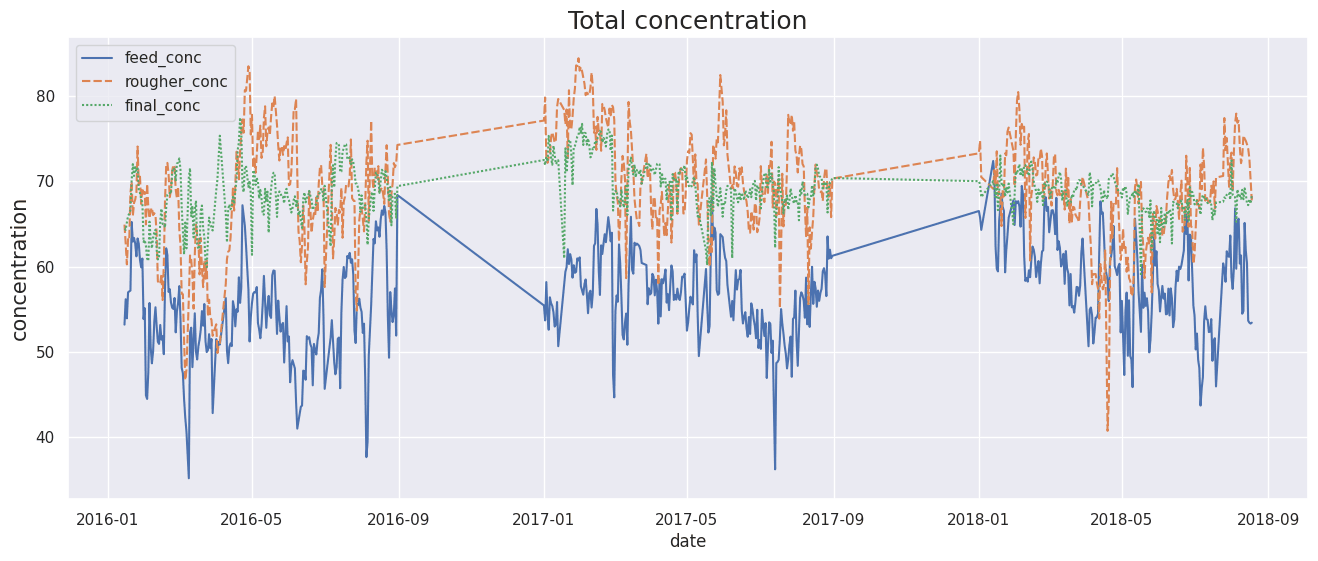

In [42]:
plot_met_time(sum_conc_cols, 'Total concentration')

In [43]:
train = train.drop(sum_conc_cols, axis = 1)

- The data is ready for building the model.

### Conclusions

- The metal concentrations (Au, Ag, Pb) at all cleaning stages are analyzed for the training set. Anomalies (a sharp drop of the concentrations to 0) are found. The straight lines on the plots show the time intervals of the test set.
- The feed granule size distributions at the input of the process are compared for the training and test sets. The two-sided t-test shows a statistically significant difference at the significance level 0.05 (p-value = 0.005 after removing the outliers), although the distributions overlap substantially. The feature is kept.
- The analysis of the total concentrations confirmed the presence of anomalous data. All objects with a total concentration of the mixture below 31 are removed from the training set. In total 733 objects (about 5% of the training set) are removed.

# 3. Model

- Look at the features of the training set with `info()`.

In [44]:
train[model_columns].info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 13415 entries, 2016-01-15 00:00:00 to 2018-08-18 10:59:59
Data columns (total 35 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   final.output.recovery                       13415 non-null  float64
 1   rougher.output.recovery                     13415 non-null  float64
 2   primary_cleaner.input.sulfate               13415 non-null  float64
 3   primary_cleaner.input.depressant            13415 non-null  float64
 4   primary_cleaner.input.feed_size             13415 non-null  float64
 5   primary_cleaner.input.xanthate              13415 non-null  float64
 6   primary_cleaner.state.floatbank8_a_air      13415 non-null  float64
 7   primary_cleaner.state.floatbank8_b_level    13415 non-null  float64
 8   primary_cleaner.state.floatbank8_d_air      13415 non-null  float64
 9   rougher.input.feed_ag                       1341

- Check whether the target feature `rougher.output.recovery` still has missing values.

In [45]:
train.loc[train['rougher.output.recovery'].isna(), model_columns].head(50)

,final.output.recovery,rougher.output.recovery,primary_cleaner.input.sulfate,primary_cleaner.input.depressant,primary_cleaner.input.feed_size,primary_cleaner.input.xanthate,primary_cleaner.state.floatbank8_a_air,primary_cleaner.state.floatbank8_b_level,primary_cleaner.state.floatbank8_d_air,rougher.input.feed_ag,...,secondary_cleaner.state.floatbank3_a_level,secondary_cleaner.state.floatbank3_b_air,secondary_cleaner.state.floatbank3_b_level,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
date,,,,,,,,,,,,,,,,,,,,,


- The table above is empty: after filling the gaps with the formula and removing the anomalies, the target features have no missing values left. The filters below are kept as a safety check.
- Create two separate training sets: for predicting the enrichment efficiency after flotation and after cleaning.

In [46]:
train_r = train.loc[~train['rougher.output.recovery'].isna()]
train_f = train.loc[~train['final.output.recovery'].isna()]

In [47]:
print('Number of objects in the flotation training set: {}'.format(len(train_r)))
print('Number of objects in the cleaning training set: {}'.format(len(train_f)))

Number of objects in the flotation training set: 13415
Number of objects in the cleaning training set: 13415


- Only the features that are available in the process at the moment when the parameter is calculated (features with the prefix `rougher`) can be used to predict the enrichment efficiency at the flotation stage.

In [48]:
rougher_columns = []
pattern = re.compile('rougher')
print('Features for predicting the enrichment efficiency at the flotation stage:')
for column in list(test.columns):
    if re.match(pattern, column):
        rougher_columns.append(column)
        print(' - ', column)

Features for predicting the enrichment efficiency at the flotation stage:
 -  rougher.input.feed_ag
 -  rougher.input.feed_pb
 -  rougher.input.feed_rate
 -  rougher.input.feed_size
 -  rougher.input.feed_sol
 -  rougher.input.feed_au
 -  rougher.input.floatbank11_sulfate
 -  rougher.input.floatbank11_xanthate
 -  rougher.state.floatbank10_a_air
 -  rougher.state.floatbank10_a_level
 -  rougher.state.floatbank10_c_air
 -  rougher.state.floatbank10_e_level
 -  rougher.state.floatbank10_f_air


## 3.1 The Final sMAPE Function

- Write the functions that calculate the quality metric final_smape (final symmetric mean absolute percentage error).

In [49]:
def smape(true, predict):
    """
    input:        true    - true values of the target feature
                  predict - model predictions
    output:       smape - symmetric mean absolute percentage error
    description:  the function calculates and returns the smape metric
                  from the true values of the target feature and the model predictions
    """
    return 1 / len(true) * sum( abs(true - predict) / ( (abs(true) + abs(predict)) * 0.5) ) * 100

In [50]:
def final_smape(smape_r, smape_f):
    """
    input:        smape_r - sMAPE of the model for the flotation (rougher) stage
                  smape_f - sMAPE of the model for the final (cleaner) stage
    output:       final smape - final symmetric mean absolute percentage error
    description:  the function calculates and returns the final sMAPE metric:
                  25% weight for the flotation stage and 75% weight for the final stage
    """
    return 0.25 * smape_r + 0.75 * smape_f

## 3.2 Training and Evaluating the Models

- The final metric final_smape depends linearly on the sMAPE after flotation and after cleaning. By optimizing each of them separately, the best value of the final metric can be reached. So the models can be trained and validated independently of each other.
- Select the features and the target features in the training set.

In [51]:
X_r = train_r[rougher_columns]
X_f = train_f[input_columns]
y_r = train_r['rougher.output.recovery']
y_f = train_f['final.output.recovery']
test_r = test[rougher_columns]
test_f = test[input_columns]

- Make sure that the training and test sets contain the same features.

In [52]:
print('Feature comparison for the flotation stage model:', set(X_r) == set(test_r))
print('Feature comparison for the cleaning stage model:', set(X_f) == set(test_f))

Feature comparison for the flotation stage model: True
Feature comparison for the cleaning stage model: True


- Scale the features of the training and test sets with `StandardScaler`.

In [53]:
ss_r = StandardScaler()
ss_f = StandardScaler()
ss_r.fit(X_r)
ss_f.fit(X_f)

X_r = pd.DataFrame(ss_r.transform(X_r), columns = rougher_columns)
X_f = pd.DataFrame(ss_f.transform(X_f), columns = input_columns)
test_f_ind = test.index
test_r_ind = test_r.index
test_r = pd.DataFrame(ss_r.transform(test_r), columns = rougher_columns, index = test_r_ind)
test_f = pd.DataFrame(ss_f.transform(test), columns = input_columns, index = test_f_ind)

- Two models must be trained, for the two target features `rougher.output.recovery` and `final.output.recovery`.
- Cross-validation is used to evaluate the model quality.

- **Linear Regression** model

In [54]:
# initialize the model
lm_r = LinearRegression()

# train the model for the flotation stage
smape_lm_r = cross_val_score(lm_r, X_r, y_r, 
                             scoring = make_scorer(smape),
                             cv = 5,
                             n_jobs = -1).mean()

In [55]:
lm_f = LinearRegression()

# train the model and evaluate it with cross-validation
smape_lm_f = cross_val_score(lm_f, X_f, y_f, 
                             scoring = make_scorer(smape),
                             cv = 5,
                             n_jobs = -1).mean()

In [56]:
print('Linear regression:')
print('    sMAPE rougher: {:.2f} %'.format(smape_lm_r))
print('    sMAPE cleaner: {:.2f} %'.format(smape_lm_f))
print('Final sMAPE: {:.2f} %'.format(final_smape(smape_lm_r, smape_lm_f)))

Linear regression:
    sMAPE rougher: 6.42 %
    sMAPE cleaner: 9.87 %
Final sMAPE: 9.01 %


- **Elastic-Net** model

- Select the hyperparameters with `GridSearchCV` from sklearn. It trains the model on all given combinations of hyperparameters using cross-validation and returns the combination with which the model reached the best value of the quality metric.

In [57]:
l1_ratios = np.linspace(0, 1, 11, endpoint=True)
alphas = np.linspace(0.1, 1, 10, endpoint=True)
param_grid = {'l1_ratio': l1_ratios,
              'alpha': alphas
             }
# initialize the ElasticNet model
en_r = ElasticNet()

# initialize GridSearchCV
grid_search_r = GridSearchCV(estimator = en_r, 
                           param_grid = param_grid, 
                           cv = 5, 
                           n_jobs = -1, 
                           verbose = 2, 
                           scoring = make_scorer(smape))
grid_search_r.fit(X_r, y_r)

print(grid_search_r.best_params_)
print('    sMAPE rougher: {:.2f} %'.format(grid_search_r.best_score_))

Fitting 5 folds for each of 110 candidates, totalling 550 fits


{'alpha': 1.0, 'l1_ratio': 1.0}
    sMAPE rougher: 6.66 %


In [58]:
# initialize the ElasticNet model
en_f = ElasticNet()

# initialize GridSearchCV
grid_search_f = GridSearchCV(estimator = en_f, 
                           param_grid = param_grid, 
                           cv = 5, 
                           n_jobs = -1, 
                           verbose = 2, 
                           scoring = make_scorer(smape))
grid_search_f.fit(X_f, y_f)

print(grid_search_f.best_params_)
print('    sMAPE cleaner:   {:.2f} %'.format(grid_search_f.best_score_))

Fitting 5 folds for each of 110 candidates, totalling 550 fits


{'alpha': 0.1, 'l1_ratio': 0.0}
    sMAPE cleaner:   9.16 %


- Try the **Lasso model** with L1 regularization, which can zero out uninformative coefficients, with `alpha=0.2` for the flotation stage and `alpha=0.4` for the cleaning stage.

In [59]:
ls_r = Lasso(alpha=0.2)
# train the model and evaluate it with cross-validation
smape_ls_r = cross_val_score(ls_r, X_r, y_r, 
                                scoring = make_scorer(smape),
                                cv = 5,
                                n_jobs = -1).mean()
smape_ls_r

6.220615566658262

In [60]:
ls_f = Lasso(alpha=0.4)
# train the model and evaluate it with cross-validation
smape_ls_f = cross_val_score(ls_f, X_f, y_f, 
                                scoring = make_scorer(smape),
                                cv = 5,
                                n_jobs = -1).mean()
smape_ls_f

8.745193496537315

In [61]:
print('Lasso model:')
print('    sMAPE rougher: {:.2f} %'.format(smape_ls_r))
print('    sMAPE cleaner: {:.2f} %'.format(smape_ls_f))

Lasso model:
    sMAPE rougher: 6.22 %
    sMAPE cleaner: 8.75 %


In [62]:
print('Final sMAPE: {:.2f} %'.format(final_smape(smape_ls_r, smape_ls_f)))

Final sMAPE: 8.11 %


- **Permutation importance**

- Try to improve the model quality by excluding the features that have little influence on the target feature. Use the permutation method: shuffle each feature in turn on the validation set and track the change in the prediction quality of the model. Use `permutation_importance` from sklearn.

In [63]:
def feature_reduction(X, y, alpha, num_features, label):
    """
    input:       X - features for the Lasso model
                 y - target feature
                 alpha - regularization parameter of the Lasso model
                 num_features - number of features to keep in the model
                 label - name of the stage of the process
    output:      chosen_cols - selected features for the model
                 smape_ls_red - smape value calculated for the model with cross-validation
    description: The function splits the input data into training and validation sets for the feature selection
                 by permutation. It uses `permutation_importance` from sklearn.
                 The features are printed in descending order of importance for the target feature (the mean
                 importance and the standard deviation are printed too). Then the num_features most important
                 features are selected. The Lasso model is trained on the new feature space with cross-validation.
                 The smape metric is printed.
    """
    # split the data into training and validation sets to calculate the feature importance
    X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size = 0.25, random_state = 42)
    
    # train the Lasso model
    ls = Lasso(alpha=alpha)
    ls.fit(X_train, y_train)
    
    # calculate the feature importance by permutation
    p_i = permutation_importance(ls, X_valid, y_valid,
                                 n_repeats=30,
                                 random_state=42)
    
    # print the features in descending order of importance
    for i in p_i.importances_mean.argsort()[::-1]:
        if p_i.importances_mean[i] - 2 * p_i.importances_std[i] > 0:
            print(f"{X_valid.columns[i]:<50}"
                  f"{p_i.importances_mean[i]:.3f}"
                  f" +/- {p_i.importances_std[i]:.3f}")  
    
    # train the model on all data with the reduced number of features
    chosen_cols = p_i.importances_mean.argsort()[::-1][:num_features]
    X_red = X.iloc[:, chosen_cols]
    smape_ls_red = cross_val_score(ls, X_red, y, 
                                    scoring = make_scorer(smape),
                                    cv = 5,
                                    n_jobs = -1).mean()
    print()
    print(' sMAPE {} : {:.2f} %'.format(label, smape_ls_red))    
    return chosen_cols, smape_ls_red

In [64]:
rougher_features, smape_ls_r_red = feature_reduction(X_r, y_r, alpha=0.2, num_features=7, label='rougher')

rougher.state.floatbank10_a_level                 0.116 +/- 0.006
rougher.input.feed_ag                             0.112 +/- 0.005
rougher.input.feed_sol                            0.071 +/- 0.004
rougher.input.floatbank11_xanthate                0.069 +/- 0.005
rougher.input.feed_pb                             0.040 +/- 0.003
rougher.input.floatbank11_sulfate                 0.028 +/- 0.002
rougher.state.floatbank10_c_air                   0.023 +/- 0.002
rougher.state.floatbank10_a_air                   0.005 +/- 0.001
rougher.state.floatbank10_f_air                   0.004 +/- 0.001
rougher.input.feed_rate                           0.004 +/- 0.001
rougher.state.floatbank10_e_level                 0.003 +/- 0.001
rougher.input.feed_au                             0.002 +/- 0.000

 sMAPE rougher : 5.82 %


In [65]:
cleaner_features, smape_ls_f_red = feature_reduction(X_f, y_f, alpha=0.4, num_features=10, label='cleaner')

rougher.input.floatbank11_xanthate                0.072 +/- 0.005
rougher.input.feed_au                             0.052 +/- 0.005
primary_cleaner.input.sulfate                     0.045 +/- 0.003
rougher.input.floatbank11_sulfate                 0.033 +/- 0.003
secondary_cleaner.state.floatbank3_a_air          0.018 +/- 0.002
rougher.input.feed_sol                            0.016 +/- 0.002
rougher.input.feed_ag                             0.009 +/- 0.002
primary_cleaner.state.floatbank8_a_air            0.007 +/- 0.002
rougher.state.floatbank10_c_air                   0.005 +/- 0.001
secondary_cleaner.state.floatbank4_a_air          0.002 +/- 0.000
primary_cleaner.input.feed_size                   0.001 +/- 0.000

 sMAPE cleaner : 8.61 %


In [66]:
print('Final sMAPE with cross-validation: {:.2f} %'.format(final_smape(smape_ls_r_red, smape_ls_f_red)))

Final sMAPE with cross-validation: 7.91 %


In [67]:
X_r_red = X_r.iloc[:,rougher_features]
print('Final features for the flotation stage model:')
print(pd.Series(X_r_red.columns))

Final features for the flotation stage model:
0     rougher.state.floatbank10_a_level
1                 rougher.input.feed_ag
2                rougher.input.feed_sol
3    rougher.input.floatbank11_xanthate
4                 rougher.input.feed_pb
5     rougher.input.floatbank11_sulfate
6       rougher.state.floatbank10_c_air
dtype: object


In [68]:
X_f_red = X_f.iloc[:,cleaner_features]
print('Final features for the cleaning stage model:')
print(pd.Series(X_f_red.columns))

Final features for the cleaning stage model:
0          rougher.input.floatbank11_xanthate
1                       rougher.input.feed_au
2               primary_cleaner.input.sulfate
3           rougher.input.floatbank11_sulfate
4    secondary_cleaner.state.floatbank3_a_air
5                      rougher.input.feed_sol
6                       rougher.input.feed_ag
7      primary_cleaner.state.floatbank8_a_air
8             rougher.state.floatbank10_c_air
9    secondary_cleaner.state.floatbank4_a_air
dtype: object


## 3.3 Testing the Model

- Check the model quality on the test set.

In [69]:
# save the target features of the test set from the original data
y_true_r = full.loc[test.index, 'rougher.output.recovery'].dropna()
y_true_f = full.loc[test.index, 'final.output.recovery'].dropna()
# create the test feature sets with valid indices for both stages
test_r = test_r.loc[y_true_r.index]
test_f = test_f.loc[y_true_f.index]
test_r = test_r[X_r_red.columns]
test_f = test_f[X_f_red.columns]

In [70]:
# initialize the Lasso models with the parameters selected earlier
model_r = Lasso(alpha=0.2)
model_f = Lasso(alpha=0.4)

# train the models and get the predictions
model_r.fit(X_r_red, y_r)
model_f.fit(X_f_red, y_f)
predict_r = model_r.predict(test_r)
predict_f = model_f.predict(test_f)

print('Flotation sMAPE on the test set: {:.2f} %'.format(smape(y_true_r, predict_r)))
print('Cleaning sMAPE on the test set:  {:.2f} %'.format(smape(y_true_f, predict_f)))
smape_fin = final_smape(smape(y_true_r, predict_r), smape(y_true_f, predict_f))
print('Final sMAPE on the test set: {:.2f} %'.format(smape_fin))

Flotation sMAPE on the test set: 8.15 %
Cleaning sMAPE on the test set:  8.88 %
Final sMAPE on the test set: 8.70 %


- Compare the resulting model with a constant model. Take the mean values of the target features in the training set and calculate the final sMAPE on the test data.

In [71]:
dummy_pred_r = np.array([train_r['rougher.output.recovery'].mean() for _ in range(len(y_true_r))])
dummy_pred_f = np.array([train_f['final.output.recovery'].mean() for _ in range(len(y_true_f))])

In [72]:
print('Constant model')
print('Flotation sMAPE on the test set: {:.2f} %'.format(smape(y_true_r, dummy_pred_r)))
print('Cleaning sMAPE on the test set:  {:.2f} %'.format(smape(y_true_f, dummy_pred_f)))
smape_dummy = final_smape(smape(y_true_r, dummy_pred_r), smape(y_true_f, dummy_pred_f))
print('Final sMAPE on the test set: {:.2f} %'.format(smape_dummy))

Constant model
Flotation sMAPE on the test set: 8.91 %
Cleaning sMAPE on the test set:  9.91 %
Final sMAPE on the test set: 9.66 %


- The sMAPE of the trained model is 1 percentage point lower than that of the constant model.

### Conclusions

- The data is used to train linear regression, ElasticNet and Lasso models.
- The models for the enrichment efficiency after flotation and after cleaning were optimized separately.
- Cross-validation is used to evaluate the model quality and GridSearchCV to find the optimal hyperparameters.
- The Lasso model gave the best cross-validation result (final sMAPE 8.11 % against 9.01 % for linear regression).
- The features for both models were also selected with the permutation method. Cross-validation after the selection:
    - sMAPE flotation: 5.82 %
    - sMAPE cleaning:  8.61 %
    - final sMAPE: 7.91 %
- sMAPE on the test set:
    - sMAPE flotation: 8.15 %
    - sMAPE cleaning:  8.88 %
    - **final sMAPE: 8.70 %**
- The final sMAPE of the constant model is 9.66 %.

# 4. Overall Conclusion

**1)**
- The data is analyzed successfully. The enrichment efficiency is calculated correctly.
- Features that are redundant and irrelevant for the model (some parameters that characterize the current state of the stages of the process) are selected and excluded. If the process changes, the behavior of these features may change and the model will have to be updated.
- The missing values of the relevant features are filled using the available historical data.

**2)**
- The metal concentrations (Au, Ag, Pb) and the total concentrations of substances at all cleaning stages are analyzed.
- The feed granule size distributions at the input of the process are compared for the training and test sets. The two-sided t-test shows a statistically significant difference at the significance level 0.05 (p-value = 0.005 after removing the outliers), although the distributions overlap substantially. The feature is kept.
- The analysis of the total concentrations confirmed the presence of anomalous data. All objects with a total concentration of the mixture below 31 are removed from the training set. In total 733 objects (about 5% of the training set) are removed.

**3)**
- The data is used to train linear regression, ElasticNet and Lasso models.
- The models for the enrichment efficiency after flotation and after cleaning were optimized separately.
- Cross-validation is used to evaluate the model quality and GridSearchCV to find the optimal hyperparameters.
- The features for both models are selected with the permutation method.
- sMAPE on the test set (Lasso model):
    - sMAPE flotation: 8.15 %
    - sMAPE cleaning:  8.88 %
    - **final sMAPE: 8.70 %**
- The sMAPE of the trained model is about 1 percentage point lower than that of the constant model (9.66 %).